# Chapter 6 — Linear Models and Regularization

*Chapter 4 studied a method that assumes almost nothing about the shape of the function and pays for it with variance. This chapter studies the opposite assumption: the world is, to a first approximation, linear. A model with $d + 1$ numbers can be fitted in closed form or in a few iterations, it can be analyzed completely, and its single knob, the strength of the regularization, is the cleanest example of the bias–variance trade-off.*

## 6.1 Learning objectives

Chapter 5 gave us the rules for evaluating and tuning a model, and used logistic regression and its hyperparameter $C$ as a black box. This chapter opens the box. It starts from the least-squares fit of Chapter 1, shows precisely when it is reliable and when it is not, repairs it with **ridge regression**, and then builds the classification counterpart: **logistic regression**, its **regularized** version, and its extension to more than two classes. Along the way, the tools of the previous chapters (the bias–variance decomposition of Chapter 4, the norm bounds of Chapter 3, the cross-validation of Chapter 5) turn into theorems and measurements about a concrete family of models.

After working through it you will be able to:

1. state and prove the **statistical properties of least squares**: it is unbiased, its covariance is $\sigma^2(\mathbf{X}^\top\mathbf{X})^{-1}$, it is the best linear unbiased estimator (Gauss–Markov), and each parameter costs exactly $\sigma^2/n$ of prediction error and $2\sigma^2/n$ of training-error optimism;
2. compute a least-squares solution **stably** (QR or SVD instead of the normal equations), and diagnose **collinearity** with the variance inflation factor;
3. derive **ridge regression**, express it with the **singular value decomposition**, define its **effective degrees of freedom**, compute its bias and variance exactly, and prove that some $\lambda > 0$ always beats least squares in estimation error;
4. choose $\lambda$ cheaply with the **leave-one-out shortcut**, and recognize the situations in which regularization does **not** help;
5. derive **logistic regression** as maximum likelihood for a Bernoulli model, prove that its loss is convex, and implement **Newton's method** (IRLS) from scratch;
6. explain what happens when the classes are **linearly separable** (the maximum-likelihood solution does not exist), how an $\ell_2$ penalty repairs it, and how $\lambda$ relates to scikit-learn's $C$;
7. extend the model to **many classes** with the softmax function, and inspect its weights as images;
8. obtain **nonlinear** models with linear tools through **feature maps**, see why regularization is indispensable when the number of features is large, and follow a complete protocol for linear models.

**Prerequisites.** Chapters 1 to 5. In particular the normal equations and the geometry of Section 1.6, maximum likelihood and the Gaussian-noise view of least squares (Section 2.6.7), the bias–variance decomposition (Section 4.5), the norm bounds of Section 3.8, the tuning protocols of Section 5.4, and the calibration of probabilities of Section 5.6.4.

:::{admonition} A word about the data in this chapter
:class: note
The experiments use real data sets: **Diabetes**, **Breast Cancer**, **Digits** and, for one demonstration, two classes of **Iris**, all shipped with scikit-learn. Three experiments need a situation in which the truth is known exactly, and they are flagged where they appear: a **simulation with Gaussian designs** that checks a formula (Section 6.2.1), a **numerical experiment** with a matrix of monomials (Section 6.2.3), and a **simulated world built on the real Diabetes design** in which the true coefficients are known (Section 6.3.3). In every other experiment, the data are real and the numbers that we report are measured, not simulated.
:::

### Setting up this notebook

As in the previous chapters, the next two cells print the versions of the libraries and define the plotting style and the random seed.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 6.2 Linear regression, revisited

In Section 1.6 we fitted $\hat y = \mathbf{w}^\top\mathbf{x} + b$ by minimizing the sum of squared errors, derived the normal equations and saw that the fit is an orthogonal projection. We now ask the questions of Chapters 3 to 5 about this estimator: how far is $\hat{\mathbf{w}}$ from the truth, how much prediction error do we pay for the number of parameters, and when can we trust the individual coefficients? The answers are exact, which makes least squares the best laboratory for the ideas of the book.

### 6.2.1 What kind of estimator is least squares?

To talk about the error of an estimator we need a model of how the data were generated. Throughout this section the **design matrix** $\mathbf{X} \in \mathbb{R}^{n \times p}$ is fixed (it includes a column of ones if we want an intercept, so $p = d + 1$) and has linearly independent columns, and the targets are

$$
\mathbf{y} = \mathbf{X}\mathbf{w}^\ast + \boldsymbol{\varepsilon},
\qquad \mathbb{E}[\boldsymbol\varepsilon] = \mathbf{0},
\qquad \operatorname{Cov}(\boldsymbol\varepsilon) = \sigma^2 \mathbf{I}_n .
$$

The vector $\mathbf{w}^\ast$ is the true coefficient vector and the noise terms are uncorrelated with the same variance $\sigma^2$ (no Gaussian assumption is needed for the next theorem). The randomness is in $\boldsymbol\varepsilon$ alone: a different training set means the same inputs with new noise. This is the *fixed-design* setting of the exact computation of Section 4.5.2. Write $\hat{\mathbf{w}} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$ and $\mathbf{H} = \mathbf{X}(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top$ for the hat matrix of Section 1.6.

**Theorem 6.1 (least squares under the linear model).**

1. *Unbiasedness.* $\mathbb{E}[\hat{\mathbf{w}}] = \mathbf{w}^\ast$.
2. *Covariance.* $\operatorname{Cov}(\hat{\mathbf{w}}) = \sigma^2(\mathbf{X}^\top\mathbf{X})^{-1}$.
3. *Gauss–Markov.* If $\tilde{\mathbf{w}} = \mathbf{A}\mathbf{y}$ is any other linear unbiased estimator, then $\operatorname{Cov}(\tilde{\mathbf{w}}) - \operatorname{Cov}(\hat{\mathbf{w}})$ is positive semidefinite: no linear unbiased estimator has smaller variance in any direction.
4. *Errors.* Let $\mathbf{y}' = \mathbf{X}\mathbf{w}^\ast + \boldsymbol\varepsilon'$ be a fresh set of targets at the same inputs, with $\boldsymbol\varepsilon'$ independent of $\boldsymbol\varepsilon$. Then
$$
\mathbb{E}\Big[\tfrac1n\lVert \mathbf{X}\hat{\mathbf{w}} - \mathbf{X}\mathbf{w}^\ast\rVert^2\Big] = \sigma^2\,\frac{p}{n},
\qquad
\mathbb{E}\Big[\tfrac1n\lVert \mathbf{y} - \mathbf{X}\hat{\mathbf{w}}\rVert^2\Big] = \sigma^2\Big(1 - \frac{p}{n}\Big),
\qquad
\mathbb{E}\Big[\tfrac1n\lVert \mathbf{y}' - \mathbf{X}\hat{\mathbf{w}}\rVert^2\Big] = \sigma^2\Big(1 + \frac{p}{n}\Big).
$$
5. *Variance estimate.* $\hat\sigma^2 = \lVert\mathbf{y} - \mathbf{X}\hat{\mathbf{w}}\rVert^2/(n - p)$ is an unbiased estimate of $\sigma^2$.

:::{admonition} Proof
:class: dropdown
Since $\hat{\mathbf{w}} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top(\mathbf{X}\mathbf{w}^\ast + \boldsymbol\varepsilon) = \mathbf{w}^\ast + (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\boldsymbol\varepsilon$, we have
$$
\hat{\mathbf{w}} - \mathbf{w}^\ast = \mathbf{M}\boldsymbol\varepsilon, \qquad \mathbf{M} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top .
$$

*(1)* $\mathbb{E}[\mathbf{M}\boldsymbol\varepsilon] = \mathbf{M}\,\mathbb{E}[\boldsymbol\varepsilon] = \mathbf{0}$.

*(2)* $\operatorname{Cov}(\mathbf{M}\boldsymbol\varepsilon) = \mathbf{M}(\sigma^2\mathbf{I})\mathbf{M}^\top = \sigma^2(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{X}(\mathbf{X}^\top\mathbf{X})^{-1} = \sigma^2(\mathbf{X}^\top\mathbf{X})^{-1}$.

*(3)* Write $\mathbf{A} = \mathbf{M} + \mathbf{D}$. Then $\mathbb{E}[\tilde{\mathbf{w}}] = \mathbf{A}\mathbf{X}\mathbf{w}^\ast = \mathbf{w}^\ast + \mathbf{D}\mathbf{X}\mathbf{w}^\ast$, and unbiasedness for every $\mathbf{w}^\ast$ forces $\mathbf{D}\mathbf{X} = \mathbf{0}$. Therefore $\mathbf{D}\mathbf{M}^\top = \mathbf{D}\mathbf{X}(\mathbf{X}^\top\mathbf{X})^{-1} = \mathbf{0}$, and
$$
\operatorname{Cov}(\tilde{\mathbf{w}}) = \sigma^2(\mathbf{M} + \mathbf{D})(\mathbf{M} + \mathbf{D})^\top = \sigma^2\mathbf{M}\mathbf{M}^\top + \sigma^2\mathbf{D}\mathbf{D}^\top = \operatorname{Cov}(\hat{\mathbf{w}}) + \sigma^2\mathbf{D}\mathbf{D}^\top,
$$
because the cross terms vanish. The matrix $\mathbf{D}\mathbf{D}^\top$ is positive semidefinite.

*(4)* The matrix $\mathbf{H}$ is symmetric and idempotent ($\mathbf{H}^2 = \mathbf{H}$), $\mathbf{H}\mathbf{X} = \mathbf{X}$, and its trace is $\operatorname{tr}\mathbf{H} = \operatorname{tr}\big((\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{X}\big) = \operatorname{tr}\mathbf{I}_p = p$. Moreover $\mathbf{X}\hat{\mathbf{w}} = \mathbf{H}\mathbf{y} = \mathbf{X}\mathbf{w}^\ast + \mathbf{H}\boldsymbol\varepsilon$. For a fixed matrix $\mathbf{B}$ and uncorrelated noise, $\mathbb{E}\lVert\mathbf{B}\boldsymbol\varepsilon\rVert^2 = \sigma^2\operatorname{tr}(\mathbf{B}^\top\mathbf{B})$. Hence
$$
\mathbb{E}\lVert\mathbf{X}\hat{\mathbf{w}} - \mathbf{X}\mathbf{w}^\ast\rVert^2 = \sigma^2\operatorname{tr}(\mathbf{H}^\top\mathbf{H}) = \sigma^2 p .
$$
The residual is $\mathbf{y} - \mathbf{X}\hat{\mathbf{w}} = (\mathbf{I} - \mathbf{H})\boldsymbol\varepsilon$ and $\mathbf{I} - \mathbf{H}$ is also symmetric idempotent with trace $n - p$, so $\mathbb{E}\lVert\mathbf{y} - \mathbf{X}\hat{\mathbf{w}}\rVert^2 = \sigma^2(n - p)$. For the fresh targets, $\mathbf{y}' - \mathbf{X}\hat{\mathbf{w}} = \boldsymbol\varepsilon' - \mathbf{H}\boldsymbol\varepsilon$, and since $\boldsymbol\varepsilon'$ is independent of $\boldsymbol\varepsilon$ with mean zero, the cross term has expectation zero: $\mathbb{E}\lVert\boldsymbol\varepsilon' - \mathbf{H}\boldsymbol\varepsilon\rVert^2 = n\sigma^2 + \sigma^2 p$.

*(5)* is the second formula of (4) divided by $n - p$ instead of $n$. $\square$
:::

Read the fourth item as a price list. **Every parameter costs $\sigma^2/n$ of excess prediction error**, whatever the data look like: with $n = 100$ examples and $p = 10$ parameters the excess error is $10\%$ of the noise variance, with $p = 50$ it is $50\%$. This is the estimation error of Section 3.3 in closed form, and it is the same phenomenon as the variance $\sigma^2/k$ of the $k$-nearest-neighbor regressor of Section 4.5.2, with the number of parameters $p$ playing the role of the "number of effective examples averaged" $n/k$. The training error is *optimistic* by exactly the difference of the last two expectations,

$$
\mathbb{E}[\text{fresh error}] - \mathbb{E}[\text{training error}] = \frac{2\sigma^2 p}{n},
$$

the quantity that Chapter 3 could only bound and that Chapter 5 estimated by cross-validation. The optimism is proportional to the number of parameters, the same $p$ that appears in the variance, and it vanishes as $n \to \infty$ at the rate $1/n$.

We check the theorem with a **simulation, flagged as such** because the truth is known by construction: Gaussian inputs, $n = 100$, unit noise variance, and $p$ from 1 to 80. Because $\mathbf{X}\hat{\mathbf{w}} - \mathbf{X}\mathbf{w}^\ast = \mathbf{H}\boldsymbol\varepsilon$ and the residual is $(\mathbf{I}-\mathbf{H})\boldsymbol\varepsilon$, we do not even need $\mathbf{w}^\ast$.

In [3]:
def simulate_ols(n, p, reps=4000, seed=SEED):
    """Monte Carlo check of Theorem 6.1(4) for a fixed Gaussian design and sigma = 1."""
    rng = np.random.default_rng(seed + p)
    X = rng.standard_normal((n, p))
    Q, _ = np.linalg.qr(X)
    H = Q @ Q.T                                   # hat matrix (an orthonormal basis of the column space is enough)
    E = rng.standard_normal((reps, n))            # training noise, one row per repetition
    E_new = rng.standard_normal((reps, n))        # fresh noise at the same inputs
    HE = E @ H                                    # H is symmetric, so rows of E @ H are (H e)^T
    return {
        "p": p,
        "excess error (measured)": np.mean(np.sum(HE ** 2, axis=1)) / n,
        "excess error (theory p/n)": p / n,
        "training error (measured)": np.mean(np.sum((E - HE) ** 2, axis=1)) / n,
        "training error (theory 1-p/n)": 1 - p / n,
        "fresh error (measured)": np.mean(np.sum((E_new - HE) ** 2, axis=1)) / n,
        "fresh error (theory 1+p/n)": 1 + p / n,
    }

n_sim = 100
ols_table = pd.DataFrame([simulate_ols(n_sim, p) for p in [1, 5, 10, 20, 50, 80]]).set_index("p")
print(ols_table.round(3).to_string())

    excess error (measured)  excess error (theory p/n)  training error (measured)  training error (theory 1-p/n)  fresh error (measured)  fresh error (theory 1+p/n)
p                                                                                                                                                                   
1                     0.010                       0.01                      0.990                           0.99                   1.009                        1.01
5                     0.050                       0.05                      0.951                           0.95                   1.051                        1.05
10                    0.101                       0.10                      0.901                           0.90                   1.104                        1.10
20                    0.198                       0.20                      0.800                           0.80                   1.197                        1.20
50        

The measured values agree with the theory to within 0.005 in every row, including the extreme case $p = 80$, in which the training error is only $0.2$ of the noise variance while the error on fresh targets is $1.8$ times larger than the noise variance. Figure 6.1 shows the same numbers as functions of $p/n$.

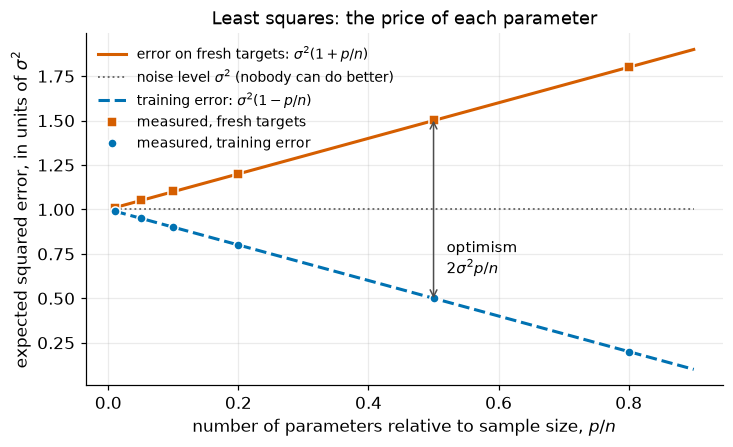

In [4]:
# Figure 6.1 — what the number of parameters costs
def figure_6_1():
    ps = np.arange(1, 91)
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ax.plot(ps / n_sim, 1 + ps / n_sim, color=VERMILION, lw=2, label=r"error on fresh targets: $\sigma^2(1+p/n)$")
    ax.plot(ps / n_sim, np.ones_like(ps, dtype=float), color="0.4", lw=1.2, ls=":", label=r"noise level $\sigma^2$ (nobody can do better)")
    ax.plot(ps / n_sim, 1 - ps / n_sim, color=BLUE, lw=2, ls="--", label=r"training error: $\sigma^2(1-p/n)$")
    ax.plot(ols_table.index / n_sim, ols_table["fresh error (measured)"], "s", color=VERMILION, ms=6, mec="white", label="measured, fresh targets")
    ax.plot(ols_table.index / n_sim, ols_table["training error (measured)"], "o", color=BLUE, ms=6, mec="white", label="measured, training error")
    ax.annotate("", xy=(0.5, 1.5), xytext=(0.5, 0.5), arrowprops=dict(arrowstyle="<->", color="0.3", shrinkA=0, shrinkB=0))
    ax.text(0.52, 0.72, "optimism\n" + r"$2\sigma^2 p/n$", fontsize=10, ha="left", va="center")
    ax.set(xlabel=r"number of parameters relative to sample size, $p/n$",
           ylabel=r"expected squared error, in units of $\sigma^2$",
           title="Least squares: the price of each parameter")
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    fig.tight_layout()
    plt.show()

figure_6_1()

### Worked example 6.1 — the variance of the three-point fit

Return to the three points $(0, 1)$, $(1, 3)$, $(2, 4)$ of Worked example 1.2, with $\mathbf{X}$ having a column of ones and a column $(0, 1, 2)$. We found $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 3 & 3 \\ 3 & 5 \end{pmatrix}$ and $\hat{\mathbf{w}} = (7/6,\ 3/2)^\top$. Let us compute everything that Theorem 6.1 promises.

*Step 1: the covariance.* The inverse is $(\mathbf{X}^\top\mathbf{X})^{-1} = \frac16\begin{pmatrix} 5 & -3 \\ -3 & 3 \end{pmatrix}$, so
$$
\operatorname{Var}(\hat w_0) = \tfrac56\sigma^2, \qquad \operatorname{Var}(\hat w_1) = \tfrac12\sigma^2, \qquad \operatorname{Cov}(\hat w_0, \hat w_1) = -\tfrac12\sigma^2 .
$$
The covariance is negative: a line fitted through these points that happens to be steeper than the truth must also have a lower intercept, because it must still pass near the center of the data.

*Step 2: the noise level.* The residuals are $\mathbf{r} = (-\tfrac16, \tfrac13, -\tfrac16)$ with $\sum r_i^2 = \tfrac16$, and $n - p = 3 - 2 = 1$, hence $\hat\sigma^2 = \tfrac16$. The standard error of the slope is $\sqrt{\tfrac12\cdot\tfrac16} = \sqrt{1/12} \approx 0.289$, and $t = \hat w_1 / \mathrm{SE} = 1.5/0.289 \approx 5.20$. With a single degree of freedom the two-sided $p$-value is $0.121$: three points cannot establish a slope, even a visibly positive one.

*Step 3: the leverages and the leave-one-out errors.* The diagonal of the hat matrix is $h_{ii} = \mathbf{x}_i^\top(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{x}_i$, so $h_{11} = \tfrac56$, $h_{22} = \tfrac13$, $h_{33} = \tfrac56$, which add up to $p = 2$, as they must. The residual that we would obtain by *removing point $i$, refitting, and predicting it* is $e_i/(1 - h_{ii})$ (the formula of Exercise 5.5), which gives $-1$, $\tfrac12$ and $-1$. Check the first: without the point $(0, 1)$ the line through $(1, 3)$ and $(2, 4)$ is $y = 2 + x$, which predicts $2$ at $x = 0$, an error of $1 - 2 = -1$. The leave-one-out mean squared error is $(1 + \tfrac14 + 1)/3 = 0.75$, against the training MSE of $\tfrac1{18} = 0.056$: the training error is more than 13 times more optimistic than the honest one.

In [5]:
X_toy = np.array([[1.0, 0.0], [1.0, 1.0], [1.0, 2.0]])
y_toy = np.array([1.0, 3.0, 4.0])
n_toy, p_toy = X_toy.shape

XtX_inv = np.linalg.inv(X_toy.T @ X_toy)
w_toy = XtX_inv @ X_toy.T @ y_toy
e_toy = y_toy - X_toy @ w_toy
sigma2_hat = e_toy @ e_toy / (n_toy - p_toy)
se = np.sqrt(sigma2_hat * np.diag(XtX_inv))
t_slope = w_toy[1] / se[1]
p_value = 2 * stats.t.sf(abs(t_slope), df=n_toy - p_toy)
print("(X^T X)^-1 * 6 =\n", np.round(6 * XtX_inv, 6))
print(f"sigma^2 hat = {sigma2_hat:.4f} (expected 1/6 = {1/6:.4f});  SE of the slope = {se[1]:.4f};  t = {t_slope:.3f};  p-value = {p_value:.3f}")

h = np.einsum("ij,jk,ik->i", X_toy, XtX_inv, X_toy)      # diagonal of the hat matrix without forming H
print("leverages h_ii =", np.round(h, 4), " sum =", h.sum())
loo_shortcut = e_toy / (1 - h)

loo_brute = []                                            # refit without each point, predict it
for i in range(n_toy):
    keep = np.arange(n_toy) != i
    w_i = np.linalg.lstsq(X_toy[keep], y_toy[keep], rcond=None)[0]
    loo_brute.append(y_toy[i] - X_toy[i] @ w_i)
print("leave-one-out residuals, shortcut :", np.round(loo_shortcut, 4))
print("leave-one-out residuals, brute force:", np.round(loo_brute, 4))
print(f"LOO MSE = {np.mean(loo_shortcut**2):.3f}   training MSE = {np.mean(e_toy**2):.4f}")

(X^T X)^-1 * 6 =
 [[ 5. -3.]
 [-3.  3.]]
sigma^2 hat = 0.1667 (expected 1/6 = 0.1667);  SE of the slope = 0.2887;  t = 5.196;  p-value = 0.121
leverages h_ii = [0.8333 0.3333 0.8333]  sum = 1.9999999999999998
leave-one-out residuals, shortcut : [-1.   0.5 -1. ]
leave-one-out residuals, brute force: [-1.   0.5 -1. ]
LOO MSE = 0.750   training MSE = 0.0556


### 6.2.2 Standard errors on real data

Theorem 6.1 turns into a practical tool when $\sigma^2$ is replaced by $\hat\sigma^2$: the **standard error** of the coefficient $\hat w_j$ is $\widehat{\mathrm{SE}}(\hat w_j) = \hat\sigma\sqrt{[(\mathbf{X}^\top\mathbf{X})^{-1}]_{jj}}$, and if the noise is Gaussian (or $n - p$ is large) the ratio $t_j = \hat w_j/\widehat{\mathrm{SE}}(\hat w_j)$ follows approximately a Student $t$ distribution with $n - p$ degrees of freedom when the true coefficient is zero. We compute them for the Diabetes data of Section 1.5, **standardizing the ten features** (mean 0 and standard deviation 1) so that each coefficient reads "change of the disease progression for an increase of one standard deviation of the feature". Standardization does not change the fitted values, only the units of the coefficients. (We standardize here with all the 442 patients because we are *describing* the fit, not evaluating a model; when we predict, the scaler goes inside the pipeline, as always.)

In [6]:
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler

diab = load_diabetes(as_frame=True)
feature_names = list(diab.data.columns)
y_diab = diab.target.to_numpy()
Z_diab = StandardScaler().fit_transform(diab.data)                  # (442, 10), each column: mean 0, sd 1
n_d, d_d = Z_diab.shape

A_d = np.column_stack([np.ones(n_d), Z_diab])                       # design matrix with intercept, p = 11
p_d = A_d.shape[1]
w_ols = np.linalg.lstsq(A_d, y_diab, rcond=None)[0]
resid = y_diab - A_d @ w_ols
sigma2_d = resid @ resid / (n_d - p_d)
cov_ols = sigma2_d * np.linalg.inv(A_d.T @ A_d)
se_ols = np.sqrt(np.diag(cov_ols))
t_ols = w_ols / se_ols
p_ols = 2 * stats.t.sf(np.abs(t_ols), df=n_d - p_d)
half = stats.t.ppf(0.975, df=n_d - p_d) * se_ols

table = pd.DataFrame({"coef": w_ols, "SE": se_ols, "t": t_ols, "p-value": p_ols,
                      "CI low": w_ols - half, "CI high": w_ols + half}, index=["intercept"] + feature_names)
print(table.round(3).to_string())
r2_d = 1 - resid @ resid / np.sum((y_diab - y_diab.mean()) ** 2)
print(f"\nsigma_hat = {np.sqrt(sigma2_d):.2f} (the standard deviation of y is {y_diab.std():.2f});  R^2 = {r2_d:.3f}")

              coef      SE       t  p-value   CI low  CI high
intercept  152.133   2.576  59.061    0.000  147.071  157.196
age         -0.476   2.842  -0.168    0.867   -6.062    5.110
sex        -11.407   2.912  -3.917    0.000  -17.130   -5.683
bmi         24.727   3.165   7.813    0.000   18.506   30.947
bp          15.429   3.112   4.958    0.000    9.313   21.546
s1         -37.680  19.819  -1.901    0.058  -76.635    1.275
s2          22.676  16.126   1.406    0.160   -9.019   54.372
s3           4.806  10.109   0.475    0.635  -15.063   24.675
s4           8.422   7.681   1.097    0.273   -6.674   23.518
s5          35.734   8.176   4.370    0.000   19.664   51.805
s6           3.217   3.139   1.025    0.306   -2.952    9.385

sigma_hat = 54.15 (the standard deviation of y is 77.01);  R^2 = 0.518


Four features (`sex`, `bmi`, `bp` and `s5`) have $|t| > 3.9$ and tiny $p$-values. The standard errors of `age`, `sex`, `bmi`, `bp` and `s6` are all close to 3 (in units of the target), while those of `s1` to `s5` lie between 7.7 and 19.8. The two largest belong to `s1` and `s2`, which have coefficients of **opposite signs** ($-37.7$ and $+22.7$) and individually insignificant $t$-statistics, although the fit as a whole is clearly informative. This is a symptom, and it is the subject of Section 6.2.4. Before that, a computational interlude: how should the solution be computed?

### 6.2.3 Computing least squares: why not the normal equations?

The normal equations $\mathbf{X}^\top\mathbf{X}\mathbf{w} = \mathbf{X}^\top\mathbf{y}$ are the right way to *derive* least squares and often the wrong way to *compute* it. The reason is the **condition number** of Section 2.3.8, the ratio $\kappa(\mathbf{X}) = \sigma_{\max}/\sigma_{\min}$ of the largest and the smallest singular value, which measures how much the relative error of the input can be amplified in the solution. With the singular value decomposition $\mathbf{X} = \mathbf{U}\boldsymbol\Sigma\mathbf{V}^\top$,

$$
\mathbf{X}^\top\mathbf{X} = \mathbf{V}\boldsymbol\Sigma^2\mathbf{V}^\top
\qquad\Longrightarrow\qquad
\kappa(\mathbf{X}^\top\mathbf{X}) = \kappa(\mathbf{X})^2 .
$$

Forming $\mathbf{X}^\top\mathbf{X}$ **squares** the condition number, so the normal equations lose about *twice* as many digits as are necessary. Two alternatives work on $\mathbf{X}$ itself:

- **QR decomposition.** Write $\mathbf{X} = \mathbf{Q}\mathbf{R}$ with $\mathbf{Q}$ having orthonormal columns and $\mathbf{R}$ upper triangular. Then $\mathbf{X}^\top\mathbf{X} = \mathbf{R}^\top\mathbf{R}$ and the normal equations reduce to the triangular system $\mathbf{R}\mathbf{w} = \mathbf{Q}^\top\mathbf{y}$, solved by back-substitution, without ever forming $\mathbf{X}^\top\mathbf{X}$.
- **SVD.** $\hat{\mathbf{w}} = \mathbf{V}\boldsymbol\Sigma^{-1}\mathbf{U}^\top\mathbf{y}$. It is the slowest of the three and the most robust, because it also handles rank-deficient matrices (small singular values can be discarded). It is what `np.linalg.lstsq` uses.

We compare the three on a **numerical experiment, flagged as a construction**: the columns of $\mathbf{X}$ are the monomials $1, x, x^2, \dots, x^m$ at 50 equally spaced points of $[0, 1]$ (a matrix whose columns become more and more alike as $m$ grows), the true coefficients are all equal to 1, and $\mathbf{y} = \mathbf{X}\mathbf{w}^\ast$ **exactly**, so that the only source of error is the arithmetic.

In [7]:
from scipy.linalg import solve_triangular

x_grid = np.linspace(0, 1, 50)
rows = []
for degree in [3, 6, 9, 12, 15]:
    V_mat = np.vander(x_grid, degree + 1, increasing=True)             # columns 1, x, ..., x^degree
    w_true = np.ones(degree + 1)
    y_exact = V_mat @ w_true

    w_normal = np.linalg.solve(V_mat.T @ V_mat, V_mat.T @ y_exact)     # normal equations
    Q_mat, R_mat = np.linalg.qr(V_mat)
    w_qr = solve_triangular(R_mat, Q_mat.T @ y_exact)                  # QR
    w_svd = np.linalg.lstsq(V_mat, y_exact, rcond=None)[0]             # SVD

    rel = lambda w: np.linalg.norm(w - w_true) / np.linalg.norm(w_true)
    rows.append({"degree": degree, "cond(X)": np.linalg.cond(V_mat), "cond(X^T X)": np.linalg.cond(V_mat.T @ V_mat),
                 "error, normal eq.": rel(w_normal), "error, QR": rel(w_qr), "error, SVD": rel(w_svd)})
print(pd.DataFrame(rows).set_index("degree").to_string(float_format=lambda v: f"{v:.2e}"))

        cond(X)  cond(X^T X)  error, normal eq.  error, QR  error, SVD
degree                                                                
3      1.18e+02     1.39e+04           6.47e-13   2.41e-15    3.25e-15
6      1.98e+04     3.90e+08           9.05e-09   1.38e-12    6.55e-13
9      3.56e+06     1.27e+13           1.05e-04   4.44e-11    1.33e-10
12     6.79e+08     1.01e+18           7.64e-01   1.70e-09    1.54e-08
15     1.38e+11     2.65e+18           3.88e+00   1.34e-06    1.08e-06


Double-precision arithmetic carries about 16 significant digits, and a solver can lose at most $\log_{10}\kappa$ of them. At degree 9 the condition number of $\mathbf{X}$ is about $4 \cdot 10^6$: QR and SVD keep about 10 digits (relative error near $10^{-10}$), while the normal equations, which have to face $\kappa \approx 10^{13}$, keep about 4 (error $2 \cdot 10^{-4}$). At degree 12 the matrix $\mathbf{X}^\top\mathbf{X}$ is numerically singular ($\kappa$ of the order of $10^{17}$): the error of the normal equations exceeds 1, which means *no correct digit at all*, while QR and SVD still recover about 8 digits. The last row shows that $\kappa(\mathbf{X}^\top\mathbf{X})$ cannot even be computed reliably beyond $10^{17}$, which is the reciprocal of the machine precision.

:::{admonition} Pitfall
:class: warning
**Do not implement least squares as `np.linalg.inv(X.T @ X) @ X.T @ y`.** It is slower than the alternatives and the least accurate of them. Use `np.linalg.lstsq` (SVD) or, for large problems, a QR-based solver, and let scikit-learn do it: `LinearRegression` calls `scipy.linalg.lstsq` internally. The normal equations remain the tool for *theory* (every formula of this chapter is stated with $(\mathbf{X}^\top\mathbf{X})^{-1}$) and for small, well-conditioned problems such as the three-point example above.
:::

### 6.2.4 When the columns are nearly collinear

The covariance formula $\sigma^2(\mathbf{X}^\top\mathbf{X})^{-1}$ explains the odd coefficients of Diabetes. If a column of $\mathbf{X}$ is almost a linear combination of the others, $\mathbf{X}^\top\mathbf{X}$ is almost singular and its inverse has huge entries. The next result makes this quantitative for one coefficient at a time.

**Proposition 6.2 (variance inflation).** Let $\mathbf{x}_j$ be the $j$-th column of $\mathbf{X}$ and $R_j^2$ the coefficient of determination of the regression of $\mathbf{x}_j$ on **all the other columns** (including the intercept column, if there is one). Then
$$
\operatorname{Var}(\hat w_j) = \frac{\sigma^2}{\lVert \mathbf{x}_j - \bar{\mathbf{x}}_j \rVert^2}\cdot\underbrace{\frac{1}{1 - R_j^2}}_{\mathrm{VIF}_j},
$$
where $\bar{\mathbf{x}}_j$ is the vector whose entries all equal the mean of $\mathbf{x}_j$ when the model has an intercept (and the zero vector when it does not). The factor $\mathrm{VIF}_j = 1/(1 - R_j^2)$ is the **variance inflation factor**: how many times the variance of $\hat w_j$ exceeds the variance that it would have if $\mathbf{x}_j$ were uncorrelated with the other columns.

:::{admonition} Proof
:class: dropdown
Reorder the columns so that $\mathbf{x}_j$ is last, $\mathbf{X} = [\mathbf{X}_{-j}\ \ \mathbf{x}_j]$, and let $\mathbf{P}_{-j} = \mathbf{X}_{-j}(\mathbf{X}_{-j}^\top\mathbf{X}_{-j})^{-1}\mathbf{X}_{-j}^\top$ be the projection on the span of the other columns. The block-inverse formula (Schur complement) gives for the last diagonal entry
$$
\big[(\mathbf{X}^\top\mathbf{X})^{-1}\big]_{jj} = \Big(\mathbf{x}_j^\top\mathbf{x}_j - \mathbf{x}_j^\top\mathbf{X}_{-j}(\mathbf{X}_{-j}^\top\mathbf{X}_{-j})^{-1}\mathbf{X}_{-j}^\top\mathbf{x}_j\Big)^{-1} = \big(\mathbf{x}_j^\top(\mathbf{I} - \mathbf{P}_{-j})\mathbf{x}_j\big)^{-1} = \frac{1}{\lVert(\mathbf{I} - \mathbf{P}_{-j})\mathbf{x}_j\rVert^2}.
$$
The vector $(\mathbf{I} - \mathbf{P}_{-j})\mathbf{x}_j$ is the residual of the regression of $\mathbf{x}_j$ on the other columns, and by the definition of $R^2$ its squared length is $(1 - R_j^2)\lVert\mathbf{x}_j - \bar{\mathbf{x}}_j\rVert^2$ (the total sum of squares of $\mathbf{x}_j$ around its mean, when the intercept is among the other columns). Multiplying by $\sigma^2$ gives the claim. $\square$
:::

The proposition contains a consequence that is easy to overlook: **collinearity damages the coefficients, not necessarily the predictions.** By Theorem 6.1(4) the excess prediction error at the training inputs is $\sigma^2 p/n$ *whatever the conditioning of $\mathbf{X}$*. A model with two nearly identical features predicts as well as a model with one, but the split of the weight between the two is determined by the noise, and changes sign from one training set to the next. Predictions at points that depart from the collinear pattern of the training data, on the other hand, are extrapolations and are affected.

We compute the VIFs of the Diabetes features from the correlation matrix, whose inverse has the $\mathrm{VIF}_j$ on its diagonal, and check the standard errors of Section 6.2.2 against a **bootstrap**: we resample the 442 patients with replacement 500 times, refit, and look at the spread of each coefficient across the replicates.

In [8]:
corr = np.corrcoef(Z_diab, rowvar=False)
vif_diab = np.diag(np.linalg.inv(corr))                     # the diagonal of the inverse correlation matrix

rng = np.random.default_rng(SEED)
B = 500
boot_ols = np.empty((B, d_d))
for b in range(B):
    idx = rng.integers(0, n_d, size=n_d)                    # resample patients with replacement
    A_b = np.column_stack([np.ones(n_d), Z_diab[idx]])
    boot_ols[b] = np.linalg.lstsq(A_b, y_diab[idx], rcond=None)[0][1:]

check = pd.DataFrame({"VIF": vif_diab, "SE (formula)": se_ols[1:], "SD (bootstrap)": boot_ols.std(axis=0, ddof=1)}, index=feature_names)
print(check.round(2).to_string())
print(f"\ncorrelation between s1 (total cholesterol) and s2 (LDL cholesterol): {corr[4, 5]:.3f}")

       VIF  SE (formula)  SD (bootstrap)
age   1.22          2.84            2.66
sex   1.28          2.91            2.80
bmi   1.51          3.16            3.28
bp    1.46          3.11            3.13
s1   59.20         19.82           20.82
s2   39.19         16.13           16.63
s3   15.40         10.11           10.16
s4    8.89          7.68            7.37
s5   10.08          8.18            8.66
s6    1.48          3.14            2.90

correlation between s1 (total cholesterol) and s2 (LDL cholesterol): 0.897


The bootstrap standard deviations match the formula to within 8% in every row, and the two columns that most inflate the variances are exactly the ones with the huge standard errors: $\mathrm{VIF} \approx 59$ for `s1` and $39$ for `s2`, so the variance of their coefficients is 59 and 39 times what it would be with uncorrelated features. The two are total and "bad" (LDL) cholesterol, with a correlation of $0.897$; `s3` (HDL cholesterol), `s4` and `s5` also share a good part of the same information. The data contain what is needed to predict, but not enough to say *which* of the correlated measurements carries the signal.

The same happens, much more dramatically, on Breast Cancer, where `mean radius`, `mean perimeter` and `mean area` are almost deterministic functions of one another (the correlation of the first two, which you computed in Exercise 2.8, is $0.998$).

In [9]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer(as_frame=True)
corr_bc = np.corrcoef(StandardScaler().fit_transform(bc.data), rowvar=False)
vif_bc = pd.Series(np.diag(np.linalg.inv(corr_bc)), index=bc.data.columns).sort_values(ascending=False)
print("largest variance inflation factors among the 30 features of Breast Cancer:")
print(vif_bc.head(6).round(0).to_string())
print(f"\nnumber of features with VIF above 10: {(vif_bc > 10).sum()} of 30")

largest variance inflation factors among the 30 features of Breast Cancer:
mean radius        3806.0
mean perimeter     3786.0
worst radius        799.0
worst perimeter     405.0
mean area           348.0
worst area          337.0

number of features with VIF above 10: 23 of 30


The thirty features of Breast Cancer are, in the language of the proposition, heavily redundant: the VIF of `mean radius` is in the thousands, and 23 of the 30 features have a VIF above 10. A linear model on this data set has plenty of good predictors and no way of deciding how to share the weight among them. We need an estimator that **does** decide, even at the price of a small bias. That estimator is the next section.

## 6.3 Ridge regression

### 6.3.1 The estimator

When $\mathbf{X}^\top\mathbf{X}$ is nearly singular, least squares is a good fit with unstable coefficients. **Ridge regression** (Hoerl and Kennard, 1970) keeps the fit but charges a price for large weights. For a **regularization strength** $\lambda \ge 0$ it minimizes

$$
J_\lambda(\mathbf{w}) = \lVert \mathbf{y} - \mathbf{X}\mathbf{w}\rVert_2^2 + \lambda\,\lVert \mathbf{w}\rVert_2^2 ,
$$

the squared error plus $\lambda$ times the squared norm of the weights. For $\lambda = 0$ we recover least squares, and as $\lambda \to \infty$ the penalty wins and the weights go to zero. The **intercept is not penalized**: shifting all the targets by a constant should not change the slopes, and a model that cannot represent the mean of $\mathbf{y}$ without paying for it would be absurd. The following lemma shows that this is equivalent to centering the data.

**Lemma 6.3 (the intercept).** Let $J_\lambda(b, \mathbf{w}) = \lVert \mathbf{y} - b\mathbf{1} - \mathbf{X}\mathbf{w}\rVert^2 + \lambda\lVert\mathbf{w}\rVert^2$. Its minimizer is $\hat b = \bar y - \bar{\mathbf{x}}^\top\hat{\mathbf{w}}$, where $\hat{\mathbf{w}}$ minimizes the ridge criterion for the **centered** data $\tilde{\mathbf{X}} = \mathbf{X} - \mathbf{1}\bar{\mathbf{x}}^\top$ and $\tilde{\mathbf{y}} = \mathbf{y} - \bar y\mathbf{1}$.

:::{admonition} Proof
:class: dropdown
For fixed $\mathbf{w}$, the derivative of $J_\lambda$ with respect to $b$ is $-2\sum_i(y_i - b - \mathbf{x}_i^\top\mathbf{w})$, which vanishes at $b = \bar y - \bar{\mathbf{x}}^\top\mathbf{w}$. Substituting this value, $y_i - b - \mathbf{x}_i^\top\mathbf{w} = \tilde y_i - \tilde{\mathbf{x}}_i^\top\mathbf{w}$, so the remaining criterion in $\mathbf{w}$ is $\lVert\tilde{\mathbf{y}} - \tilde{\mathbf{X}}\mathbf{w}\rVert^2 + \lambda\lVert\mathbf{w}\rVert^2$. $\square$
:::

From now on, in the formulas of this section, $\mathbf{X}$ and $\mathbf{y}$ are the centered data. The gradient of $J_\lambda$ is $-2\mathbf{X}^\top(\mathbf{y} - \mathbf{X}\mathbf{w}) + 2\lambda\mathbf{w}$, and setting it to zero gives the **ridge normal equations** and their solution

$$
\boxed{\ (\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})\,\mathbf{w} = \mathbf{X}^\top\mathbf{y}\ }
\qquad\Longrightarrow\qquad
\hat{\mathbf{w}}_\lambda = (\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^\top\mathbf{y}.
$$

Three facts are worth noticing.

1. **The matrix is always invertible when $\lambda > 0$**, whatever $\mathbf{X}$ is, because for every $\mathbf{v} \ne \mathbf{0}$ we have $\mathbf{v}^\top(\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})\mathbf{v} = \lVert\mathbf{X}\mathbf{v}\rVert^2 + \lambda\lVert\mathbf{v}\rVert^2 > 0$. Ridge works with collinear columns, and even with more features than examples ($p > n$), when least squares has infinitely many solutions. The Hessian $2(\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})$ is positive definite, so $J_\lambda$ is strictly convex and the minimizer is **unique**.
2. **Ridge is least squares on augmented data.** Append to $\mathbf{X}$ the $d$ rows of $\sqrt\lambda\,\mathbf{I}_d$ and to $\mathbf{y}$ the $d$ zeros. Then the squared error of the augmented problem is $\lVert\mathbf{y} - \mathbf{X}\mathbf{w}\rVert^2 + \lVert\mathbf{0} - \sqrt\lambda\mathbf{w}\rVert^2 = J_\lambda(\mathbf{w})$. The penalty is the same as adding $d$ fictitious examples that all say "the $j$-th weight should be near zero". This is also the numerically stable way to compute it (Section 6.2.3).
3. **Ridge is not invariant to the scale of the features.** Least squares predictions do not change if we measure a feature in meters instead of centimeters, because its coefficient adjusts. The ridge penalty acts on the coefficient, so a feature measured in small units, which needs a large coefficient, is penalized much more. Features must be **standardized** before applying ridge (inside the pipeline), a point that we check below.

We implement ridge from scratch with the augmentation trick and compare it with scikit-learn's `Ridge` (whose parameter `alpha` is our $\lambda$) on the standardized Diabetes data.

In [10]:
def ridge_fit(X, y, lam):
    """Ridge regression with an unpenalized intercept, solved as least squares on augmented data."""
    x_mean, y_mean = X.mean(axis=0), y.mean()
    Xc, yc = X - x_mean, y - y_mean                        # centering = not penalizing the intercept (Lemma 6.3)
    d = X.shape[1]
    X_aug = np.vstack([Xc, np.sqrt(lam) * np.eye(d)])      # d extra rows that "say" w_j = 0
    y_aug = np.concatenate([yc, np.zeros(d)])
    w = np.linalg.lstsq(X_aug, y_aug, rcond=None)[0]
    return y_mean - x_mean @ w, w                          # intercept and weights

from sklearn.linear_model import Ridge, LinearRegression

lam = 10.0
b_mine, w_mine = ridge_fit(Z_diab, y_diab, lam)
sk = Ridge(alpha=lam).fit(Z_diab, y_diab)
Zc = Z_diab - Z_diab.mean(axis=0)
w_closed = np.linalg.solve(Zc.T @ Zc + lam * np.eye(d_d), Zc.T @ (y_diab - y_diab.mean()))
print(f"augmented least squares vs scikit-learn : max |difference of weights| = {np.abs(w_mine - sk.coef_).max():.1e}")
print(f"closed form (normal equations) vs scikit-learn: {np.abs(w_closed - sk.coef_).max():.1e}")
print(f"intercepts: {b_mine:.4f} vs {sk.intercept_:.4f}")
print(pd.DataFrame({"least squares": w_ols[1:], f"ridge, lambda = {lam:g}": w_mine}, index=feature_names).round(1).T.to_string())

augmented least squares vs scikit-learn : max |difference of weights| = 2.6e-13
closed form (normal equations) vs scikit-learn: 5.2e-14
intercepts: 152.1335 vs 152.1335
                    age   sex   bmi    bp    s1    s2   s3   s4    s5   s6
least squares      -0.5 -11.4  24.7  15.4 -37.7  22.7  4.8  8.4  35.7  3.2
ridge, lambda = 10 -0.3 -10.9  24.6  15.1 -11.3   1.8 -6.6  5.6  25.3  3.5


Ridge has moved the weights of the correlated block toward each other: `s1` went from $-37.7$ to $-11.3$ and `s2` from $+22.7$ to $+1.8$, while the coefficients of the well-determined features hardly changed (`bmi` $24.7 \to 24.6$, `bp` $15.4 \to 15.1$). Figure 6.2 shows what this buys. We repeat the bootstrap of Section 6.2.4 for the pair (`s1`, `s2`) and plot the 500 fitted coefficient pairs for least squares and for ridge with $\lambda = 10$.

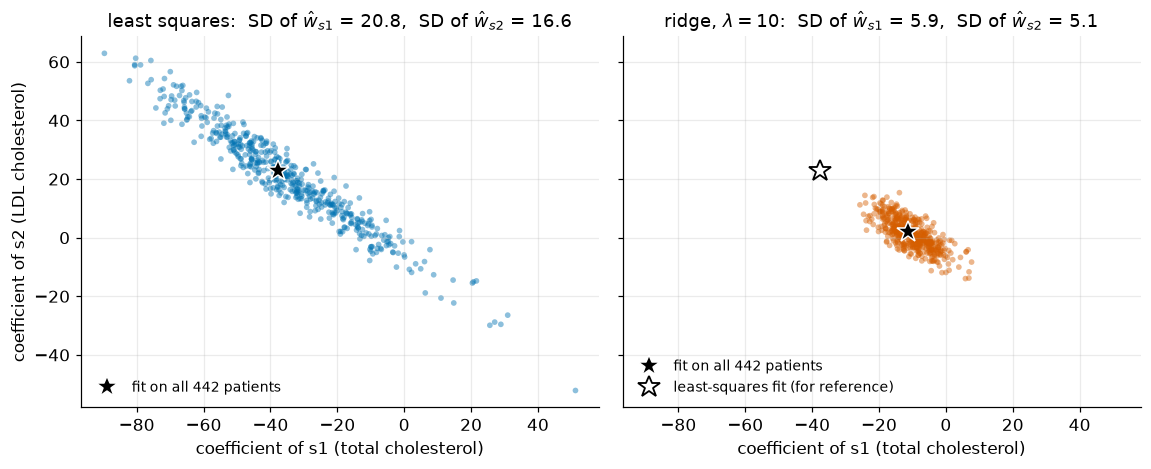

correlation of the two coefficients across bootstrap fits:  least squares -0.97,  ridge -0.74


In [11]:
# Figure 6.2 — the bootstrap cloud of two collinear coefficients, least squares against ridge
boot_ridge = np.empty((B, d_d))
rng = np.random.default_rng(SEED)
for b in range(B):
    idx = rng.integers(0, n_d, size=n_d)                    # same resampling scheme as in Section 6.2.4
    boot_ridge[b] = ridge_fit(Z_diab[idx], y_diab[idx], lam)[1]

def figure_6_2():
    j1, j2 = feature_names.index("s1"), feature_names.index("s2")
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.4), sharex=True, sharey=True)
    for ax, boot, w_full, title, color in [(axes[0], boot_ols, w_ols[1:], "least squares", BLUE),
                                           (axes[1], boot_ridge, w_mine, rf"ridge, $\lambda = {lam:g}$", VERMILION)]:
        ax.scatter(boot[:, j1], boot[:, j2], s=14, color=color, alpha=0.45, edgecolor="none")
        ax.plot(w_full[j1], w_full[j2], marker="*", ms=15, color="black", mec="white", ls="none", label="fit on all 442 patients")
        if boot is boot_ridge:
            ax.plot(w_ols[1:][j1], w_ols[1:][j2], marker="*", ms=15, color="white", mec="black", mew=1.2, ls="none",
                    label="least-squares fit (for reference)")
        ax.set(title=f"{title}:  SD of $\\hat w_{{s1}}$ = {boot[:, j1].std(ddof=1):.1f},  SD of $\\hat w_{{s2}}$ = {boot[:, j2].std(ddof=1):.1f}",
               xlabel=r"coefficient of s1 (total cholesterol)")
    axes[0].set_ylabel(r"coefficient of s2 (LDL cholesterol)")
    axes[0].legend(frameon=False, loc="lower left", fontsize=9)
    axes[1].legend(frameon=False, loc="lower left", fontsize=9)
    fig.tight_layout()
    plt.show()

figure_6_2()
print("correlation of the two coefficients across bootstrap fits:  least squares %.2f,  ridge %.2f" %
      (np.corrcoef(boot_ols[:, 4], boot_ols[:, 5])[0, 1], np.corrcoef(boot_ridge[:, 4], boot_ridge[:, 5])[0, 1]))

The cloud of least squares is long and thin: the two coefficients are almost perfectly and negatively correlated across resamples (the correlation is $-0.97$), because the data constrain their *combination* and leave their individual values to the noise. Ridge collapses the cloud to a small blob, with standard deviations more than 3 times smaller, but the blob is **centered far from the least-squares fit** (the open star in the right panel). That displacement is the bias, and the contraction is the variance reduction. Whether the trade is a good one is the question of Sections 6.3.3 and 6.3.4.

A word on the scale. The next cell fits least squares and ridge to the **raw** Diabetes features (in their original units: age in years, `bp` in mmHg, and so on) and to the standardized ones, on the same 331 training patients, and compares the errors on the 111 test patients.

In [12]:
from sklearn.model_selection import train_test_split

diab_raw = load_diabetes(as_frame=True, scaled=False).data
Xtr_raw, Xte_raw, ytr_d, yte_d = train_test_split(diab_raw, y_diab, test_size=0.25, random_state=SEED)
Xtr_d, Xte_d = Xtr_raw.to_numpy(), Xte_raw.to_numpy()
scaler_d = StandardScaler().fit(Xtr_d)                       # statistics from the training patients only
Ztr_d, Zte_d = scaler_d.transform(Xtr_d), scaler_d.transform(Xte_d)
mse = lambda y_true, y_pred: np.mean((y_true - y_pred) ** 2)

rows = {}
for name, (A_tr, A_te) in {"raw units": (Xtr_d, Xte_d), "standardized": (Ztr_d, Zte_d)}.items():
    rows[name] = {"least squares": mse(yte_d, LinearRegression().fit(A_tr, ytr_d).predict(A_te)),
                  "ridge, lambda = 10": mse(yte_d, Ridge(alpha=10).fit(A_tr, ytr_d).predict(A_te)),
                  "ridge, lambda = 100": mse(yte_d, Ridge(alpha=100).fit(A_tr, ytr_d).predict(A_te))}
print("test MSE")
print(pd.DataFrame(rows).T.round(1).to_string())
print(f"(baseline that always predicts the training mean: {mse(yte_d, ytr_d.mean()):.1f})")

test MSE
              least squares  ridge, lambda = 10  ridge, lambda = 100
raw units            2848.3              2903.5               2992.6
standardized         2848.3              2830.7               2817.5
(baseline that always predicts the training mean: 5607.2)


The least-squares column does not depend on the units, as expected (the two entries coincide). The ridge rows do, and on the raw features ridge is *worse* than least squares (2903.5 and 2992.6 against 2848.3), while on the standardized features it is slightly better (2830.7 and 2817.5). On raw units the penalty falls most heavily on the features with small numerical values, such as `sex` (coded 1 or 2) and `s4`, whose coefficients must be large to matter, and spares those with large values such as `bp` and `s6`. The penalty must treat all the features alike, which is what standardization achieves.

:::{admonition} Pitfall
:class: warning
**Always standardize before ridge** (and before any penalized model: Lasso, logistic regression with the default penalty, SVMs), and do it inside a `Pipeline`, so that the means and standard deviations come from the training part of each split. Whether a variable is measured in grams or kilograms must not change the model.
:::

### 6.3.2 The singular value view: shrinking the weak directions

The effect of ridge becomes transparent in the basis of the singular value decomposition. Let $\mathbf{X} = \mathbf{U}\boldsymbol\Sigma\mathbf{V}^\top$ be the thin SVD of the centered data matrix, with singular values $\sigma_1 \ge \dots \ge \sigma_d > 0$, left singular vectors $\mathbf{u}_j \in \mathbb{R}^n$ and right singular vectors $\mathbf{v}_j \in \mathbb{R}^d$ (the principal axes of the data, which Chapter 13 will study in detail). The squared singular value $\sigma_j^2$ is $n$ times the variance of the data along the direction $\mathbf{v}_j$.

**Proposition 6.4 (ridge in the singular basis).**
$$
\hat{\mathbf{w}}_\lambda = \sum_{j=1}^d \frac{\sigma_j}{\sigma_j^2 + \lambda}\,(\mathbf{u}_j^\top\mathbf{y})\,\mathbf{v}_j,
\qquad
\mathbf{X}\hat{\mathbf{w}}_\lambda = \sum_{j=1}^d \underbrace{\frac{\sigma_j^2}{\sigma_j^2 + \lambda}}_{f_j(\lambda)}\,(\mathbf{u}_j^\top\mathbf{y})\,\mathbf{u}_j .
$$
Least squares is the case $\lambda = 0$, in which $f_j = 1$ for all $j$.

:::{admonition} Proof
:class: dropdown
Insert the SVD in the closed form: $\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I} = \mathbf{V}(\boldsymbol\Sigma^2 + \lambda\mathbf{I})\mathbf{V}^\top$, whose inverse is $\mathbf{V}(\boldsymbol\Sigma^2 + \lambda\mathbf{I})^{-1}\mathbf{V}^\top$, and $\mathbf{X}^\top\mathbf{y} = \mathbf{V}\boldsymbol\Sigma\mathbf{U}^\top\mathbf{y}$. Hence $\hat{\mathbf{w}}_\lambda = \mathbf{V}(\boldsymbol\Sigma^2 + \lambda\mathbf{I})^{-1}\boldsymbol\Sigma\mathbf{U}^\top\mathbf{y}$, which is the first formula. Multiplying by $\mathbf{X} = \mathbf{U}\boldsymbol\Sigma\mathbf{V}^\top$ and using $\mathbf{V}^\top\mathbf{V} = \mathbf{I}$ gives $\mathbf{U}\,\boldsymbol\Sigma^2(\boldsymbol\Sigma^2 + \lambda\mathbf{I})^{-1}\mathbf{U}^\top\mathbf{y}$, the second. $\square$
:::

Read the shrinkage factors $f_j(\lambda) = \sigma_j^2/(\sigma_j^2 + \lambda)$. A direction in which the data vary a lot ($\sigma_j^2 \gg \lambda$) is left almost untouched ($f_j \approx 1$), and a direction in which the data hardly vary ($\sigma_j^2 \ll \lambda$) is shrunk to nearly zero. This is exactly where the variance of least squares lives: by Theorem 6.1(2) and the SVD, $\operatorname{Cov}(\hat{\mathbf{w}}) = \sigma^2\mathbf{V}\boldsymbol\Sigma^{-2}\mathbf{V}^\top$, so the variance along $\mathbf{v}_j$ is $\sigma^2/\sigma_j^2$, **largest for the weakest directions**. Ridge is a soft truncation: it keeps what the data determine well and discards, gradually, what the data barely determine.

The sum of the shrinkage factors measures how many directions are still "in use". The **effective number of degrees of freedom** of the ridge fit is

$$
\operatorname{df}(\lambda) = \operatorname{tr}\mathbf{H}_\lambda = \sum_{j=1}^d \frac{\sigma_j^2}{\sigma_j^2 + \lambda},
\qquad \mathbf{H}_\lambda = \mathbf{X}(\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^\top ,
$$

the trace of the matrix that maps the targets to the fitted values. It decreases from $d$ (least squares) at $\lambda = 0$ to $0$ at $\lambda = \infty$, and it replaces the number of parameters $p$ in the formulas of Section 6.2.1. This is not a coincidence, as the next result shows for any method that is *linear in $\mathbf{y}$*.

**Proposition 6.5 (optimism of a linear smoother).** Let $\hat{\mathbf{y}} = \mathbf{S}\mathbf{y}$ for a fixed matrix $\mathbf{S}$ (a *linear smoother*), with $\mathbf{y} = \boldsymbol\mu + \boldsymbol\varepsilon$, $\operatorname{Cov}(\boldsymbol\varepsilon) = \sigma^2\mathbf{I}$, and let $\mathbf{y}'$ be fresh targets at the same inputs. Then
$$
\mathbb{E}\lVert\mathbf{y}' - \hat{\mathbf{y}}\rVert^2 - \mathbb{E}\lVert\mathbf{y} - \hat{\mathbf{y}}\rVert^2 = 2\sigma^2\operatorname{tr}\mathbf{S}.
$$

:::{admonition} Proof
:class: dropdown
For any fixed matrix $\mathbf{B}$, $\mathbb{E}\lVert\mathbf{B}\boldsymbol\varepsilon\rVert^2 = \sigma^2\operatorname{tr}(\mathbf{B}^\top\mathbf{B})$. Write $\mathbf{y} - \mathbf{S}\mathbf{y} = (\mathbf{I} - \mathbf{S})\boldsymbol\mu + (\mathbf{I} - \mathbf{S})\boldsymbol\varepsilon$, so the training error has expectation $\lVert(\mathbf{I} - \mathbf{S})\boldsymbol\mu\rVert^2 + \sigma^2\operatorname{tr}\big((\mathbf{I} - \mathbf{S})^\top(\mathbf{I} - \mathbf{S})\big)$. Write $\mathbf{y}' - \mathbf{S}\mathbf{y} = (\mathbf{I} - \mathbf{S})\boldsymbol\mu + \boldsymbol\varepsilon' - \mathbf{S}\boldsymbol\varepsilon$, so the fresh error has expectation $\lVert(\mathbf{I} - \mathbf{S})\boldsymbol\mu\rVert^2 + n\sigma^2 + \sigma^2\operatorname{tr}(\mathbf{S}^\top\mathbf{S})$. The difference is
$$
\sigma^2\Big[n + \operatorname{tr}(\mathbf{S}^\top\mathbf{S}) - \operatorname{tr}\big(\mathbf{I} - \mathbf{S} - \mathbf{S}^\top + \mathbf{S}^\top\mathbf{S}\big)\Big] = \sigma^2\big[n + \operatorname{tr}(\mathbf{S}^\top\mathbf{S}) - n + 2\operatorname{tr}\mathbf{S} - \operatorname{tr}(\mathbf{S}^\top\mathbf{S})\big] = 2\sigma^2\operatorname{tr}\mathbf{S}. \qquad\square
$$
:::

For least squares $\mathbf{S} = \mathbf{H}$ and $\operatorname{tr}\mathbf{H} = p$, which is Theorem 6.1. For ridge, the optimism of the training error is $2\sigma^2\operatorname{df}(\lambda)/n$: **regularization reduces the optimism because it reduces the effective number of parameters**, continuously. The proposition also applies to the $k$-NN regressor of Chapter 4, whose smoother has the entry $1/k$ in the $k$ columns of the neighbors of each point: its trace is $n/k$ whenever every training point is among its own neighbors, so $k$-NN has $n/k$ "effective parameters" and its optimism is $2\sigma^2/k$. The two families of this book so far, local and global, spend the same currency: **degrees of freedom**.

In [13]:
# the effective degrees of freedom of ridge and of k-NN, and the SVD formulas, checked numerically
Zc = Z_diab - Z_diab.mean(axis=0)
U, sv, Vt = np.linalg.svd(Zc, full_matrices=False)
yc = y_diab - y_diab.mean()
print("squared singular values of the standardized Diabetes features:", np.round(sv ** 2, 1))

rows = []
for lam_k in [0, 1, 10, 100, 1000]:
    w_svd = Vt.T @ ((sv / (sv ** 2 + lam_k)) * (U.T @ yc))                  # Proposition 6.4
    w_ref = np.linalg.lstsq(Zc, yc, rcond=None)[0] if lam_k == 0 else Ridge(alpha=lam_k, fit_intercept=False).fit(Zc, yc).coef_
    H_lam = Zc @ np.linalg.solve(Zc.T @ Zc + lam_k * np.eye(d_d), Zc.T)
    rows.append({"lambda": lam_k, "df (sum of factors)": np.sum(sv ** 2 / (sv ** 2 + lam_k)), "df (trace of H)": np.trace(H_lam),
                 "norm of the weights": np.linalg.norm(w_svd), "max |SVD - reference|": np.abs(w_svd - w_ref).max()})
print(pd.DataFrame(rows).set_index("lambda").to_string(float_format=lambda v: f"{v:.4g}"))

from sklearn.neighbors import KNeighborsRegressor
for k in [1, 5, 20]:
    nn = KNeighborsRegressor(n_neighbors=k).fit(Z_diab[:100], y_diab[:100])
    S = np.zeros((100, 100))
    for i, row in enumerate(nn.kneighbors(Z_diab[:100], return_distance=False)):
        S[i, row] = 1 / k                                                   # the k-NN smoother: average of the k neighbors
    print(f"k = {k:>2}: trace of the k-NN smoother = {np.trace(S):.1f}   (n/k = {100 / k:.1f})")

squared singular values of the standardized Diabetes features: [1778.7  659.6  533.   422.3  292.7  266.4  237.2  191.7   34.6    3.8]
        df (sum of factors)  df (trace of H)  norm of the weights  max |SVD - reference|
lambda                                                                                  
0                        10               10                65.54              7.105e-14
1                      9.74             9.74                57.53              4.867e-13
10                    8.829            8.829                42.57              1.954e-13
100                   6.592            6.592                34.75              4.619e-14
1000                  2.509            2.509                17.35               9.77e-15
k =  1: trace of the k-NN smoother = 100.0   (n/k = 100.0)
k =  5: trace of the k-NN smoother = 20.0   (n/k = 20.0)
k = 20: trace of the k-NN smoother = 5.0   (n/k = 5.0)


The SVD formulas reproduce the reference solutions to machine precision, the two ways of computing the degrees of freedom coincide, and the weights shrink monotonically: the norm goes from 65.5 at $\lambda = 0$ to 17.4 at $\lambda = 1000$ (the norm decreases with $\lambda$ because $\lVert\hat{\mathbf{w}}_\lambda\rVert^2 = \sum_j \sigma_j^2(\mathbf{u}_j^\top\mathbf{y})^2/(\sigma_j^2 + \lambda)^2$ does). The $k$-NN traces equal $n/k$. Figure 6.3 shows the whole **regularization path**: on the left, the shrinkage factors of the ten singular directions as functions of $\lambda$ (each curve starts to decay when $\lambda$ reaches the corresponding $\sigma_j^2$); on the right, the ten coefficients.

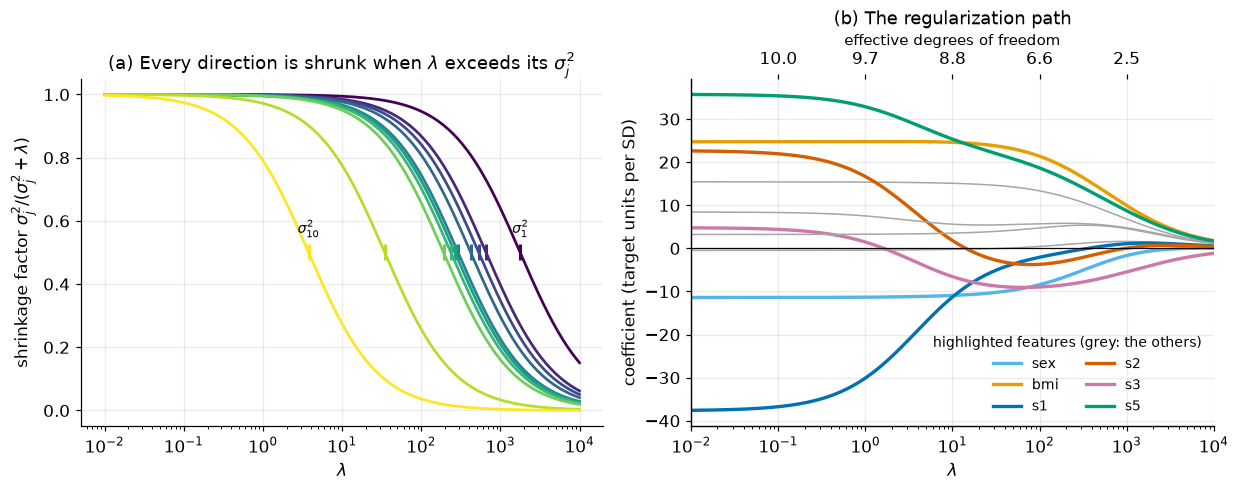

In [14]:
# Figure 6.3 — shrinkage factors and the ridge regularization path
def figure_6_3():
    lams = np.logspace(-2, 4, 200)
    paths = np.array([Vt.T @ ((sv / (sv ** 2 + l)) * (U.T @ yc)) for l in lams])            # (200, 10)
    fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.6))

    ax = axes[0]
    cmap = plt.cm.viridis
    for j in range(d_d):
        ax.semilogx(lams, sv[j] ** 2 / (sv[j] ** 2 + lams), color=cmap(j / (d_d - 1)), lw=1.8)
        ax.plot(sv[j] ** 2, 0.5, marker="|", color=cmap(j / (d_d - 1)), ms=11, mew=2)
    ax.text(sv[0] ** 2, 0.56, r"$\sigma_1^2$", ha="center", fontsize=9)
    ax.text(sv[-1] ** 2, 0.56, r"$\sigma_{10}^2$", ha="center", fontsize=9)
    ax.set(xlabel=r"$\lambda$", ylabel=r"shrinkage factor $\sigma_j^2/(\sigma_j^2+\lambda)$",
           title="(a) Every direction is shrunk when $\\lambda$ exceeds its $\\sigma_j^2$")

    ax = axes[1]
    highlight = {"s1": BLUE, "s2": VERMILION, "s5": GREEN, "bmi": ORANGE, "s3": PURPLE, "sex": SKY}
    for j, name in enumerate(feature_names):
        color, lw = highlight.get(name, "0.65"), (2.2 if name in highlight else 1.0)
        ax.semilogx(lams, paths[:, j], color=color, lw=lw, label=name if name in highlight else None)
    ax.axhline(0, color="black", lw=0.8)
    marks = [0.1, 1, 10, 100, 1000]
    top = ax.twiny()
    top.set_xscale("log")
    top.set_xlim(ax.get_xlim())
    top.set_xticks(marks)
    top.set_xticklabels([f"{np.sum(sv ** 2 / (sv ** 2 + l)):.1f}" for l in marks])
    top.set_xlabel("effective degrees of freedom", fontsize=10)
    top.minorticks_off()
    top.grid(False)
    ax.set(xlabel=r"$\lambda$", ylabel="coefficient (target units per SD)", title="(b) The regularization path", xlim=(0.01, 1e4))
    top.set_xlim(0.01, 1e4)
    ax.legend(frameon=False, fontsize=9, ncol=2, loc="lower right", title="highlighted features (grey: the others)", title_fontsize=9)
    fig.tight_layout()
    plt.show()

figure_6_3()

In panel (b), the well-determined coefficients (`bmi`, `s5`, `sex`) decrease slowly and smoothly, while the correlated block moves at once: `s1` and `s2`, which start at $-37.7$ and $+22.7$, are pulled toward the origin between $\lambda = 1$ and $\lambda = 10$ (at $\lambda = 10$ they are $-11.3$ and $+1.8$, and `s2` is about to change sign). The top axis translates $\lambda$ into degrees of freedom: $\lambda = 10$ keeps $8.8$ of the 10, $\lambda = 100$ keeps $6.6$ and $\lambda = 1000$ only $2.5$.

### 6.3.3 Bias and variance of ridge, exactly

Because ridge is linear in $\mathbf{y}$, its bias and variance can be computed in closed form, as we did for $k$-NN in Section 4.5.2. Work in the fixed-design model of Section 6.2.1, with centered $\mathbf{X}$, and let $\boldsymbol\alpha = \mathbf{V}^\top\mathbf{w}^\ast$ be the coordinates of the true weights in the basis of the right singular vectors.

**Proposition 6.6 (bias and variance of ridge).**
$$
\lVert\mathbb{E}\hat{\mathbf{w}}_\lambda - \mathbf{w}^\ast\rVert^2 = \sum_{j=1}^d \frac{\lambda^2\alpha_j^2}{(\sigma_j^2 + \lambda)^2},
\qquad
\operatorname{tr}\operatorname{Cov}(\hat{\mathbf{w}}_\lambda) = \sigma^2\sum_{j=1}^d \frac{\sigma_j^2}{(\sigma_j^2 + \lambda)^2},
$$
and the expected squared prediction error at the training inputs is
$$
\frac1n\,\mathbb{E}\lVert\mathbf{X}\hat{\mathbf{w}}_\lambda - \mathbf{X}\mathbf{w}^\ast\rVert^2
= \frac1n\sum_{j=1}^d \frac{\sigma_j^2\lambda^2\alpha_j^2}{(\sigma_j^2 + \lambda)^2} + \frac{\sigma^2}{n}\sum_{j=1}^d \frac{\sigma_j^4}{(\sigma_j^2 + \lambda)^2}.
$$

:::{admonition} Proof
:class: dropdown
We have $\mathbf{X}\mathbf{w}^\ast = \mathbf{U}\boldsymbol\Sigma\mathbf{V}^\top\mathbf{w}^\ast = \mathbf{U}\boldsymbol\Sigma\boldsymbol\alpha$ and $\mathbf{y} = \mathbf{U}\boldsymbol\Sigma\boldsymbol\alpha + \boldsymbol\varepsilon$. By Proposition 6.4,
$$
\hat{\mathbf{w}}_\lambda = \mathbf{V}\,\mathrm{diag}\!\Big(\frac{\sigma_j^2}{\sigma_j^2 + \lambda}\Big)\boldsymbol\alpha + \mathbf{V}\,\mathrm{diag}\!\Big(\frac{\sigma_j}{\sigma_j^2 + \lambda}\Big)\mathbf{U}^\top\boldsymbol\varepsilon .
$$
The first term is deterministic and the second has mean zero. So the bias is $\mathbf{V}\,\mathrm{diag}\big(\frac{\sigma_j^2}{\sigma_j^2 + \lambda} - 1\big)\boldsymbol\alpha = -\mathbf{V}\,\mathrm{diag}\big(\frac{\lambda}{\sigma_j^2 + \lambda}\big)\boldsymbol\alpha$, whose squared norm is the first sum. The covariance of the second term is $\sigma^2\mathbf{V}\,\mathrm{diag}\big(\frac{\sigma_j^2}{(\sigma_j^2 + \lambda)^2}\big)\mathbf{V}^\top$ (use $\mathbf{U}^\top\mathbf{U} = \mathbf{I}$), whose trace is the second sum. For the prediction error multiply the estimator by $\mathbf{X} = \mathbf{U}\boldsymbol\Sigma\mathbf{V}^\top$: the squared norm of $\mathbf{X}\mathbf{b}$ for the bias vector $\mathbf{b}$ is $\sum_j \sigma_j^2 b_j'^2$ in the $\mathbf{V}$ coordinates, and the same factor $\sigma_j^2$ multiplies each variance term. $\square$
:::

The bias is zero at $\lambda = 0$ and grows with $\lambda$; it affects first the directions where $\sigma_j^2$ is small and $\alpha_j$ is large. The variance is largest at $\lambda = 0$ and decreases. Is there always a $\lambda$ at which the decrease of the variance beats the increase of the bias? Yes, and the proof is short.

**Theorem 6.7 (ridge beats least squares; Hoerl and Kennard, 1970).** For every true $\mathbf{w}^\ast$ and every $\sigma^2 > 0$ there is a $\lambda > 0$ for which $\mathbb{E}\lVert\hat{\mathbf{w}}_\lambda - \mathbf{w}^\ast\rVert^2 < \mathbb{E}\lVert\hat{\mathbf{w}}_0 - \mathbf{w}^\ast\rVert^2$. The same holds for the prediction error at the training inputs.

:::{admonition} Proof
:class: dropdown
The mean squared error is the sum of the squared bias and the variance of Proposition 6.6. The squared bias is $\sum_j\lambda^2\alpha_j^2/(\sigma_j^2 + \lambda)^2$, which is $O(\lambda^2)$ and has therefore **derivative zero at $\lambda = 0$**. The variance is $\sigma^2\sum_j\sigma_j^2(\sigma_j^2 + \lambda)^{-2}$, with derivative $-2\sigma^2\sum_j\sigma_j^2(\sigma_j^2 + \lambda)^{-3}$, which at $\lambda = 0$ equals $-2\sigma^2\sum_j\sigma_j^{-4} < 0$. So the derivative of the mean squared error at $\lambda = 0$ is strictly negative, and the error decreases when $\lambda$ leaves zero. The same argument applies to the prediction error, with the extra factors $\sigma_j^2$ (the variance term becomes $\frac{\sigma^2}{n}\sum_j\sigma_j^4(\sigma_j^2 + \lambda)^{-2}$, with derivative $-\frac{2\sigma^2}{n}\sum_j\sigma_j^{-2} < 0$ at zero). $\square$
:::

The theorem says that *a little bias is always a good investment*, and it explains the "paradox" that an unbiased estimator that is optimal among linear unbiased ones (Gauss–Markov) can be beaten: the theorem of Gauss and Markov restricts the competition to **unbiased** estimators. The theorem does not say *which* $\lambda$ works, nor how much is gained. In the simplest case, an orthonormal design ($\mathbf{X}^\top\mathbf{X} = \mathbf{I}$, so all $\sigma_j = 1$), the error is $(\lambda^2\lVert\mathbf{w}^\ast\rVert^2 + \sigma^2 d)/(1 + \lambda)^2$ and setting its derivative to zero gives the best value

$$
\lambda^\ast = \frac{\sigma^2 d}{\lVert\mathbf{w}^\ast\rVert^2},
$$

a *noise-to-signal ratio*: the stronger the noise, the more shrinkage; the larger the true weights, the less. In general the best $\lambda$ depends on the unknown $\mathbf{w}^\ast$ and must be estimated from the data (Section 6.3.4).

To see how large the gain can be, we build a **simulated world on a real design, flagged as such**. The inputs are the standardized Diabetes features of $n$ patients (all 442, or random subsets of 100 and of 40), so the correlation structure is real. The true weights are those of the least-squares fit to all 442 patients and the noise standard deviation is the estimated $\hat\sigma = 54.15$: the *only* invented part is that these values are declared to be the truth, which lets us evaluate the formulas of Proposition 6.6 exactly and check them with a Monte Carlo simulation.

In [15]:
sigma_true = np.sqrt(sigma2_d)                          # 54.15, estimated on the real data and declared "true" here
w_star = w_ols[1:]                                      # coefficients of the least-squares fit, declared "true"
lams_bv = np.logspace(-2, 4, 241)

def ridge_theory(X_design, lams, w_star, sigma):
    """Exact bias^2, variance and prediction error (at the design) of ridge, Proposition 6.6."""
    Xc = X_design - X_design.mean(axis=0)
    n_ = len(Xc)
    _, s_, Vt_ = np.linalg.svd(Xc, full_matrices=False)
    alpha = Vt_ @ w_star
    out = {"param_bias2": [], "param_var": [], "pred_bias2": [], "pred_var": []}
    for l in lams:
        out["param_bias2"].append(np.sum((l * alpha / (s_ ** 2 + l)) ** 2))
        out["param_var"].append(sigma ** 2 * np.sum(s_ ** 2 / (s_ ** 2 + l) ** 2))
        out["pred_bias2"].append(np.sum(s_ ** 2 * (l * alpha / (s_ ** 2 + l)) ** 2) / n_)
        out["pred_var"].append(sigma ** 2 * np.sum(s_ ** 4 / (s_ ** 2 + l) ** 2) / n_)
    return {k: np.array(v) for k, v in out.items()}

rng = np.random.default_rng(SEED)
designs = {442: Z_diab}
for n_sub in [100, 40]:
    designs[n_sub] = Z_diab[rng.choice(n_d, n_sub, replace=False)]
theory = {n_sub: ridge_theory(Xd, lams_bv, w_star, sigma_true) for n_sub, Xd in designs.items()}

rows = []
for n_sub, th in theory.items():
    total = th["pred_bias2"] + th["pred_var"]
    ols_err = total[0]                                   # lambda = 0.01 is numerically least squares here
    k_best = np.argmin(total)
    rows.append({"n": n_sub, "least squares": ols_err, "= p sigma^2/n": d_d * sigma_true ** 2 / n_sub,
                 "best lambda": lams_bv[k_best], "error at best lambda": total[k_best],
                 "gain": f"{100 * (1 - total[k_best] / ols_err):.1f}%"})
print("expected squared prediction error at the design points (units of y^2)")
print(pd.DataFrame(rows).set_index("n").to_string(float_format=lambda v: f"{v:.4g}"))

# Monte Carlo check of the formulas for n = 100 at the theoretical optimum
n_chk = 100
Xc = designs[n_chk] - designs[n_chk].mean(axis=0)
lam_chk = lams_bv[np.argmin(theory[n_chk]["pred_bias2"] + theory[n_chk]["pred_var"])]
rng = np.random.default_rng(SEED)
errs = []
for _ in range(4000):
    y_sim = Xc @ w_star + sigma_true * rng.standard_normal(n_chk)
    w_hat = np.linalg.solve(Xc.T @ Xc + lam_chk * np.eye(d_d), Xc.T @ (y_sim - y_sim.mean()))
    errs.append(np.mean((Xc @ (w_hat - w_star)) ** 2))
k_chk = np.argmin(np.abs(lams_bv - lam_chk))
print(f"\nn = {n_chk}, lambda = {lam_chk:.1f}:  Monte Carlo {np.mean(errs):.1f}  vs  formula {theory[n_chk]['pred_bias2'][k_chk] + theory[n_chk]['pred_var'][k_chk]:.1f}")

expected squared prediction error at the design points (units of y^2)
     least squares  = p sigma^2/n  best lambda  error at best lambda   gain
n                                                                          
442          66.31          66.35        1.679                 63.93   3.6%
100          291.9          293.3        17.78                 206.3  29.3%
40           723.7          733.2        15.85                 379.4  47.6%

n = 100, lambda = 17.8:  Monte Carlo 208.3  vs  formula 206.3


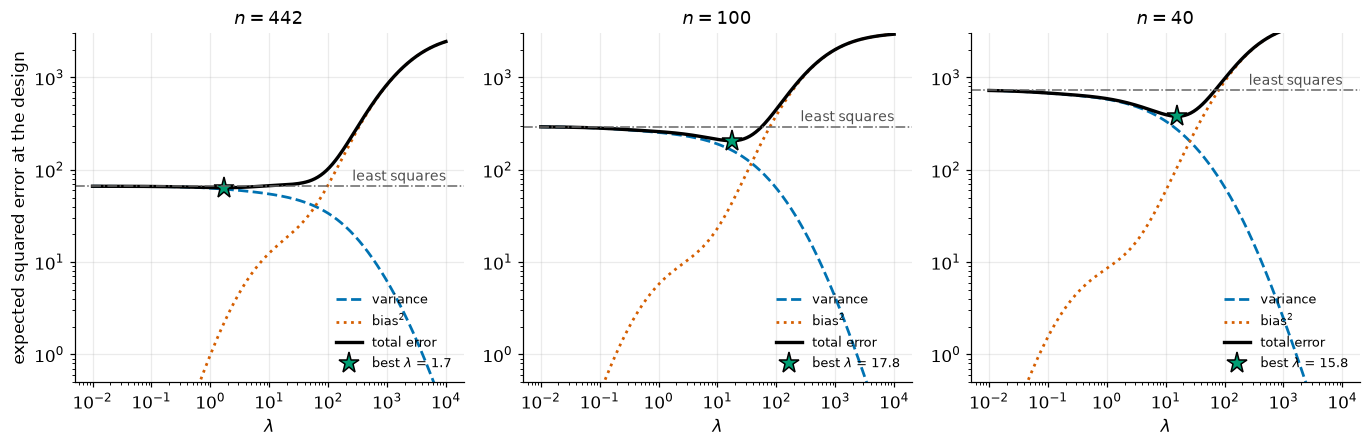

In [16]:
# Figure 6.4 — the bias-variance trade-off of ridge, in a world where the truth is known
def figure_6_4():
    fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.2), sharex=True)
    for ax, (n_sub, th) in zip(axes, theory.items()):
        bias2, var_ = th["pred_bias2"], th["pred_var"]
        total = bias2 + var_
        ax.loglog(lams_bv, var_, color=BLUE, lw=1.8, ls="--", label="variance")
        ax.loglog(lams_bv, bias2, color=VERMILION, lw=1.8, ls=":", label=r"bias$^2$")
        ax.loglog(lams_bv, total, color="black", lw=2.2, label="total error")
        k = np.argmin(total)
        ax.plot(lams_bv[k], total[k], marker="*", ms=14, color=GREEN, mec="black", ls="none", label=rf"best $\lambda$ = {lams_bv[k]:.1f}")
        ax.axhline(total[0], color="0.4", lw=1.0, ls="-.")
        ax.text(lams_bv[-1], total[0] * 1.06, "least squares", ha="right", va="bottom", fontsize=9, color="0.3")
        ax.set(title=f"$n = {n_sub}$", xlabel=r"$\lambda$", ylim=(0.5, 3e3))
        ax.legend(frameon=False, fontsize=8.5, loc="lower right")
    axes[0].set_ylabel("expected squared error at the design")
    fig.tight_layout()
    plt.show()

figure_6_4()

The formula and the simulation agree to within 1%. The three panels tell the story of the theorem in numbers, and the table above gives its size: with all 442 patients, ridge improves on the prediction error of least squares by only 3.6%; with 100 patients by about 29%; with 40 patients by about 48%. The gain is **large when the number of parameters is large relative to the sample** (the variance $\sigma^2 d/n$ of least squares is large and there is a lot to remove) and **small when data are plentiful**. In the left panel, with 442 patients, the total error is almost flat to the left of the optimum: ridge cannot do much about a variance that is already small. The best $\lambda$, which is about 2 for 442 patients, is *larger* in the other two panels, because the noise then matters more than the bias.

:::{admonition} Key idea
:class: tip
**Regularization is useful in proportion to the variance that it can remove.** With a lot of data relative to the number of parameters, least squares is already near the best achievable and ridge gives little; with few data, or nearly collinear features, it gives a lot. The same pattern holds for every regularized method in this book.
:::

### 6.3.4 Choosing $\lambda$

The formula for the best $\lambda$ involves $\mathbf{w}^\ast$ and $\sigma^2$, which we do not know, so $\lambda$ is a hyperparameter to be chosen with the methods of Chapter 5. For ridge the choice is unusually cheap, because **leave-one-out cross-validation has a closed form**. Let $\mathbf{Z} = [\mathbf{1}\ \ \mathbf{X}]$ be the design matrix with the column of ones, $\mathbf{P} = \mathrm{diag}(0, \lambda, \dots, \lambda)$ the penalty (the intercept is free), $\mathbf{A} = \mathbf{Z}^\top\mathbf{Z} + \mathbf{P}$ and $\hat{\boldsymbol\theta} = \mathbf{A}^{-1}\mathbf{Z}^\top\mathbf{y}$ the ridge solution (intercept and weights). The fitted values are $\hat{\mathbf{y}} = \mathbf{H}_\lambda\mathbf{y}$ with $\mathbf{H}_\lambda = \mathbf{Z}\mathbf{A}^{-1}\mathbf{Z}^\top$, with diagonal entries $h_{ii} = \mathbf{z}_i^\top\mathbf{A}^{-1}\mathbf{z}_i$.

**Proposition 6.8 (leave-one-out for ridge).** Let $e_i = y_i - \hat y_i$ be the training residual. The prediction for $\mathbf{x}_i$ of the ridge model fitted **without** the $i$-th example, with the same $\lambda$, has error
$$
y_i - \hat y_i^{(-i)} = \frac{e_i}{1 - h_{ii}} .
$$
Therefore $\mathrm{LOO}(\lambda) = \frac1n\sum_i\big(e_i/(1 - h_{ii})\big)^2$ is computed from a **single** fit. For $\lambda = 0$ this is the formula of Exercise 5.5 and of Worked example 6.1.

:::{admonition} Proof
:class: dropdown
Removing the $i$-th example replaces $\mathbf{A}$ by $\mathbf{A}_{(i)} = \mathbf{A} - \mathbf{z}_i\mathbf{z}_i^\top$ (the penalty does not depend on the data) and $\mathbf{Z}^\top\mathbf{y}$ by $\mathbf{Z}^\top\mathbf{y} - \mathbf{z}_i y_i$. The Sherman–Morrison formula gives $\mathbf{A}_{(i)}^{-1} = \mathbf{A}^{-1} + \dfrac{\mathbf{A}^{-1}\mathbf{z}_i\mathbf{z}_i^\top\mathbf{A}^{-1}}{1 - h_{ii}}$. Hence
$$
\mathbf{A}_{(i)}^{-1}\mathbf{Z}^\top\mathbf{y} = \hat{\boldsymbol\theta} + \frac{\mathbf{A}^{-1}\mathbf{z}_i\,\hat y_i}{1 - h_{ii}},
\qquad
\mathbf{A}_{(i)}^{-1}\mathbf{z}_i\,y_i = \mathbf{A}^{-1}\mathbf{z}_i\,y_i\Big(1 + \frac{h_{ii}}{1 - h_{ii}}\Big) = \frac{\mathbf{A}^{-1}\mathbf{z}_i\,y_i}{1 - h_{ii}},
$$
and the solution without the $i$-th example is $\hat{\boldsymbol\theta}^{(-i)} = \hat{\boldsymbol\theta} - \mathbf{A}^{-1}\mathbf{z}_i\,e_i/(1 - h_{ii})$. Its prediction for $\mathbf{z}_i$ is $\hat y_i - h_{ii}e_i/(1 - h_{ii})$, so the error is $y_i - \hat y_i + h_{ii}e_i/(1 - h_{ii}) = e_i\big(1 + h_{ii}/(1 - h_{ii})\big) = e_i/(1 - h_{ii})$. $\square$
:::

With the SVD of the centered features, everything is available for **all** values of $\lambda$ at almost no cost: $h_{ii}(\lambda) = \frac1n + \sum_j u_{ij}^2\,\sigma_j^2/(\sigma_j^2 + \lambda)$ (the first term is the intercept's share) and $\mathbf{e} = \tilde{\mathbf{y}} - \mathbf{U}\,\mathrm{diag}(f_j)\,\mathbf{U}^\top\tilde{\mathbf{y}}$. This is what `RidgeCV` does by default. As in Chapter 5, we keep the 111 test patients of the split of Section 6.3.1 aside, tune $\lambda$ on the 331 training patients, and look at the test set only at the end. We compare three estimates of the error as a function of $\lambda$: the leave-one-out shortcut, a brute-force 10-fold cross-validation, and the test error (shown for illustration, never used to choose).

In [17]:
from sklearn.model_selection import KFold

def loo_curve(Z, y, lams):
    """Leave-one-out MSE of ridge (intercept free) for many values of lambda from one SVD (Proposition 6.8)."""
    n_ = len(y)
    Zc_ = Z - Z.mean(axis=0)
    yc_ = y - y.mean()
    U_, s_, _ = np.linalg.svd(Zc_, full_matrices=False)
    uy = U_.T @ yc_
    out = []
    for l in lams:
        f = s_ ** 2 / (s_ ** 2 + l)
        e = yc_ - U_ @ (f * uy)
        h = 1 / n_ + (U_ ** 2) @ f
        out.append(np.mean((e / (1 - h)) ** 2))
    return np.array(out)

lams_cv = np.logspace(-2, 4, 61)
loo = loo_curve(Ztr_d, ytr_d, lams_cv)

# brute force check of the shortcut at two values of lambda: n refits each
for lam_c in [10.0, 10 ** 2.5]:
    errs = []
    for i in range(len(ytr_d)):
        keep = np.arange(len(ytr_d)) != i
        b_i, w_i = ridge_fit(Ztr_d[keep], ytr_d[keep], lam_c)
        errs.append(ytr_d[i] - (b_i + Ztr_d[i] @ w_i))
    k_c = np.argmin(np.abs(lams_cv - lam_c))
    print(f"lambda = {lam_c:>6.1f}:  LOO MSE by {len(ytr_d)} refits = {np.mean(np.square(errs)):.4f},  by the shortcut = {loo[k_c]:.4f}")

kf = KFold(10, shuffle=True, random_state=SEED)
cv10 = np.array([np.mean([mse(ytr_d[va], (lambda bw: bw[0] + Ztr_d[va] @ bw[1])(ridge_fit(Ztr_d[tr], ytr_d[tr], l)))
                          for tr, va in kf.split(Ztr_d)]) for l in lams_cv])
test_curve = np.array([mse(yte_d, (lambda bw: bw[0] + Zte_d @ bw[1])(ridge_fit(Ztr_d, ytr_d, l))) for l in lams_cv])
ols_test = mse(yte_d, LinearRegression().fit(Ztr_d, ytr_d).predict(Zte_d))
print(f"\nbest lambda by LOO: {lams_cv[loo.argmin()]:.1f}    by 10-fold CV: {lams_cv[cv10.argmin()]:.1f}    (the best for the test set would be {lams_cv[test_curve.argmin()]:.1f})")
print(f"test MSE: least squares {ols_test:.1f}   ridge at the LOO choice {test_curve[loo.argmin()]:.1f}   at the 10-fold choice {test_curve[cv10.argmin()]:.1f}   at the best test value {test_curve.min():.1f}")

lambda =   10.0:  LOO MSE by 331 refits = 3101.4255,  by the shortcut = 3101.4255
lambda =  316.2:  LOO MSE by 331 refits = 3405.7576,  by the shortcut = 3405.7576

best lambda by LOO: 1.6    by 10-fold CV: 20.0    (the best for the test set would be 63.1)
test MSE: least squares 2848.3   ridge at the LOO choice 2841.1   at the 10-fold choice 2822.4   at the best test value 2809.0


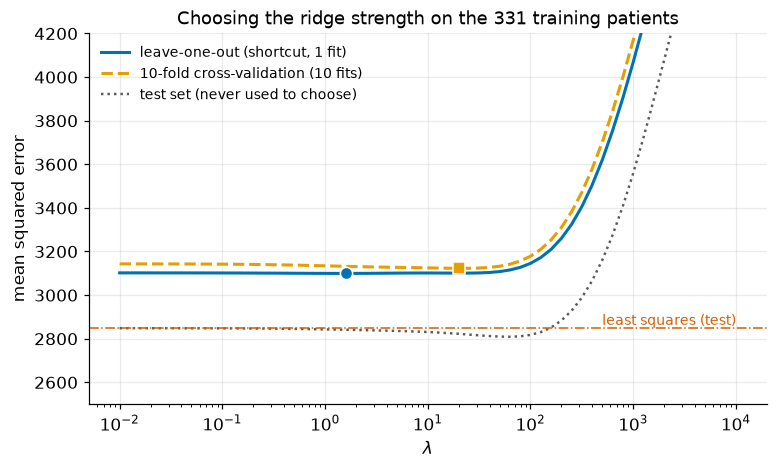

In [18]:
# Figure 6.5 — three curves for choosing lambda
def figure_6_5():
    fig, ax = plt.subplots(figsize=(7.2, 4.4))
    ax.semilogx(lams_cv, loo, color=BLUE, lw=2, label="leave-one-out (shortcut, 1 fit)")
    ax.semilogx(lams_cv, cv10, color=ORANGE, lw=2, ls="--", label="10-fold cross-validation (10 fits)")
    ax.semilogx(lams_cv, test_curve, color="0.35", lw=1.6, ls=":", label="test set (never used to choose)")
    ax.plot(lams_cv[loo.argmin()], loo.min(), "o", color=BLUE, ms=8, mec="white")
    ax.plot(lams_cv[cv10.argmin()], cv10.min(), "s", color=ORANGE, ms=8, mec="white")
    ax.axhline(ols_test, color=VERMILION, lw=1.0, ls="-.")
    ax.text(lams_cv[-1], ols_test, "least squares (test)", color=VERMILION, ha="right", va="bottom", fontsize=9)
    ax.set(xlabel=r"$\lambda$", ylabel="mean squared error", ylim=(2500, 4200),
           title="Choosing the ridge strength on the 331 training patients")
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    fig.tight_layout()
    plt.show()

figure_6_5()

The leave-one-out shortcut agrees with the brute-force refits to all printed digits, and it costs one SVD instead of 331 fits. The three curves are flat over a broad region (the minima, at $\lambda = 1.6$, 20 and 63, are far apart on the $\lambda$ axis but the curves between them are almost horizontal), and the error rises sharply only beyond $\lambda \approx 100$, when the model degenerates toward the mean. The test error of ridge at the leave-one-out choice is 2841.1 against 2848.3 for least squares: a gain of 7 points out of 2848, as the left panel of Figure 6.4 predicted for a sample of this size. Is it a *real* gain? The single split cannot tell, so we apply the logic of Section 5.5 and repeat the experiment over many random splits and for several training sizes, with the 111-patient test sets replaced by all the patients not used for training. For each training size we compare least squares and `RidgeCV` (leave-one-out, $\lambda$ chosen on the training part only) on the same splits.

In [19]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline

rows = []
alphas_grid = np.logspace(-2, 4, 61)
for n_train in [40, 60, 100, 200, 331]:
    gains, mse_ols_all, mse_ridge_all = [], [], []
    rng = np.random.default_rng(SEED)
    for _ in range(100):
        perm = rng.permutation(n_d)
        tr, te = perm[:n_train], perm[n_train:]
        m_ols = make_pipeline(StandardScaler(), LinearRegression()).fit(diab.data.iloc[tr], y_diab[tr])
        m_rdg = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas_grid)).fit(diab.data.iloc[tr], y_diab[tr])
        a, b = mse(y_diab[te], m_ols.predict(diab.data.iloc[te])), mse(y_diab[te], m_rdg.predict(diab.data.iloc[te]))
        mse_ols_all.append(a); mse_ridge_all.append(b); gains.append(a - b)
    gains = np.array(gains)
    rows.append({"training size": n_train, "least squares": np.mean(mse_ols_all), "ridge (LOO)": np.mean(mse_ridge_all),
                 "mean gain": gains.mean(), "SD of the gain": gains.std(ddof=1), "ridge better in": f"{(gains > 0).sum()}/100"})
print("test MSE on the patients not used for training; 100 random splits per row")
print(pd.DataFrame(rows).set_index("training size").to_string(float_format=lambda v: f"{v:.1f}"))

test MSE on the patients not used for training; 100 random splits per row
               least squares  ridge (LOO)  mean gain  SD of the gain ridge better in
training size                                                                       
40                    4138.7       3607.9      530.8           560.9          90/100
60                    3600.4       3402.1      198.2           259.5          85/100
100                   3284.0       3215.2       68.8           126.2          79/100
200                   3063.6       3049.6       14.0            49.2          68/100
331                   2983.0       2993.1      -10.1            31.5          53/100


The pattern is the one of the simulated world, now on real data. With 40 training patients ridge is better in 90 of the 100 splits and its mean test error is 13% lower (the least-squares fit of 11 parameters to 40 patients is very noisy); with 60 it wins in 85 splits. The gain shrinks quickly as the training set grows: 69 points with 100 patients, 14 with 200 (0.5% of the error, with a standard deviation of 49 across splits) and **none** with 331, where the mean gain is $-10$, ridge wins in 53 splits out of 100 and the standard deviation across splits is 31. As Section 5.5.2 warned, the 100 splits are not independent, so a naive standard error would overstate the evidence for the small gains. This is an honest and useful negative result, in the spirit of Section 4.8.1: ridge is not a free lunch, and for ten reasonably well-determined features and a few hundred patients, plain least squares is already close to the best that this model class can do. Ridge becomes indispensable when the ratio of parameters to examples grows, as in the next section but one.

### 6.3.5 Three views of the same estimator

The ridge estimator has been presented as a penalized least-squares problem. It can be read in two other ways, which are useful because each one suggests a different way of thinking about $\lambda$.

**The constraint view.** Consider the problem of fitting the data with weights of bounded norm,
$$
\min_{\mathbf{w}}\ \lVert\tilde{\mathbf{y}} - \mathbf{Z}\mathbf{w}\rVert_2^2 \quad\text{subject to}\quad \lVert\mathbf{w}\rVert_2 \le B ,
$$
that is, empirical risk minimization over the class $\mathcal{F}_B$ of Section 3.8. For every $\lambda > 0$, the ridge solution $\hat{\mathbf{w}}_\lambda$ solves this problem **with $B = \lVert\hat{\mathbf{w}}_\lambda\rVert$**. Indeed, if a vector $\tilde{\mathbf{w}}$ with $\lVert\tilde{\mathbf{w}}\rVert \le B$ fitted the data strictly better than $\hat{\mathbf{w}}_\lambda$, it would also have a smaller penalized objective (it has a smaller residual and a penalty that is not larger), contradicting the optimality of $\hat{\mathbf{w}}_\lambda$. Conversely, every bound $B$ smaller than the norm of the least-squares solution corresponds to a value of $\lambda$ (a Lagrange multiplier). *The penalty and the constraint are the same knob*, read in two ways. This explains why ridge is the practical form of the capacity control of Chapter 3: Proposition 3.6 says that the Rademacher complexity of $\mathcal{F}_B$ is at most $BR/\sqrt{n}$ when $\lVert\mathbf{x}_i\rVert \le R$, so the generalization gap of the model is controlled by the *norm* of the weights and not by their number, which is why a model with many features and a small norm can still generalize. Increasing $\lambda$ lowers $B$, and with it the bound. We can compute the norm that each $\lambda$ buys on the Diabetes training set.

In [20]:
R_d = np.linalg.norm(Ztr_d, axis=1).max()
rows = []
for lam_b in [0.0, 1.0, 10.0, 100.0, 1000.0]:
    _, w_b = ridge_fit(Ztr_d, ytr_d, lam_b)
    B = np.linalg.norm(w_b)
    rows.append({"lambda": lam_b, "B = norm of w": B, "B R / sqrt(n)": B * R_d / np.sqrt(len(ytr_d)), "training MSE": mse(ytr_d, ridge_fit(Ztr_d, ytr_d, lam_b)[0] + Ztr_d @ w_b)})
print(f"R = largest norm of a standardized training patient = {R_d:.2f}, n = {len(ytr_d)}")
print(pd.DataFrame(rows).set_index("lambda").to_string(float_format=lambda v: f"{v:.2f}"))

R = largest norm of a standardized training patient = 6.87, n = 331
        B = norm of w  B R / sqrt(n)  training MSE
lambda                                            
0.0             70.46          26.59       2907.26
1.0             59.75          22.55       2909.07
10.0            42.71          16.12       2926.18
100.0           33.79          12.75       3012.88
1000.0          15.16           5.72       3990.89


Each increase in $\lambda$ shrinks the norm, and the capacity term $BR/\sqrt{n}$ with it, at the price of a higher training error, which is the trade-off of Chapter 3 in numbers. (The bound of Proposition 3.6 is in the units of the features, and it is loose in absolute terms; what matters here is that it is *proportional to $B$*.)

**The Bayesian view.** Suppose that the noise is Gaussian, $y_i \mid \mathbf{x}_i \sim \mathcal{N}(\mathbf{w}^\top\mathbf{z}_i + b, \sigma^2)$, and that *before seeing the data* we believe that the weights are small and unrelated to each other: $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \tau^2\mathbf{I})$. The posterior density of $\mathbf{w}$ is proportional to the likelihood times the prior, so its negative logarithm is, up to a constant,
$$
\frac{1}{2\sigma^2}\lVert\tilde{\mathbf{y}} - \mathbf{Z}\mathbf{w}\rVert^2 + \frac{1}{2\tau^2}\lVert\mathbf{w}\rVert^2 = \frac{1}{2\sigma^2}\Big[\lVert\tilde{\mathbf{y}} - \mathbf{Z}\mathbf{w}\rVert^2 + \frac{\sigma^2}{\tau^2}\lVert\mathbf{w}\rVert^2\Big] .
$$
The **maximum a posteriori** (MAP) estimate is therefore the ridge estimator with
$$
\lambda = \frac{\sigma^2}{\tau^2} ,
$$
and the posterior is itself Gaussian, with mean $\hat{\mathbf{w}}_\lambda$ and covariance $\sigma^2(\mathbf{Z}^\top\mathbf{Z} + \lambda\mathbf{I})^{-1}$. In this reading, $\lambda$ is the ratio of the noise variance to the prior variance of the weights: a noisier problem, or a stronger prior belief that the weights are small, calls for more shrinkage. It also gives a new meaning to Theorem 6.7: the optimal $\lambda^\ast = \sigma^2 d/\lVert\mathbf{w}^\ast\rVert^2$ corresponds to $\tau^2 = \lVert\mathbf{w}^\ast\rVert^2/d$, a prior whose variance equals the *actual average squared weight*: the best penalty is the one that describes the truth correctly. The same argument applied to the Bernoulli likelihood gives the regularized logistic regression of Section 6.5, which is the MAP estimate under the same Gaussian prior.

We shall meet other priors, other constraint sets, and the way of combining the two views in Chapter 10, where the $\ell_1$ ball replaces the $\ell_2$ ball and produces sparse solutions. For the moment we note the three readings in one line: *penalty = constraint on the norm = Gaussian prior*.

## 6.4 Logistic regression

### 6.4.1 From scores to probabilities

Let $y \in \{0, 1\}$ and recall from Section 3.2.2 that the best possible classifier predicts class 1 when the regression function $\eta(\mathbf{x}) = \mathbb{P}(y = 1 \mid \mathbf{x})$ exceeds $\tfrac12$. A linear model for $\eta$ starts from the **score** $z = \mathbf{w}^\top\mathbf{x} + b$, which can be any real number, and squeezes it into $(0, 1)$ with the **logistic function** (sigmoid)

$$
\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad \eta(\mathbf{x}) \approx \sigma(\mathbf{w}^\top\mathbf{x} + b).
$$

The function has three properties that we use constantly: $\sigma(-z) = 1 - \sigma(z)$; its derivative is $\sigma'(z) = \sigma(z)\big(1 - \sigma(z)\big)$; and it inverts the **log-odds**,

$$
\log\frac{\eta}{1 - \eta} = \mathbf{w}^\top\mathbf{x} + b .
$$

So the model says that the **log-odds are linear in the features**: increasing the feature $x_j$ by one unit adds $w_j$ to the log-odds, that is, multiplies the odds $\eta/(1-\eta)$ by $e^{w_j}$ (this is how logistic regression is read in medicine: $e^{w_j}$ is an *odds ratio*). The classifier "predict 1 if $\sigma(z) > \tfrac12$" is the same as "predict 1 if $z > 0$": the decision boundary is the hyperplane $\mathbf{w}^\top\mathbf{x} + b = 0$, so logistic regression is a *linear classifier*, of the family whose capacity we measured in Chapter 3.

Why not simply fit least squares to the 0/1 labels, as in Section 6.2, and threshold at $\tfrac12$? Figure 6.6 shows the problem on the Breast Cancer data, with the single feature `mean radius`. We code the **malignant** tumors as 1 (the positive class of Chapter 5).

In [21]:
from scipy.special import expit as sigmoid
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score

X_bc = bc.data
y_bc = (1 - bc.target).to_numpy()                       # 1 = malignant (the positive class of Chapter 5), 0 = benign
x_rad = X_bc["mean radius"].to_numpy()

A_rad = np.column_stack([np.ones_like(x_rad), x_rad])
w_line = np.linalg.lstsq(A_rad, y_bc, rcond=None)[0]    # least squares on the 0/1 labels
line_pred = A_rad @ w_line
logit1 = LogisticRegression(C=np.inf, max_iter=10000).fit(x_rad.reshape(-1, 1), y_bc)   # no penalty: see Section 6.5

print(f"least squares on the labels: prediction below 0 for {(line_pred < 0).sum()} patients and above 1 for {(line_pred > 1).sum()}, out of {len(y_bc)}")
print(f"logistic regression: intercept {logit1.intercept_[0]:.2f}, slope {logit1.coef_[0, 0]:.3f}, "
      f"odds ratio per unit of mean radius = {np.exp(logit1.coef_[0, 0]):.2f}")

least squares on the labels: prediction below 0 for 60 patients and above 1 for 35, out of 569
logistic regression: intercept -15.25, slope 1.034, odds ratio per unit of mean radius = 2.81


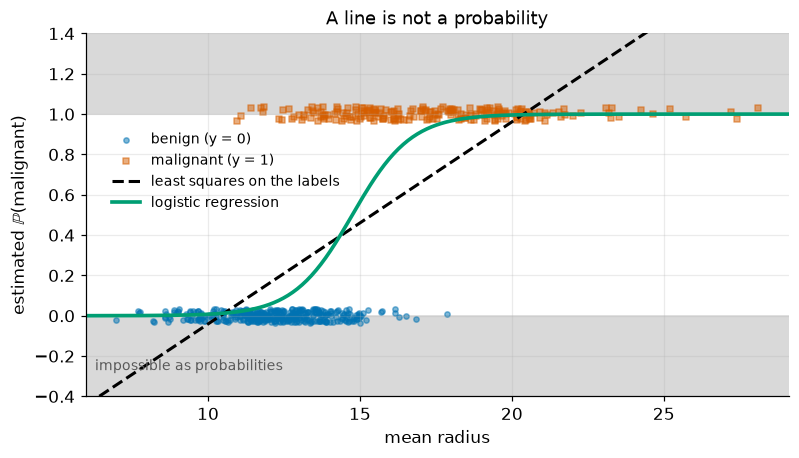

In [22]:
# Figure 6.6 — least squares on 0/1 labels against logistic regression
def figure_6_6():
    grid = np.linspace(x_rad.min() - 1, x_rad.max() + 1, 300)
    rng = np.random.default_rng(SEED)
    fig, ax = plt.subplots(figsize=(7.4, 4.3))
    ax.scatter(x_rad[y_bc == 0], 0.0 + rng.uniform(-0.035, 0.035, (y_bc == 0).sum()), s=12, color=BLUE, alpha=0.5, label="benign (y = 0)")
    ax.scatter(x_rad[y_bc == 1], 1.0 + rng.uniform(-0.035, 0.035, (y_bc == 1).sum()), s=12, color=VERMILION, alpha=0.5, marker="s", label="malignant (y = 1)")
    ax.plot(grid, w_line[0] + w_line[1] * grid, color="black", lw=2, ls="--", label="least squares on the labels")
    ax.plot(grid, sigmoid(logit1.intercept_[0] + logit1.coef_[0, 0] * grid), color=GREEN, lw=2.4, label="logistic regression")
    ax.axhspan(-0.4, 0, color="0.85", zorder=0)
    ax.axhspan(1, 1.4, color="0.85", zorder=0)
    ax.text(grid[0] + 0.3, -0.27, "impossible as probabilities", fontsize=9, color="0.35")
    ax.set(xlabel="mean radius", ylabel=r"estimated $\mathbb{P}(\mathrm{malignant})$", ylim=(-0.4, 1.4),
           title="A line is not a probability", xlim=(grid[0], grid[-1]))
    ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(0.02, 0.62))
    fig.tight_layout()
    plt.show()

figure_6_6()

The straight line leaves the interval $[0, 1]$ for about one patient in six, so its values cannot be read as probabilities. The logistic curve is, by construction, a probability everywhere. The decision rule of the line and that of the curve may coincide almost everywhere, but only the second gives numbers that can be used for the thresholds, costs and calibration of Chapter 5.

### 6.4.2 Maximum likelihood is cross-entropy

Chapter 2 taught us that choosing a loss is choosing a noise model: squared loss is Gaussian noise (Section 2.6.7). For binary labels the natural model is the Bernoulli distribution. Given $\mathbf{x}_i$, the label is 1 with probability $p_i = \sigma(z_i)$, $z_i = \mathbf{w}^\top\mathbf{x}_i + b$, so $\mathbb{P}(y_i \mid \mathbf{x}_i) = p_i^{y_i}(1 - p_i)^{1 - y_i}$. For independent examples, the **negative log-likelihood** of the training set is

$$
L(\mathbf{w}, b) = -\sum_{i=1}^n\Big[y_i\log p_i + (1 - y_i)\log(1 - p_i)\Big].
$$

This is, up to the factor $n$, the **cross-entropy** or **log-loss** of the predicted probabilities: the average of $-\log$ of the probability that the model gave to the label that actually occurred. It is a standard score for probabilistic predictions and a relative of the Brier score of Section 5.6.4. The Brier score squares the error of the probability; the log-loss takes a logarithm and punishes a confident mistake much more harshly (a probability of $0.01$ for the true class costs $4.6$, a probability of $0.001$ costs $6.9$, and a probability of $0$ costs infinity). *The loss that logistic regression minimizes is a measure of the quality of its probabilities*, and we shall also use it as a metric. With $\log p_i = z_i - \log(1 + e^{z_i})$ and $\log(1 - p_i) = -\log(1 + e^{z_i})$ it simplifies to

$$
L(\mathbf{w}, b) = \sum_{i=1}^n\Big[\log\big(1 + e^{z_i}\big) - y_i z_i\Big] = \sum_{i=1}^n \log\big(1 + e^{-m_i}\big), \qquad m_i = (2y_i - 1)\,z_i ,
$$

where $m_i$ is the **signed score** of the example: positive if the example lies on the correct side of the boundary, with magnitude equal to the confidence. (Check: for $y_i = 1$ we have $m_i = z_i$ and $\log(1 + e^{z_i}) - z_i = \log(1 + e^{-z_i})$; for $y_i = 0$, $m_i = -z_i$ and the term is $\log(1 + e^{z_i})$.) The loss $\ell(m) = \log(1 + e^{-m})$ is a smooth, convex, decreasing function of the margin: close to $-m$ for a very wrong example, and to $0$ for a confidently correct one.

To minimize $L$ we need its derivatives. Let $\tilde{\mathbf{x}}_i = (1, \mathbf{x}_i)$ and $\boldsymbol\theta = (b, \mathbf{w})$, so $z_i = \boldsymbol\theta^\top\tilde{\mathbf{x}}_i$, and let $\tilde{\mathbf{X}}$ be the matrix whose rows are the $\tilde{\mathbf{x}}_i^\top$.

**Proposition 6.9 (gradient and Hessian of the logistic loss).**
$$
\nabla_{\boldsymbol\theta} L = \sum_{i=1}^n (p_i - y_i)\,\tilde{\mathbf{x}}_i = \tilde{\mathbf{X}}^\top(\mathbf{p} - \mathbf{y}),
\qquad
\nabla^2_{\boldsymbol\theta} L = \sum_{i=1}^n p_i(1 - p_i)\,\tilde{\mathbf{x}}_i\tilde{\mathbf{x}}_i^\top = \tilde{\mathbf{X}}^\top\mathbf{S}\tilde{\mathbf{X}},
\quad \mathbf{S} = \mathrm{diag}\big(p_i(1 - p_i)\big).
$$
The Hessian is positive semidefinite, so $L$ is **convex**. If $\tilde{\mathbf{X}}$ has full column rank it is positive definite, so $L$ is **strictly convex** and has at most one minimizer.

:::{admonition} Proof
:class: dropdown
Each term of the loss is $\phi(z_i)$ with $\phi(z) = \log(1 + e^z) - yz$. Then $\phi'(z) = \dfrac{e^z}{1 + e^z} - y = \sigma(z) - y$ and $\phi''(z) = \sigma(z)\big(1 - \sigma(z)\big)$. Since $z_i = \boldsymbol\theta^\top\tilde{\mathbf{x}}_i$, the chain rule gives $\nabla_{\boldsymbol\theta}\phi(z_i) = \phi'(z_i)\tilde{\mathbf{x}}_i$ and $\nabla^2_{\boldsymbol\theta}\phi(z_i) = \phi''(z_i)\tilde{\mathbf{x}}_i\tilde{\mathbf{x}}_i^\top$, and we sum over $i$. For any vector $\mathbf{v}$, $\mathbf{v}^\top\tilde{\mathbf{X}}^\top\mathbf{S}\tilde{\mathbf{X}}\mathbf{v} = \sum_i p_i(1 - p_i)(\tilde{\mathbf{x}}_i^\top\mathbf{v})^2 \ge 0$, and it is strictly positive when $\tilde{\mathbf{X}}\mathbf{v} \ne \mathbf{0}$ because $0 < p_i < 1$ always. $\square$
:::

Compare the gradient with that of least squares, $-\mathbf{X}^\top(\mathbf{y} - \mathbf{X}\mathbf{w}) = \mathbf{X}^\top(\hat{\mathbf{y}} - \mathbf{y})$ (Section 1.6): in both cases it is *the features times the residual*, with the residual defined as "prediction minus target", where the prediction is $\mathbf{X}\mathbf{w}$ for the Gaussian model and $\sigma(\mathbf{X}\mathbf{w})$ for the Bernoulli model. The two are members of the same family of *generalized linear models*, and this common structure is why the algorithms of the two cases are so similar. There is, however, a crucial difference: setting the gradient of the logistic loss to zero, $\tilde{\mathbf{X}}^\top(\sigma(\tilde{\mathbf{X}}\boldsymbol\theta) - \mathbf{y}) = \mathbf{0}$, gives equations that are **nonlinear** in $\boldsymbol\theta$, with no closed-form solution. We need an iterative algorithm.

### 6.4.3 Newton's method and iteratively reweighted least squares

Chapter 7 will study gradient descent, which uses only the gradient. Here the loss is convex and smooth, and has a Hessian that is cheap to compute (a $(d+1) \times (d+1)$ matrix), so we can use a better method. **Newton's method** replaces the loss near the current point $\boldsymbol\theta_t$ by its second-order Taylor expansion,

$$
L(\boldsymbol\theta) \approx L(\boldsymbol\theta_t) + \mathbf{g}_t^\top(\boldsymbol\theta - \boldsymbol\theta_t) + \tfrac12(\boldsymbol\theta - \boldsymbol\theta_t)^\top\mathbf{H}_t(\boldsymbol\theta - \boldsymbol\theta_t),
$$

with $\mathbf{g}_t$ and $\mathbf{H}_t$ the gradient and Hessian at $\boldsymbol\theta_t$, and jumps to the minimizer of this quadratic: setting its gradient $\mathbf{g}_t + \mathbf{H}_t(\boldsymbol\theta - \boldsymbol\theta_t)$ to zero gives $\boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \mathbf{H}_t^{-1}\mathbf{g}_t$. For the logistic loss,

$$
\boxed{\ \boldsymbol\theta_{t+1} = \boldsymbol\theta_t + \big(\tilde{\mathbf{X}}^\top\mathbf{S}_t\tilde{\mathbf{X}}\big)^{-1}\tilde{\mathbf{X}}^\top(\mathbf{y} - \mathbf{p}_t)\ }
$$

(the minus signs cancel). There is a beautiful reading of this step. Define the **working response** $\mathbf{r}_t = \tilde{\mathbf{X}}\boldsymbol\theta_t + \mathbf{S}_t^{-1}(\mathbf{y} - \mathbf{p}_t)$. Then
$$
\big(\tilde{\mathbf{X}}^\top\mathbf{S}_t\tilde{\mathbf{X}}\big)^{-1}\tilde{\mathbf{X}}^\top\mathbf{S}_t\mathbf{r}_t = \boldsymbol\theta_t + \big(\tilde{\mathbf{X}}^\top\mathbf{S}_t\tilde{\mathbf{X}}\big)^{-1}\tilde{\mathbf{X}}^\top(\mathbf{y} - \mathbf{p}_t) = \boldsymbol\theta_{t+1},
$$
so each Newton step is a **weighted least-squares fit** of $\mathbf{r}_t$ on $\tilde{\mathbf{X}}$ with weights $p_i(1 - p_i)$, which are largest for the uncertain examples ($p_i$ near $\tfrac12$) and tiny for the confidently classified ones. The algorithm is therefore called *iteratively reweighted least squares* (IRLS): logistic regression is a sequence of least-squares problems, and everything we learned in Sections 6.2 and 6.3 applies to each of them. Near the solution, Newton's method converges *quadratically*: the number of correct digits roughly doubles at each step.

:::{admonition} Pitfall
:class: warning
**Newton's method is not safe in general.** For a non-convex loss the Hessian may be indefinite, and even for a convex loss a full Newton step can overshoot far from the minimum (we start from $\boldsymbol\theta_0 = \mathbf{0}$ below, where it works). Production code adds a line search or uses a quasi-Newton method such as L-BFGS, which scikit-learn's `LogisticRegression` uses by default. The from-scratch version is for understanding, and it works on the well-behaved problems of this chapter.
:::

### Worked example 6.2 — one Newton step by hand

Four patients with a single feature $x = 0, 1, 2, 3$ and labels $y = 0, 1, 0, 1$ (the labels are not separable by a threshold, so a solution exists). Start at $\boldsymbol\theta_0 = (b, w) = (0, 0)$.

*Step 1: probabilities and weights.* With $z_i = 0$, all $p_i = \tfrac12$ and $\mathbf{S}_0 = \tfrac14\mathbf{I}$.

*Step 2: gradient.* $\tilde{\mathbf{X}} = \begin{pmatrix}1&0\\1&1\\1&2\\1&3\end{pmatrix}$ and $\mathbf{y} - \mathbf{p}_0 = (-\tfrac12, \tfrac12, -\tfrac12, \tfrac12)$, so $\tilde{\mathbf{X}}^\top(\mathbf{y} - \mathbf{p}_0) = (0,\ 0\cdot(-\tfrac12) + 1\cdot\tfrac12 + 2\cdot(-\tfrac12) + 3\cdot\tfrac12) = (0, 1)$.

*Step 3: the step.* $\tilde{\mathbf{X}}^\top\mathbf{S}_0\tilde{\mathbf{X}} = \tfrac14\begin{pmatrix}4&6\\6&14\end{pmatrix}$, whose inverse is $4\cdot\tfrac1{20}\begin{pmatrix}14&-6\\-6&4\end{pmatrix}$. Therefore
$$
\boldsymbol\theta_1 = \frac{4}{20}\begin{pmatrix}14&-6\\-6&4\end{pmatrix}\begin{pmatrix}0\\1\end{pmatrix} = \frac{4}{20}\begin{pmatrix}-6\\4\end{pmatrix} = \begin{pmatrix}-1.2\\0.8\end{pmatrix}.
$$

*Step 4: the loss.* The loss at $\boldsymbol\theta_0$ is $4\log 2 = 2.7726$. At $\boldsymbol\theta_1$ the scores are $z = -1.2, -0.4, 0.4, 1.2$, the probabilities are $0.2315, 0.4013, 0.5987, 0.7685$ and the loss is $-2\big(\ln 0.7685 + \ln 0.4013\big) = 2.3526$: one step has already removed 99% of the distance to the minimum value, which we compute in Python.

In [23]:
x4 = np.array([0.0, 1.0, 2.0, 3.0])
y4 = np.array([0.0, 1.0, 0.0, 1.0])
X4 = np.column_stack([np.ones(4), x4])
theta = np.zeros(2)
rows = []
for t in range(5):
    p = sigmoid(X4 @ theta)
    loss = np.sum(np.logaddexp(0, X4 @ theta) - y4 * (X4 @ theta))
    grad = X4.T @ (p - y4)
    rows.append({"step": t, "intercept": theta[0], "slope": theta[1], "loss": loss, "|gradient|": np.linalg.norm(grad)})
    hess = (X4.T * (p * (1 - p))) @ X4
    theta = theta - np.linalg.solve(hess, grad)
print(pd.DataFrame(rows).set_index("step").to_string(float_format=lambda v: f"{v:.6g}"))
print("probabilities at the solution:", np.round(sigmoid(X4 @ theta), 4))

      intercept    slope    loss  |gradient|
step                                        
0             0        0 2.77259           1
1          -1.2      0.8  2.3526    0.095738
2      -1.35598 0.903989 2.34749  0.00356829
3      -1.36227 0.908177 2.34749 5.80856e-06
4      -1.36228 0.908184 2.34749 1.54906e-11
probabilities at the solution: [0.2039 0.3884 0.6116 0.7961]


The first step lands on $(-1.2, 0.8)$ as computed by hand; the second gets to $(-1.356, 0.904)$ and the third agrees with the solution $(-1.3623, 0.9082)$ to four decimals, with the gradient norm falling from $1$ to $0.096$, $0.0036$ and $6 \cdot 10^{-6}$: quadratic convergence in action. At the solution the model assigns the probabilities $0.20, 0.39, 0.61, 0.80$ to the four patients: it has recognized an upward trend but, correctly, refuses to be confident, since the labels alternate.

We now implement Newton's method for the real data of Breast Cancer, with the penalty of the next section included from the start (set $\lambda = 0$ for plain maximum likelihood). The loss is divided by $n$, and the weights, not the intercept, are penalized.

In [24]:
def logistic_newton(X, y, lam=0.0, max_iter=50, tol=1e-12):
    """Newton's method (IRLS) for the logistic loss, averaged over the examples, plus (lam/2)*||w||^2.

    Returns the intercept, the weights and a table with the history of the iterations."""
    n, d = X.shape
    Zt = np.column_stack([np.ones(n), X])
    P = np.diag(np.r_[0.0, np.ones(d)])                       # the intercept is not penalized
    theta = np.zeros(d + 1)
    history = []
    for t in range(max_iter):
        s = Zt @ theta
        p = sigmoid(s)
        loss = np.mean(np.logaddexp(0, s) - y * s) + 0.5 * lam * theta @ P @ theta
        g = Zt.T @ (p - y) / n + lam * P @ theta
        history.append({"iteration": t, "loss": loss, "gradient norm": np.linalg.norm(g), "weight norm": np.linalg.norm(theta[1:])})
        if np.linalg.norm(g) < tol:
            break
        H = (Zt.T * (p * (1 - p))) @ Zt / n + lam * P
        theta = theta - np.linalg.solve(H + 1e-12 * np.eye(d + 1), g)   # tiny ridge only to guard against exact singularity
    return theta[0], theta[1:], pd.DataFrame(history)

from sklearn.model_selection import train_test_split

Xtr_bc, Xte_bc, ytr_bc, yte_bc = train_test_split(X_bc, y_bc, test_size=0.25, random_state=SEED, stratify=y_bc)
scaler_bc = StandardScaler().fit(Xtr_bc)
Ztr_bc, Zte_bc = scaler_bc.transform(Xtr_bc), scaler_bc.transform(Xte_bc)
print(f"training set: {Ztr_bc.shape[0]} patients, {int(ytr_bc.sum())} malignant;  test set: {Zte_bc.shape[0]} patients, {int(yte_bc.sum())} malignant")

for lam_n in [0.1, 0.01]:
    b_n, w_n, hist = logistic_newton(Ztr_bc, ytr_bc, lam=lam_n)
    C_equiv = 1 / (len(ytr_bc) * lam_n)
    sk_lr = LogisticRegression(C=C_equiv, max_iter=10000, tol=1e-12).fit(Ztr_bc, ytr_bc)
    print(f"lambda = {lam_n}: Newton converged in {len(hist)} iterations;  C = 1/(n lambda) = {C_equiv:.4f};  "
          f"max |weights - scikit-learn| = {np.abs(w_n - sk_lr.coef_[0]).max():.1e},  |intercept difference| = {abs(b_n - sk_lr.intercept_[0]):.1e}")
print("\ngradient norm along the iterations (lambda = 0.1):")
print(logistic_newton(Ztr_bc, ytr_bc, lam=0.1)[2][["loss", "gradient norm"]].to_string(float_format=lambda v: f"{v:.4g}"))

training set: 426 patients, 159 malignant;  test set: 143 patients, 53 malignant
lambda = 0.1: Newton converged in 8 iterations;  C = 1/(n lambda) = 0.0235;  max |weights - scikit-learn| = 2.1e-08,  |intercept difference| = 1.2e-08
lambda = 0.01: Newton converged in 9 iterations;  C = 1/(n lambda) = 0.2347;  max |weights - scikit-learn| = 5.4e-07,  |intercept difference| = 4.2e-08

gradient norm along the iterations (lambda = 0.1):
    loss  gradient norm
0 0.6931          1.391
1 0.2881         0.3753
2 0.2166         0.1195
3 0.2023        0.02264
4 0.2016       0.001141
5 0.2016      3.155e-06
6 0.2016      2.434e-11
7 0.2016      5.164e-17


Newton's method converges in 8 or 9 iterations, and the loss and the gradient norm show the quadratic behavior: the gradient norm goes from $1.4$ to $0.38$, $0.12$, $0.023$, $0.0011$, $3 \cdot 10^{-6}$ and then $2 \cdot 10^{-11}$. The solution matches scikit-learn's to within $6 \cdot 10^{-7}$, **provided** that we translate the strength of the penalty correctly: scikit-learn parametrizes it with $C = 1/(n\lambda)$. We derive this correspondence in Section 6.5.

### 6.4.4 When the classes can be separated

Before adding the penalty, a warning that explains why it is needed. Suppose that there exist $\bar{\boldsymbol\theta} = (\bar b, \bar{\mathbf{w}})$ such that every example has a positive signed score, $\bar m_i = (2y_i - 1)\,\bar{\boldsymbol\theta}^\top\tilde{\mathbf{x}}_i > 0$: the two classes are **linearly separable**.

**Proposition 6.10 (no maximum likelihood estimate for separable data).** If the data are linearly separable, then $L(t\bar{\boldsymbol\theta}) \to 0$ as $t \to \infty$, strictly decreasing in $t$, and $L(\boldsymbol\theta) > 0$ for every $\boldsymbol\theta$. Hence $L$ has **no minimizer**: the infimum $0$ is never attained, and every algorithm that decreases $L$ must let $\lVert\boldsymbol\theta\rVert \to \infty$.

:::{admonition} Proof
:class: dropdown
By the signed-score form, $L(t\bar{\boldsymbol\theta}) = \sum_i\log(1 + e^{-t\bar m_i})$. Each $\bar m_i > 0$, so each term decreases strictly with $t$ and tends to $\log 1 = 0$. On the other hand, every term of $L(\boldsymbol\theta)$ is $\log(1 + e^{-m_i}) > 0$ for finite $m_i$, so $L(\boldsymbol\theta) > 0$ for every finite $\boldsymbol\theta$. $\square$
:::

The infinite weights are not a numerical accident: the model is saying "the more confident, the better", and with separable data it can be confident without limit. The direction $\boldsymbol\theta/\lVert\boldsymbol\theta\rVert$ does converge (to the maximum-margin separator of Chapter 8, a remarkable fact), but the size of the weights, and hence the probabilities, are meaningless.

Real data are often separable, especially when the number of features is large. We look at two cases. The first is the pair of classes `setosa` and `versicolor` of the **Iris** data, described by the two petal measurements, a famous separable pair. We run Newton's method with no penalty and watch the weights.

In [25]:
from sklearn.datasets import load_iris

iris = load_iris()
two = iris.target < 2                                           # setosa (0) against versicolor (1)
X_iris = StandardScaler().fit_transform(iris.data[two][:, [2, 3]])   # petal length and petal width
y_iris = iris.target[two].astype(float)
_, _, hist_iris = logistic_newton(X_iris, y_iris, lam=0.0, max_iter=25)
print(hist_iris.loc[[0, 1, 2, 4, 7, 11, 15, 19, 24], ["loss", "weight norm"]].to_string(float_format=lambda v: f"{v:.3g}"))

       loss  weight norm
0     0.693            0
1     0.154         1.53
2    0.0599         2.39
4      0.01         4.11
7  0.000634         7.33
11 1.37e-05         12.5
15 2.67e-07         18.1
19 5.02e-09         23.9
24 3.58e-11         31.2


With no penalty, the loss keeps falling (from $0.69$ to $4 \cdot 10^{-11}$ in 24 steps) and the norm of the weights keeps growing, roughly linearly in the number of iterations: $1.5$ after one, $7.3$ after seven, $31$ after twenty-four steps; it would keep growing forever. The second case is more surprising: the **Breast Cancer** training set (426 patients, 30 features) is also linearly separable. We fit the unpenalized model with scikit-learn's L-BFGS (`C=np.inf` means no penalty) and allow it more and more iterations.

In [26]:
rows = []
for n_iter in [10, 30, 100, 1000]:
    m_unp = LogisticRegression(C=np.inf, max_iter=n_iter, tol=1e-12).fit(Ztr_bc, ytr_bc)
    p_tr, p_te = m_unp.predict_proba(Ztr_bc)[:, 1], m_unp.predict_proba(Zte_bc)[:, 1]
    rows.append({"max_iter": n_iter, "norm of w": np.linalg.norm(m_unp.coef_), "train accuracy": m_unp.score(Ztr_bc, ytr_bc),
                 "train log-loss": log_loss(ytr_bc, np.clip(p_tr, 1e-15, 1 - 1e-15)), "test accuracy": m_unp.score(Zte_bc, yte_bc),
                 "test log-loss": log_loss(yte_bc, np.clip(p_te, 1e-15, 1 - 1e-15))})
print(pd.DataFrame(rows).set_index("max_iter").to_string(float_format=lambda v: f"{v:.4g}"))

          norm of w  train accuracy  train log-loss  test accuracy  test log-loss
max_iter                                                                         
10            7.675          0.9859         0.04262          0.951         0.1561
30            545.8               1       0.0002691         0.9371          1.771
100            2675               1       1.038e-12         0.9371          2.174
1000           2675               1       1.038e-12         0.9371          2.174


Read the table from top to bottom. With 10 iterations the solver has not yet found a separating hyperplane (training accuracy $0.986$, weights of norm $7.7$, test log-loss $0.16$). With 30 iterations it separates the training set perfectly and the weights have grown to a norm of $546$; with 100 iterations the norm is $2675$, the training log-loss is $10^{-12}$, and the solver stops only because the loss no longer changes by more than its tolerance. **The model that we obtain is determined by the stopping rule of the optimizer, not by the data**, and it is terrible: the test log-loss is $2.17$, about 14 times that of the 10-iteration model, because the model assigns probabilities of $0$ or $1$ to everything and pays a huge price for each mistake. This is the miscalibration of Section 5.6.4 taken to its extreme: probabilities of $0$ and $1$ that are wrong. We need a way to say "do not be that confident". That is the penalty.

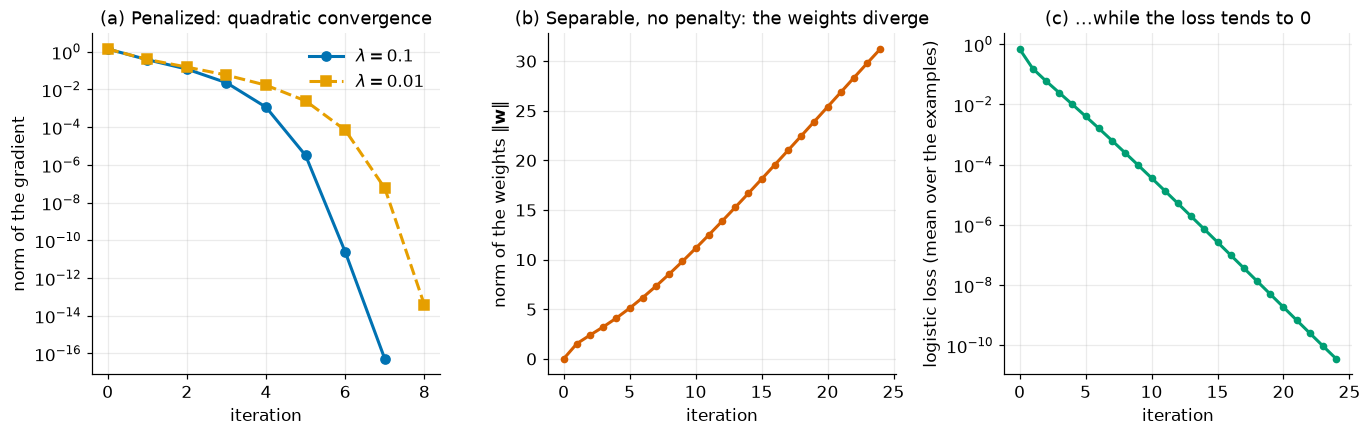

In [27]:
# Figure 6.7 — Newton's method on well-posed and on separable problems
def figure_6_7():
    hist_a = logistic_newton(Ztr_bc, ytr_bc, lam=0.1)[2]
    hist_b = logistic_newton(Ztr_bc, ytr_bc, lam=0.01)[2]
    fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.1))
    ax = axes[0]
    ax.semilogy(hist_a["iteration"], hist_a["gradient norm"], "o-", color=BLUE, lw=2, label=r"$\lambda = 0.1$")
    ax.semilogy(hist_b["iteration"], hist_b["gradient norm"], "s--", color=ORANGE, lw=2, label=r"$\lambda = 0.01$")
    ax.set(xlabel="iteration", ylabel="norm of the gradient", title="(a) Penalized: quadratic convergence")
    ax.legend(frameon=False)
    ax = axes[1]
    ax.plot(hist_iris["iteration"], hist_iris["weight norm"], "o-", color=VERMILION, lw=2, ms=4)
    ax.set(xlabel="iteration", ylabel=r"norm of the weights $\|\mathbf{w}\|$", title="(b) Separable, no penalty: the weights diverge")
    ax = axes[2]
    ax.semilogy(hist_iris["iteration"], hist_iris["loss"], "o-", color=GREEN, lw=2, ms=4)
    ax.set(xlabel="iteration", ylabel="logistic loss (mean over the examples)", title="(c) ...while the loss tends to 0")
    fig.tight_layout()
    plt.show()

figure_6_7()

## 6.5 Regularized logistic regression

### 6.5.1 The penalty, and the meaning of $C$

The cure is the one we used for least squares: add a penalty on the size of the weights. The **$\ell_2$-regularized logistic regression** minimizes

$$
J_\lambda(b, \mathbf{w}) = \frac1n\sum_{i=1}^n\log\big(1 + e^{-m_i}\big) + \frac{\lambda}{2}\|\mathbf{w}\|_2^2 ,
$$

the average log-loss plus a penalty on the weights (not on the intercept). scikit-learn uses a different but equivalent parametrization: it minimizes $\tfrac12\|\mathbf{w}\|^2 + C\sum_i\log(1 + e^{-m_i})$, and dividing this by $Cn$ gives $J_\lambda$ with

$$
\boxed{\ \lambda = \frac{1}{C\,n}\ }
$$

so $C$ is the **inverse regularization strength** (per example): *small $C$ means strong regularization and a rigid model, large $C$ means weak regularization and a flexible one*, as announced in Chapter 5. Note that $\lambda$ depends on $n$ through this relation: the same $C$ means a weaker penalty, relative to the data term, when the training set is larger, in line with the idea that with more data we can afford a more flexible model.

**Proposition 6.11 (the penalty restores existence and uniqueness).** If both classes are present in the training set and $\lambda > 0$, then $J_\lambda$ has a **unique** minimizer, whether or not the classes are separable.

:::{admonition} Proof
:class: dropdown
*Uniqueness.* The Hessian of $J_\lambda$ is $\frac1n\tilde{\mathbf{X}}^\top\mathbf{S}\tilde{\mathbf{X}} + \lambda\,\mathrm{diag}(0, 1, \dots, 1)$. For a vector $\mathbf{v} = (v_0, \mathbf{v}_w)$: if $\mathbf{v}_w \ne \mathbf{0}$ the second term is $\lambda\lVert\mathbf{v}_w\rVert^2 > 0$; if $\mathbf{v}_w = \mathbf{0}$ and $v_0 \ne 0$ the first term is $\frac{v_0^2}{n}\sum_i p_i(1 - p_i) > 0$. So the Hessian is positive definite and $J_\lambda$ is strictly convex: it has at most one minimizer.

*Existence.* Since $\log(1 + e^{-m}) > 0$, we have $J_\lambda(b, \mathbf{w}) \ge \frac\lambda2\|\mathbf{w}\|^2$, so the set $\{J_\lambda \le J_\lambda(\mathbf{0}, 0) = \log 2\}$ has $\|\mathbf{w}\|^2 \le 2\log 2/\lambda$: the weights are bounded there. The intercept is bounded too: pick an example $i$ with $y_i = 1$ and an example $j$ with $y_j = 0$. With $\mathbf{w}$ bounded, if $b \to +\infty$ then $z_j \to +\infty$ and the term $\log(1 + e^{z_j}) \to \infty$; if $b \to -\infty$ then $z_i \to -\infty$ and the term $\log(1 + e^{-z_i}) \to \infty$. So the sublevel set is compact, and the continuous function $J_\lambda$ attains its minimum on it. $\square$
:::

We check the correspondence $\lambda = 1/(Cn)$ once more and look at what the penalty does as a function of $C$. For the 426 training patients we compute, for $C$ from $10^{-4}$ to $10^4$, the **10-fold cross-validated** log-loss and accuracy (with the standardization inside the pipeline, as always), the training log-loss and accuracy, and the norm of the weights.

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict

C_grid = np.logspace(-4, 4, 17)
cv_bc = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
rows, coef_path = [], []
for C in C_grid:
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=20000))
    p_cv = cross_val_predict(pipe, Xtr_bc, ytr_bc, cv=cv_bc, method="predict_proba")[:, 1]
    pipe.fit(Xtr_bc, ytr_bc)
    p_tr = pipe.predict_proba(Xtr_bc)[:, 1]
    rows.append({"C": C, "CV log-loss": log_loss(ytr_bc, p_cv), "CV accuracy": accuracy_score(ytr_bc, p_cv > 0.5),
                 "train log-loss": log_loss(ytr_bc, p_tr), "train accuracy": pipe.score(Xtr_bc, ytr_bc),
                 "norm of w": np.linalg.norm(pipe[-1].coef_)})
    coef_path.append(pipe[-1].coef_[0].copy())
path_df = pd.DataFrame(rows).set_index("C")
coef_path = np.array(coef_path)
print(path_df.to_string(float_format=lambda v: f"{v:.4f}"))
C_cv = path_df["CV log-loss"].idxmin()
size_feats = ["mean radius", "mean perimeter", "mean area"]
print("\nstandardized coefficients of the three size features:")
print(pd.DataFrame(coef_path[:, [list(bc.data.columns).index(f) for f in size_feats]], index=C_grid, columns=size_feats).loc[[0.1, 1, 10, 100]].round(2).to_string())
print(f"\nC chosen by the cross-validated log-loss: {C_cv:g}  (lambda = 1/(C n) = {1 / (C_cv * len(ytr_bc)):.5f});   best cross-validated accuracy: {path_df['CV accuracy'].max():.4f} at C = {path_df['CV accuracy'].idxmax():.3g}")

              CV log-loss  CV accuracy  train log-loss  train accuracy  norm of w
C                                                                                
0.000100           0.5982       0.6385          0.5923          0.6455     0.0523
0.000316           0.5124       0.7512          0.5016          0.7793     0.1340
0.001000           0.3924       0.8873          0.3794          0.8967     0.2833
0.003162           0.2789       0.9390          0.2665          0.9413     0.5071
0.010000           0.1948       0.9484          0.1832          0.9531     0.8146
0.031623           0.1402       0.9624          0.1278          0.9695     1.2313
0.100000           0.1075       0.9671          0.0921          0.9812     1.8010
0.316228           0.0890       0.9718          0.0691          0.9859     2.6032
1.000000           0.0835       0.9765          0.0539          0.9883     3.7658
3.162278           0.0959       0.9695          0.0423          0.9906     5.7075
10.000000       

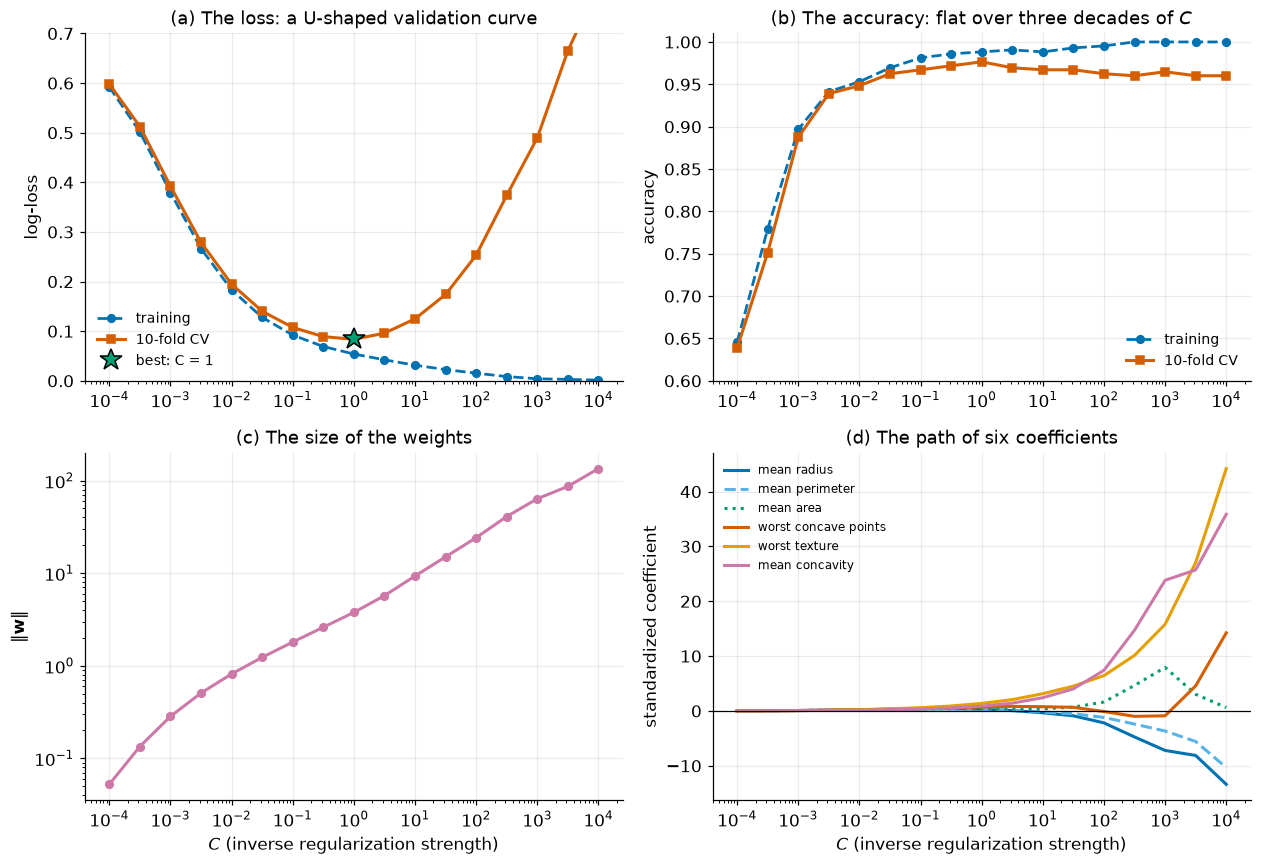

In [29]:
# Figure 6.8 — the regularization path of logistic regression on Breast Cancer
def figure_6_8():
    fig, axes = plt.subplots(2, 2, figsize=(11.6, 8.0))
    ax = axes[0, 0]
    ax.semilogx(C_grid, path_df["train log-loss"], "o--", color=BLUE, lw=1.8, ms=5, label="training")
    ax.semilogx(C_grid, path_df["CV log-loss"], "s-", color=VERMILION, lw=2, ms=5, label="10-fold CV")
    ax.plot(C_cv, path_df.loc[C_cv, "CV log-loss"], "*", ms=15, color=GREEN, mec="black", label=f"best: C = {C_cv:g}")
    ax.set(ylabel="log-loss", title="(a) The loss: a U-shaped validation curve", ylim=(0, 0.7))
    ax.legend(frameon=False, fontsize=9)
    ax = axes[0, 1]
    ax.semilogx(C_grid, path_df["train accuracy"], "o--", color=BLUE, lw=1.8, ms=5, label="training")
    ax.semilogx(C_grid, path_df["CV accuracy"], "s-", color=VERMILION, lw=2, ms=5, label="10-fold CV")
    ax.set(ylabel="accuracy", title="(b) The accuracy: flat over three decades of $C$", ylim=(0.6, 1.01))
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    ax = axes[1, 0]
    ax.loglog(C_grid, path_df["norm of w"], "o-", color=PURPLE, lw=2, ms=5)
    ax.set(xlabel=r"$C$ (inverse regularization strength)", ylabel=r"$\|\mathbf{w}\|$", title="(c) The size of the weights")
    ax = axes[1, 1]
    feats = {"mean radius": BLUE, "mean perimeter": SKY, "mean area": GREEN, "worst concave points": VERMILION,
             "worst texture": ORANGE, "mean concavity": PURPLE}
    styles = ["-", "--", ":", "-", "-", "-"]
    for (name, color), ls in zip(feats.items(), styles):
        ax.semilogx(C_grid, coef_path[:, list(bc.data.columns).index(name)], color=color, lw=2, ls=ls, label=name)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xlabel=r"$C$ (inverse regularization strength)", ylabel="standardized coefficient", title="(d) The path of six coefficients")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    fig.tight_layout()
    plt.show()

figure_6_8()

Four lessons can be read from Figure 6.8 and the table.

1. **The loss has a clear optimum, the accuracy hardly does.** The cross-validated log-loss is U-shaped, with its minimum ($0.084$) at $C = 1$, and it rises to $0.125$ at $C = 10$ and to $0.25$ at $C = 100$. The cross-validated accuracy, on the other hand, is between $0.962$ and $0.977$ for all $C$ from $0.03$ to $1$, and stays at or above $0.96$ up to $C = 10^4$, even though the model is then very overconfident. *Accuracy ignores the probabilities, so it cannot see the damage that weak regularization does to them.* This is the point of Section 5.6: we should tune with a metric that measures what we care about, and when we care about probabilities, log-loss is one such metric.
2. **The training loss decreases monotonically** with $C$ and reaches $0.0013$ at $C = 10^4$, as expected from Proposition 6.10: the more freedom, the better the fit to the training set, and the training curve cannot choose $C$ (the same lesson as that of $k$ in Section 4.3.2).
3. **The weights grow like a power of $C$** (panel c), from $0.05$ at $C = 10^{-4}$ to $135$ at $C = 10^4$: the regularization strength acts on the weights exactly as the SVD shrinkage of Section 6.3.2 did, and the norm bound $B = \|\mathbf{w}\|$ of Proposition 3.6 and Theorem 3.7 is, in effect, tuned by $C$. This is the bridge between the theory of Chapter 3 and the practice: **the capacity of a linear classifier is controlled by the size of its weights, and $C$ is the knob.**
4. **Collinearity returns, in classification** (panel d). `mean radius`, `mean perimeter` and `mean area` are almost the same feature (Section 6.2.4). For $C \le 1$ they all have positive, similar coefficients; at $C = 10$ the first two become negative ($-0.34$ and $-0.19$) and at $C = 100$ they are $-2.18$ and $-1.18$, while `mean area` is $+1.63$: the model compensates the large negative weights with large positive weights on correlated features. A tumor is not "less malignant when it is larger": the individual coefficients of a collinear model, with weak regularization, are meaningless. Strong regularization restores a sensible reading, because it shares the weight among the redundant features.

We finish with the test set, which has not been touched until now (the discipline of Section 5.7). We compare the model with $C$ chosen by the cross-validated log-loss against the unpenalized model of the previous section, and we apply the exact McNemar test of Section 5.5.1 to the difference in errors.

In [30]:
from scipy import stats

m_reg = make_pipeline(StandardScaler(), LogisticRegression(C=C_cv, max_iter=20000)).fit(Xtr_bc, ytr_bc)
m_unp = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=3000, tol=1e-12)).fit(Xtr_bc, ytr_bc)
rows = {}
for name, m in [(f"regularized, C = {C_cv:g} (chosen by CV)", m_reg), ("no penalty (maximum likelihood)", m_unp)]:
    p_te = np.clip(m.predict_proba(Xte_bc)[:, 1], 1e-15, 1 - 1e-15)
    rows[name] = {"errors": int((m.predict(Xte_bc) != yte_bc).sum()), "accuracy": m.score(Xte_bc, yte_bc),
                  "log-loss": log_loss(yte_bc, p_te), "AUC": roc_auc_score(yte_bc, p_te)}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.4f}"))

ok_reg, ok_unp = m_reg.predict(Xte_bc) == yte_bc, m_unp.predict(Xte_bc) == yte_bc
only_reg_wrong, only_unp_wrong = int((~ok_reg & ok_unp).sum()), int((ok_reg & ~ok_unp).sum())
p_mcnemar = stats.binomtest(min(only_reg_wrong, only_unp_wrong), only_reg_wrong + only_unp_wrong, 0.5).pvalue
print(f"\nMcNemar: wrong only with the penalty = {only_reg_wrong}, wrong only without = {only_unp_wrong}, exact p-value = {p_mcnemar:.3f}")

                                   errors  accuracy  log-loss    AUC
regularized, C = 1 (chosen by CV)  5.0000    0.9650    0.0776 0.9962
no penalty (maximum likelihood)    9.0000    0.9371    2.1738 0.9229

McNemar: wrong only with the penalty = 1, wrong only without = 5, exact p-value = 0.219


The regularized model makes 5 errors on the 143 test patients and the unpenalized one 9; its AUC is $0.996$ against $0.923$, and its log-loss $0.078$ against $2.17$. In the McNemar comparison the two models disagree on 6 patients, and the regularized one is right on 5 of them: the $p$-value, $0.22$, does **not** allow us to conclude that the difference in *accuracy* is real. The difference in log-loss is of a different order of magnitude, and no test is needed to see that one set of probabilities is usable and the other is not. This is the moral of Chapter 5 in a single table: *which metric you look at decides what you see.*

## 6.6 More than two classes: the softmax model

### 6.6.1 From the sigmoid to the softmax

With $K$ classes, labeled $0, \dots, K - 1$, we give each class its own score, $z_k = \mathbf{w}_k^\top\mathbf{x} + b_k$, and turn the $K$ scores into probabilities with the **softmax function**,

$$
p_k(\mathbf{x}) = \mathbb{P}(y = k \mid \mathbf{x}) = \frac{e^{z_k}}{\sum_{j=0}^{K-1} e^{z_j}}, \qquad k = 0, \dots, K - 1 .
$$

The probabilities are positive and add up to 1, and the largest score gets the largest probability (the "soft" maximum). The maximum likelihood principle, applied exactly as in Section 6.4.2 with the categorical distribution, gives the **cross-entropy loss**

$$
L(\mathbf{W}, \mathbf{b}) = -\sum_{i=1}^n \log p_{y_i}(\mathbf{x}_i),
$$

the multi-class version of the log-loss of Section 6.4.2. Its gradient has the same shape as before: with $y_{ik} = 1$ if $y_i = k$ and $0$ otherwise,

$$
\nabla_{\mathbf{w}_k} L = \sum_{i=1}^n \big(p_k(\mathbf{x}_i) - y_{ik}\big)\,\mathbf{x}_i ,
$$

again "the features times the residual". For $K = 2$ the model reduces to the logistic regression of the previous sections, with $\mathbf{w} = \mathbf{w}_1 - \mathbf{w}_0$ (Exercise 6.5). The loss is convex, and with an $\ell_2$ penalty it is strictly convex in the weights: everything we said about separable data and about $C$ carries over.

One detail deserves attention. **Softmax probabilities do not change if the same vector is added to all the weight vectors**: replacing $\mathbf{w}_k$ by $\mathbf{w}_k + \mathbf{c}$ for every $k$ multiplies numerator and denominator by $e^{\mathbf{c}^\top\mathbf{x}}$, which cancels. The unpenalized loss therefore has a whole line of minimizers (the model has one redundant direction per feature), and it is the penalty that selects one of them: the one with the smallest $\ell_2$ norm, which turns out to satisfy $\sum_k \mathbf{w}_k = \mathbf{0}$ (Exercise 6.5). We can check this on real data.

### 6.6.2 Handwritten digits

The **Digits** data set (Chapter 4) has 1797 images of $8 \times 8$ pixels and 10 classes. We hold out 25% of the images in a stratified split, standardize the 64 pixels with the statistics of the training set, and choose $C$ by 5-fold cross-validated log-loss (the metric of Section 6.5, now with ten classes).

In [31]:
from scipy.special import softmax
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix

digits = load_digits()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(digits.data, digits.target, test_size=0.25, random_state=SEED, stratify=digits.target)
print(f"training: {Xd_tr.shape[0]} images, test: {Xd_te.shape[0]} images, {Xd_tr.shape[1]} pixels, {len(np.unique(yd_tr))} classes")

C_dg_grid = np.logspace(-3, 2, 11)
cv_dg = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for C in C_dg_grid:
    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
    p_cv = cross_val_predict(pipe, Xd_tr, yd_tr, cv=cv_dg, method="predict_proba")
    rows.append({"C": C, "CV log-loss": log_loss(yd_tr, p_cv), "CV accuracy": accuracy_score(yd_tr, p_cv.argmax(axis=1))})
dg_path = pd.DataFrame(rows).set_index("C")
print(dg_path.to_string(float_format=lambda v: f"{v:.4f}"))
C_dg = dg_path["CV log-loss"].idxmin()

pipe_dg = make_pipeline(StandardScaler(), LogisticRegression(C=C_dg, max_iter=5000)).fit(Xd_tr, yd_tr)
pred_dg = pipe_dg.predict(Xd_te)
print(f"\nC chosen by the cross-validated log-loss: {C_dg:.3g};  test accuracy {accuracy_score(yd_te, pred_dg):.4f} "
      f"({int((pred_dg != yd_te).sum())} errors out of {len(yd_te)}),  test log-loss {log_loss(yd_te, pipe_dg.predict_proba(Xd_te)):.4f}")

# the model really is a softmax of ten linear scores
W_dg, b_dg = pipe_dg[-1].coef_, pipe_dg[-1].intercept_
scores = pipe_dg[0].transform(Xd_te) @ W_dg.T + b_dg
print(f"max |softmax(scores) - predict_proba| = {np.abs(softmax(scores, axis=1) - pipe_dg.predict_proba(Xd_te)).max():.1e}")
print(f"largest |sum over the 10 classes of the weight of a pixel| = {np.abs(W_dg.sum(axis=0)).max():.1e}  (the penalty picks the solution with sum_k w_k = 0)")

# the most frequent confusions on the test set
cm = confusion_matrix(yd_te, pred_dg)
np.fill_diagonal(cm, 0)
worst = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if cm[i, j] > 0), reverse=True)[:5]
print("most frequent confusions (true -> predicted: count):", ", ".join(f"{i} -> {j}: {c}" for c, i, j in worst))

training: 1347 images, test: 450 images, 64 pixels, 10 classes


            CV log-loss  CV accuracy
C                                   
0.001000         1.2705       0.9035
0.003162         0.7663       0.9258
0.010000         0.4479       0.9391
0.031623         0.2734       0.9510
0.100000         0.1810       0.9614
0.316228         0.1356       0.9621
1.000000         0.1184       0.9659
3.162278         0.1183       0.9673
10.000000        0.1283       0.9673
31.622777        0.1503       0.9659
100.000000       0.1984       0.9621

C chosen by the cross-validated log-loss: 3.16;  test accuracy 0.9733 (12 errors out of 450),  test log-loss 0.0999
max |softmax(scores) - predict_proba| = 0.0e+00
largest |sum over the 10 classes of the weight of a pixel| = 1.2e-14  (the penalty picks the solution with sum_k w_k = 0)
most frequent confusions (true -> predicted: count): 8 -> 1: 3, 1 -> 8: 2, 9 -> 8: 1, 9 -> 7: 1, 8 -> 5: 1


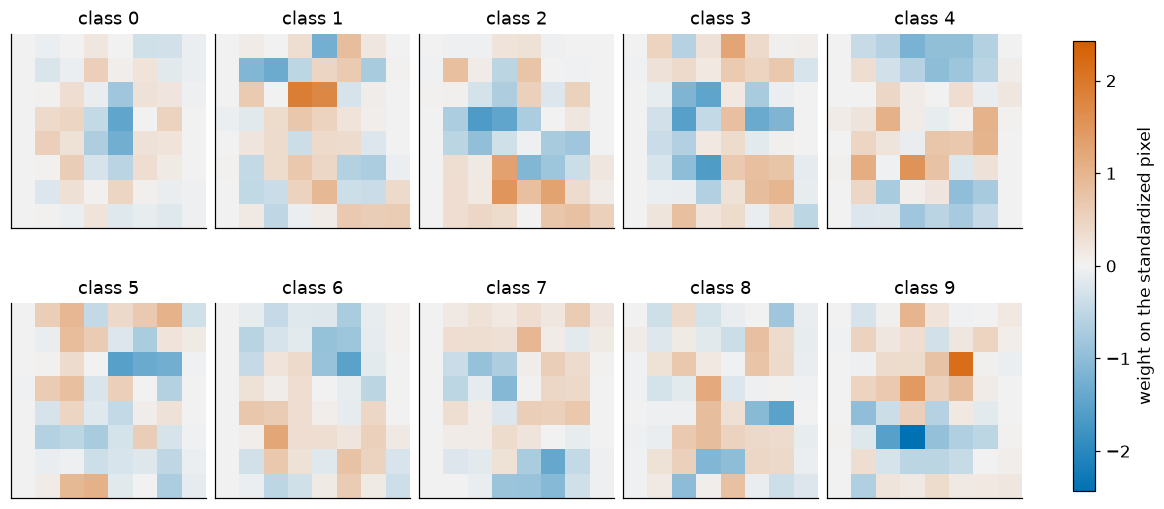

In [32]:
# Figure 6.9 — what the ten linear scores look at
from matplotlib.colors import LinearSegmentedColormap

def figure_6_9():
    W = W_dg.reshape(10, 8, 8)
    vmax = np.abs(W).max()
    cmap = LinearSegmentedColormap.from_list("blue_gray_vermilion", [BLUE, "#F2F2F2", VERMILION])
    fig, axes = plt.subplots(2, 5, figsize=(10.5, 4.9), layout="constrained")
    for k, ax in enumerate(axes.ravel()):
        im = ax.imshow(W[k], cmap=cmap, vmin=-vmax, vmax=vmax)
        ax.set_title(f"class {k}")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.colorbar(im, ax=axes, shrink=0.85, label="weight on the standardized pixel")
    plt.show()

figure_6_9()

The cross-validated log-loss is minimal at $C = 3.16$ (it is almost the same at $C = 1$: $0.118$ in both cases), and the model reaches a test accuracy of $0.973$, with 12 errors out of 450 images and a test log-loss of $0.100$. The check cells confirm two facts of the theory: the probabilities returned by scikit-learn are exactly the softmax of the ten linear scores, and the weights of each pixel add up to zero over the ten classes, up to the tolerance of the solver.

Figure 6.9 shows what the ten scores look at: each panel is the *template* with which the image is compared, since a score is the inner product of the standardized image with its template. Orange pixels are evidence for the digit, blue pixels are evidence against it. A few templates can be interpreted: that of "0" has negative weights at the center, where a zero has a hole, and weights close to zero on the border. Most of the others, however, are **noisy and hard to read**, much less tidy than the pictures of "average digits" that one might expect. There are two reasons. The weights are not the profile of a digit but the *difference* between one digit and the nine others, so that a pixel that is informative for all of them gets a small weight; and neighboring pixels are strongly correlated, so that the penalty spreads the weight among them in an arbitrary way, exactly as it did for `mean radius` and `mean perimeter` (Section 6.5). This is a limit of the idea that "linear models are interpretable": their weights can be inspected, but a pattern in them must not be over-interpreted. Crude as the matching is, it is right for 438 of the 450 test images. The errors are concentrated on a few pairs (five of the twelve involve the digits 8 and 1, as the list printed above shows).

A comparison that we shall repeat in Section 6.8: the 3-nearest-neighbor classifier of Chapter 4, applied to the *raw* pixels, reaches a test accuracy of 0.984 on this split. The nonparametric method is slightly better than the linear model on this problem, and the reason is geometric: handwritten digits of the same class lie near each other in pixel space, while a linear score cannot represent "close to any of these hundred examples". This limitation is the motivation for the feature maps of the next section, and for the methods of Chapters 9 to 14.

## 6.7 Feature maps: linear models, nonlinear functions

### 6.7.1 A linear model in a new space

A linear model is linear in the **parameters**, not necessarily in the original inputs. If $\boldsymbol\varphi:\mathbb{R}^d \to \mathbb{R}^p$ is a fixed map (a **feature map**), the model $f(\mathbf{x}) = \mathbf{w}^\top\boldsymbol\varphi(\mathbf{x}) + b$ is linear in $\mathbf{w}$, so that everything of this chapter applies unchanged to the matrix $\boldsymbol\Phi$ whose rows are $\boldsymbol\varphi(\mathbf{x}_i)^\top$: the ridge estimator, the SVD shrinkage, the leave-one-out shortcut, the logistic loss and Newton's method. The classic choice is the **polynomial map**: all monomials of the inputs up to a given degree. With $d = 10$ inputs, degree 2 gives $p = 65$ features (10 linear terms, 10 squares, 45 products) and degree 3 gives $p = 285$. The decision boundary or regression surface in the original space becomes a polynomial surface, with the flexibility that this implies, and the number of parameters grows quickly: it can exceed $n$.

:::{admonition} Pitfall
:class: warning
**Always standardize the expanded features, inside the pipeline.** Monomials of different degrees have wildly different scales, and the ridge penalty, which treats all coordinates equally, would penalize them unequally (the lesson of Section 6.3.1). In scikit-learn, the pipeline `PolynomialFeatures -> StandardScaler -> model` must be fitted on the training part of each split only. When $p > n$ the unpenalized least-squares problem has infinitely many solutions; `numpy.linalg.lstsq` and `LinearRegression` return the one of smallest norm, which is the limit of ridge as $\lambda \to 0^+$ (Proposition 6.4).
:::

We test the idea on **Diabetes**, with training sets of $n = 100$ patients, the regime in which regularization matters most (Section 6.3.4). For each degree 1, 2 and 3 and each of 30 random splits, we fit the ridge estimator for a grid of $\lambda$ with the SVD formula of Proposition 6.4, and record the test mean squared error on the remaining 342 patients. We also compute the minimum-norm least-squares fit and the ridge fit with $\lambda$ chosen by 10-fold cross-validation (`RidgeCV`).

In [33]:
from sklearn.preprocessing import PolynomialFeatures

degrees = (1, 2, 3)
lams_poly = np.logspace(-3, 5, 17)
n_tr_poly, reps_poly = 100, 30
curve = {deg: np.zeros((reps_poly, len(lams_poly))) for deg in degrees}
mn_ols = {deg: [] for deg in degrees}
cv_ridge = {deg: [] for deg in degrees}
rs = np.random.default_rng(SEED)
for r in range(reps_poly):
    perm = rs.permutation(len(y_diab))
    tr, te = perm[:n_tr_poly], perm[n_tr_poly:]
    for deg in degrees:
        feat = make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler())
        Ftr, Fte = feat.fit_transform(diab.data.iloc[tr]), feat.transform(diab.data.iloc[te])
        mu = y_diab[tr].mean()
        U, sv, Vt = np.linalg.svd(Ftr, full_matrices=False)
        c = U.T @ (y_diab[tr] - mu)
        for k, lam in enumerate(lams_poly):
            curve[deg][r, k] = mse(y_diab[te], mu + Fte @ (Vt.T @ ((sv / (sv ** 2 + lam)) * c)))
        w0 = np.linalg.lstsq(Ftr, y_diab[tr] - mu, rcond=None)[0]
        mn_ols[deg].append(mse(y_diab[te], mu + Fte @ w0))
        rc = RidgeCV(alphas=lams_poly, cv=10, scoring="neg_mean_squared_error").fit(Ftr, y_diab[tr])
        cv_ridge[deg].append(mse(y_diab[te], rc.predict(Fte)))

n_feat = {deg: PolynomialFeatures(deg, include_bias=False).fit(diab.data).n_output_features_ for deg in degrees}
mean_curve = {deg: curve[deg].mean(axis=0) for deg in degrees}
tab = pd.DataFrame({
    "features p": [n_feat[d] for d in degrees],
    "min-norm least squares": [np.mean(mn_ols[d]) for d in degrees],
    "best fixed lambda": [lams_poly[mean_curve[d].argmin()] for d in degrees],
    "ridge, best fixed lambda": [mean_curve[d].min() for d in degrees],
    "ridge, lambda by 10-fold CV": [np.mean(cv_ridge[d]) for d in degrees]}, index=[f"degree {d}" for d in degrees])
print(f"test MSE averaged over {reps_poly} random splits with n = {n_tr_poly} training patients (the variance of the target is about {y_diab.var():.0f})")
print(tab.to_string(float_format=lambda v: f"{v:.1f}"))

test MSE averaged over 30 random splits with n = 100 training patients (the variance of the target is about 5930)
          features p  min-norm least squares  best fixed lambda  ridge, best fixed lambda  ridge, lambda by 10-fold CV
degree 1          10                  3267.6               31.6                    3160.6                       3213.9
degree 2          65                 18949.4              100.0                    3655.8                       3765.4
degree 3         285                 38221.4              316.2                    3765.6                       3843.2


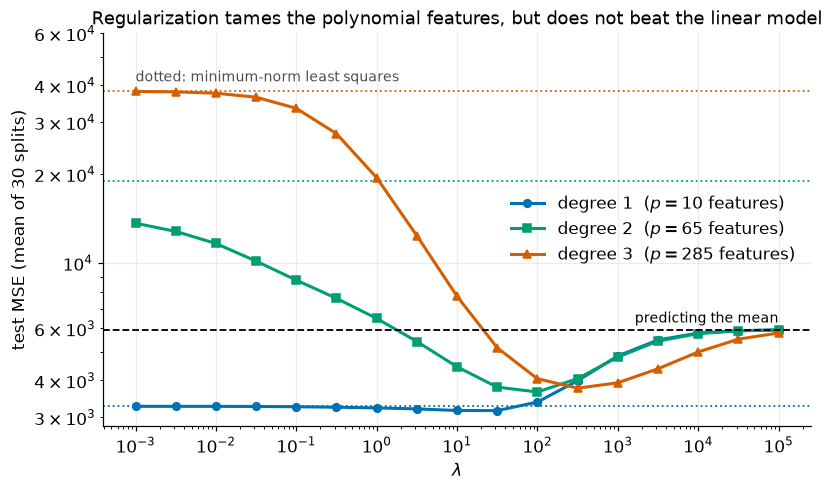

In [34]:
# Figure 6.10 — polynomial ridge on Diabetes with 100 training patients
def figure_6_10():
    fig, ax = plt.subplots(figsize=(7.6, 4.6))
    for deg, color, marker in zip(degrees, [BLUE, GREEN, VERMILION], ["o", "s", "^"]):
        ax.loglog(lams_poly, mean_curve[deg], marker=marker, ms=5, lw=2, color=color, label=f"degree {deg}  ($p = {n_feat[deg]}$ features)")
        ax.axhline(np.mean(mn_ols[deg]), color=color, lw=1.2, ls=":")
    ax.axhline(y_diab.var(), color="black", lw=1.2, ls="--")
    ax.text(lams_poly[-1], y_diab.var() * 1.06, "predicting the mean", ha="right", fontsize=9)
    ax.text(lams_poly[0], np.mean(mn_ols[3]) * 1.08, "dotted: minimum-norm least squares", fontsize=9, color="0.3")
    ax.set(xlabel=r"$\lambda$", ylabel="test MSE (mean of 30 splits)", title="Regularization tames the polynomial features, but does not beat the linear model")
    ax.set_ylim(2800, 6e4)
    ax.legend(frameon=False, loc="center right")
    fig.tight_layout()
    plt.show()

figure_6_10()

Three observations. First, **unregularized polynomial regression is a disaster at this sample size**: the minimum-norm fits have a test error of $18949$ (degree 2) and $38221$ (degree 3), that is, three and six times the variance of the target (about $5930$), while the degree-1 fit has $3268$. Second, ridge repairs almost all the damage: with the best fixed $\lambda$ the errors fall to $3161$, $3656$ and $3766$, and the best $\lambda$ grows with the number of features, from $31.6$ to $100$ and $316$, as the shrinkage of Section 6.3.2 would suggest. Third, and this is the honest message of the experiment, **the expansion does not pay off on this data set**: even the best regularized degree-2 and degree-3 models ($3656$ and $3766$) are worse than the plain linear model ($3161$), and the same is true when $\lambda$ is chosen by cross-validation ($3214$, $3765$ and $3843$). The relationship between the ten predictors and disease progression is close to linear, and the extra flexibility only adds variance, which ridge removes but cannot turn into signal. The value of a richer feature map depends on the problem. The next experiment is one in which it does.

### 6.7.2 The dual form of ridge regression

In the polynomial experiment a computational remark is in order: with $p = 285$ features and $n = 100$ patients the primal ridge problem involves a $285 \times 285$ matrix, although the information in the data is a $100 \times 100$ matrix. The following identity shows how to solve the problem in the smaller space, and it will be the starting point of Chapter 9.

**Proposition 6.12 (dual form of ridge regression).** Let $\mathbf{X} \in \mathbb{R}^{n \times p}$ and $\lambda > 0$. Then
$$
\big(\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I}_p\big)^{-1}\mathbf{X}^\top = \mathbf{X}^\top\big(\mathbf{X}\mathbf{X}^\top + \lambda\mathbf{I}_n\big)^{-1}.
$$
Consequently the ridge solution (for centered data) can be written $\hat{\mathbf{w}} = \mathbf{X}^\top\boldsymbol\alpha$ with $\boldsymbol\alpha = (\mathbf{X}\mathbf{X}^\top + \lambda\mathbf{I}_n)^{-1}\mathbf{y}$: the weight vector is a linear combination of the training points.

:::{admonition} Proof
:class: dropdown
Both sides make sense: $\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I}_p$ and $\mathbf{X}\mathbf{X}^\top + \lambda\mathbf{I}_n$ are positive definite, hence invertible, because $\lambda > 0$. Multiplying out gives $\mathbf{X}^\top(\mathbf{X}\mathbf{X}^\top + \lambda\mathbf{I}_n) = \mathbf{X}^\top\mathbf{X}\mathbf{X}^\top + \lambda\mathbf{X}^\top = (\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I}_p)\mathbf{X}^\top$. Multiplying this identity on the left by $(\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I}_p)^{-1}$ and on the right by $(\mathbf{X}\mathbf{X}^\top + \lambda\mathbf{I}_n)^{-1}$ gives the claim. $\square$
:::

The matrix $\mathbf{X}\mathbf{X}^\top$, of size $n \times n$, contains only the **inner products** $\boldsymbol\varphi(\mathbf{x}_i)^\top\boldsymbol\varphi(\mathbf{x}_j)$ between pairs of training points, and the prediction at a new point is $\sum_i \alpha_i\,\boldsymbol\varphi(\mathbf{x}_i)^\top\boldsymbol\varphi(\mathbf{x})$. The feature vectors enter *only through inner products*. If a function can compute these inner products without ever building the vectors, the dimension $p$ can be enormous, even infinite. This is the **kernel trick**, the subject of Chapter 9. We verify the identity numerically for degree 3.

In [35]:
import time

deg3 = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler())
perm_dual = np.random.default_rng(SEED).permutation(len(y_diab))
tr_dual, te_dual = perm_dual[:n_tr_poly], perm_dual[n_tr_poly:]
F3 = deg3.fit_transform(diab.data.iloc[tr_dual])
F3_te = deg3.transform(diab.data.iloc[te_dual])
yc3 = y_diab[tr_dual] - y_diab[tr_dual].mean()
lam3, (n3, p3) = 100.0, F3.shape

t0 = time.perf_counter()
for _ in range(20):
    w_primal = np.linalg.solve(F3.T @ F3 + lam3 * np.eye(p3), F3.T @ yc3)             # a p x p system
t_primal = (time.perf_counter() - t0) / 20
t0 = time.perf_counter()
for _ in range(20):
    alpha = np.linalg.solve(F3 @ F3.T + lam3 * np.eye(n3), yc3)                        # an n x n system
    w_dual = F3.T @ alpha
t_dual = (time.perf_counter() - t0) / 20

print(f"design matrix: n = {n3}, p = {p3};  primal system {p3} x {p3}, dual system {n3} x {n3}")
print(f"max |w_primal - w_dual| = {np.abs(w_primal - w_dual).max():.1e};  max difference between the test predictions = {np.abs(F3_te @ w_primal - F3_te @ w_dual).max():.1e}")
print(f"time per solve: primal {1000 * t_primal:.2f} ms, dual {1000 * t_dual:.2f} ms")

design matrix: n = 100, p = 285;  primal system 285 x 285, dual system 100 x 100
max |w_primal - w_dual| = 1.4e-14;  max difference between the test predictions = 4.5e-13
time per solve: primal 15.27 ms, dual 3.44 ms


The two routes give the same weights, to rounding error (differences of about $10^{-12}$, relative to weights of order 1), and the dual system is smaller. The timings depend on the machine, but with $p$ almost three times $n$ the dual route wins, and the gap grows as $p^3/n^3$ when $p \gg n$. When $p < n$, the primal route is the cheaper one.

### 6.7.3 Polynomial features for classification

We now look at a problem in which the extra flexibility can pay off, and in which we can *see* what regularization does. We keep two of the Breast Cancer features, `mean radius` and `mean texture`, so that the decision boundary can be drawn in the plane, and we give the classifier only **60 training patients**, a small sample, chosen at random. Three models are fitted by regularized logistic regression: the linear one (degree 1, $C = 1$), a degree-4 polynomial ($C = 1$), and a degree-8 polynomial with almost no penalty ($C = 10^4$), which has 44 features for 60 examples.

In [36]:
X2 = bc.data[["mean radius", "mean texture"]].to_numpy()

def poly_logit(deg, C):
    return make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(), LogisticRegression(C=C, max_iter=100000))

perm0 = np.random.default_rng(SEED).permutation(len(y_bc))
tr0, te0 = perm0[:60], perm0[60:]
configs_fig = [(1, 1.0), (4, 1.0), (8, 1e4)]
fits_fig = {cfg: poly_logit(*cfg).fit(X2[tr0], y_bc[tr0]) for cfg in configs_fig}
for cfg, m in fits_fig.items():
    p_te0 = np.clip(m.predict_proba(X2[te0])[:, 1], 1e-15, 1 - 1e-15)
    print(f"degree {cfg[0]}, C = {cfg[1]:g}:  train accuracy {m.score(X2[tr0], y_bc[tr0]):.3f},  test accuracy {m.score(X2[te0], y_bc[te0]):.3f},  test log-loss {log_loss(y_bc[te0], p_te0):.3f}")

degree 1, C = 1:  train accuracy 0.883,  test accuracy 0.886,  test log-loss 0.282
degree 4, C = 1:  train accuracy 0.900,  test accuracy 0.890,  test log-loss 0.252
degree 8, C = 10000:  train accuracy 0.983,  test accuracy 0.849,  test log-loss 1.458


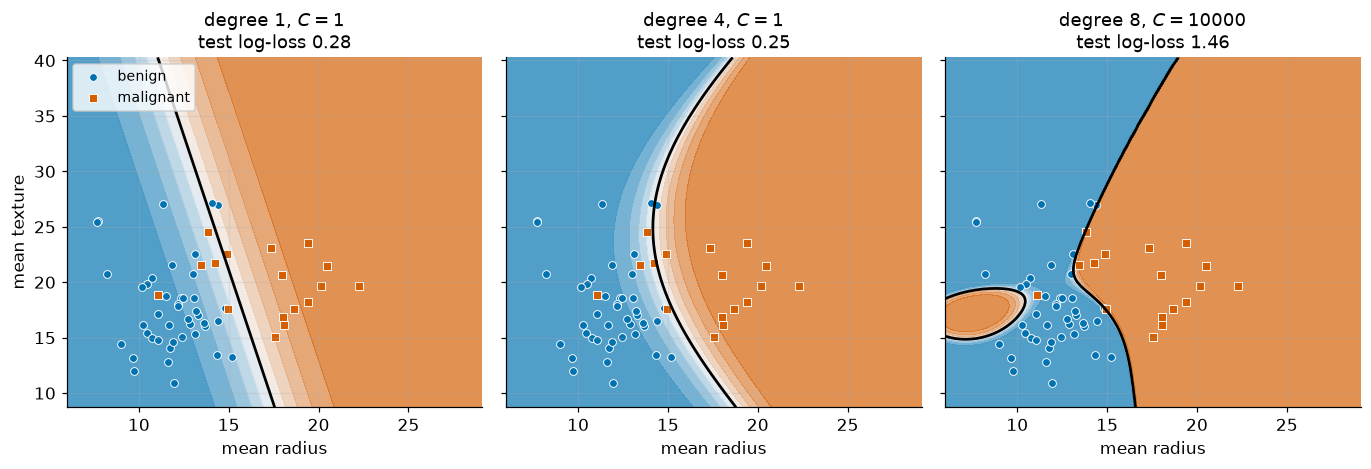

In [37]:
# Figure 6.11 — polynomial decision boundaries of regularized logistic regression, 60 training patients
def figure_6_11():
    gx = np.linspace(X2[:, 0].min() - 1, X2[:, 0].max() + 1, 300)
    gy = np.linspace(X2[:, 1].min() - 1, X2[:, 1].max() + 1, 300)
    GX, GY = np.meshgrid(gx, gy)
    grid = np.column_stack([GX.ravel(), GY.ravel()])
    cmap = LinearSegmentedColormap.from_list("blue_gray_vermilion", [BLUE, "#F2F2F2", VERMILION])
    fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.4), sharex=True, sharey=True)
    for ax, (cfg, m) in zip(axes, fits_fig.items()):
        P = m.predict_proba(grid)[:, 1].reshape(GX.shape)
        ax.contourf(GX, GY, P, levels=np.linspace(0, 1, 11), cmap=cmap, alpha=0.75)
        ax.contour(GX, GY, P, levels=[0.5], colors="black", linewidths=1.8)
        ax.scatter(X2[tr0][y_bc[tr0] == 0, 0], X2[tr0][y_bc[tr0] == 0, 1], s=26, color=BLUE, edgecolor="white", lw=0.6, label="benign")
        ax.scatter(X2[tr0][y_bc[tr0] == 1, 0], X2[tr0][y_bc[tr0] == 1, 1], s=26, color=VERMILION, marker="s", edgecolor="white", lw=0.6, label="malignant")
        ll = log_loss(y_bc[te0], np.clip(m.predict_proba(X2[te0])[:, 1], 1e-15, 1 - 1e-15))
        ax.set(xlabel="mean radius", title=f"degree {cfg[0]}, $C = {cfg[1]:g}$\ntest log-loss {ll:.2f}", xlim=(gx[0], gx[-1]), ylim=(gy[0], gy[-1]))
    axes[0].set_ylabel("mean texture")
    axes[0].legend(frameon=True, loc="upper left", fontsize=9)
    fig.tight_layout()
    plt.show()

figure_6_11()

The first model draws a straight line; the second a gently curved boundary; the third, with 44 free coefficients and almost no penalty, draws a boundary that bends around individual training points: it carves out an isolated "malignant" island on the left of the plot, in the middle of benign patients, and its probabilities change abruptly (sharp color transitions) in regions with no data. Its training accuracy is the highest of the three ($0.983$) and its test log-loss is five times that of the linear model. A single training set can mislead, so we repeat the experiment for 100 random training sets of 60 patients, with the same pipelines and with some other settings of $(\text{degree}, C)$, and average the test metrics.

In [38]:
configs_rep = [(1, 1.0), (2, 1.0), (4, 1.0), (8, 1.0), (8, 1e4)]
reps_clf = 100
res = {cfg: {"accuracy": [], "log-loss": []} for cfg in configs_rep}
rs = np.random.default_rng(SEED)
for r in range(reps_clf):
    perm = rs.permutation(len(y_bc))
    tr, te = perm[:60], perm[60:]
    if y_bc[tr].min() == y_bc[tr].max():
        continue
    for cfg in configs_rep:
        m = poly_logit(*cfg).fit(X2[tr], y_bc[tr])
        res[cfg]["accuracy"].append(m.score(X2[te], y_bc[te]))
        res[cfg]["log-loss"].append(log_loss(y_bc[te], np.clip(m.predict_proba(X2[te])[:, 1], 1e-15, 1 - 1e-15)))
tab_clf = pd.DataFrame({f"degree {d}, C = {C:g}": {"features": PolynomialFeatures(d, include_bias=False).fit(X2).n_output_features_,
                                                  "test accuracy": np.mean(v["accuracy"]), "test log-loss": np.mean(v["log-loss"])}
                        for (d, C), v in res.items()}).T
print(f"mean over {len(res[configs_rep[0]]['accuracy'])} random training sets of 60 patients (test set: the other 509)")
print(tab_clf.to_string(float_format=lambda v: f"{v:.3f}"))

mean over 100 random training sets of 60 patients (test set: the other 509)
                     features  test accuracy  test log-loss
degree 1, C = 1         2.000          0.879          0.293
degree 2, C = 1         5.000          0.882          0.282
degree 4, C = 1        14.000          0.887          0.277
degree 8, C = 1        44.000          0.887          0.316
degree 8, C = 10000    44.000          0.867          1.078


On average, the degree-4 model with $C = 1$ has a test log-loss about 5% lower than that of the linear model ($0.277$ against $0.293$), and the accuracies differ by less than one percentage point ($0.887$ against $0.879$): **a modest gain, obtained only with the right amount of regularization.** The degree-8 model with the same $C = 1$ is nearly as good ($0.316$ and an accuracy of $0.887$), which shows that *the penalty, rather than the degree, controls the complexity*: a flexible feature map with strong regularization is a safe choice. The same degree-8 map with $C = 10^4$ has a test log-loss of $1.08$, almost four times that of the linear model, and a lower accuracy ($0.868$). This is the fitted counterpart of the overfitting curves of Chapter 3, and one of the main practical messages of the chapter: **regularization lets us use rich models without the variance that normally comes with them**, provided that the strength is chosen by validation (Section 6.3.4) and not by the training error.

## 6.8 A comparison with $k$-nearest neighbors

We close the chapter by placing the linear models next to the method of Chapter 4, under the protocol of Chapter 5. In each of the three data sets the test set is the one used so far (it has been touched only to report final numbers), the hyperparameters are chosen by cross-validation on the training set alone, and the regularized models use the pipelines above (standardization inside the pipeline). For Diabetes we compare four predictors (the mean, least squares, ridge, $k$-NN) and report the test RMSE with a bootstrap 95% interval obtained by resampling the test patients. For Breast Cancer and Digits we compare the regularized logistic regression, with $C$ chosen by cross-validated log-loss, to $k$-NN with $k$ chosen by cross-validated accuracy (the metric for which $k$-NN is usually tuned), and we complete the report with the confidence intervals and the McNemar test of Chapter 5.

In [39]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyRegressor

# ---------------- Diabetes ----------------
cv_d = KFold(n_splits=10, shuffle=True, random_state=SEED)
ols_d = LinearRegression().fit(Ztr_d, ytr_d)
ridge_d = RidgeCV(alphas=np.logspace(-2, 4, 61), cv=cv_d, scoring="neg_mean_squared_error").fit(Ztr_d, ytr_d)
knn_d = GridSearchCV(KNeighborsRegressor(), {"n_neighbors": list(range(1, 41))}, cv=cv_d, scoring="neg_mean_squared_error").fit(Ztr_d, ytr_d)
preds_d = {
    "baseline (training mean)": DummyRegressor().fit(Ztr_d, ytr_d).predict(Zte_d),
    "least squares": ols_d.predict(Zte_d),
    f"ridge (alpha = {ridge_d.alpha_:.1f})": ridge_d.predict(Zte_d),
    f"k-NN (k = {knn_d.best_params_['n_neighbors']})": knn_d.predict(Zte_d),
}
idx_boot = np.random.default_rng(SEED).integers(0, len(yte_d), size=(2000, len(yte_d)))
rows = {}
for name, pr in preds_d.items():
    se = (yte_d - pr) ** 2
    boot = np.sqrt(se[idx_boot].mean(axis=1))
    rows[name] = {"test RMSE": np.sqrt(se.mean()), "95% CI low": np.quantile(boot, 0.025), "95% CI high": np.quantile(boot, 0.975)}
print("Diabetes (n_train = 331, n_test = 111)")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.2f}"))
names_d = list(preds_d)
diff_boot = np.sqrt(((yte_d - preds_d[names_d[2]]) ** 2)[idx_boot].mean(axis=1)) - np.sqrt(((yte_d - preds_d[names_d[3]]) ** 2)[idx_boot].mean(axis=1))
print(f"RMSE(ridge) - RMSE(k-NN): {np.sqrt(((yte_d - preds_d[names_d[2]]) ** 2).mean()) - np.sqrt(((yte_d - preds_d[names_d[3]]) ** 2).mean()):.2f}, "
      f"paired bootstrap 95% interval [{np.quantile(diff_boot, 0.025):.2f}, {np.quantile(diff_boot, 0.975):.2f}]")

# ---------------- Breast Cancer ----------------
knn_bc = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()), {"kneighborsclassifier__n_neighbors": list(range(1, 41))},
                      cv=cv_bc, scoring="accuracy").fit(Xtr_bc, ytr_bc)
models_bc = {f"logistic, C = {C_cv:g}": m_reg, f"k-NN, k = {knn_bc.best_params_['kneighborsclassifier__n_neighbors']}": knn_bc.best_estimator_}
rows = {}
for name, m in models_bc.items():
    p_te = np.clip(m.predict_proba(Xte_bc)[:, 1], 1e-15, 1 - 1e-15)
    k_ok = int((m.predict(Xte_bc) == yte_bc).sum())
    ci = stats.binomtest(k_ok, len(yte_bc)).proportion_ci(confidence_level=0.95, method="wilson")
    rows[name] = {"errors": len(yte_bc) - k_ok, "accuracy": k_ok / len(yte_bc), "95% CI low": ci.low, "95% CI high": ci.high,
                  "log-loss": log_loss(yte_bc, p_te), "AUC": roc_auc_score(yte_bc, p_te)}
print("\nBreast Cancer (n_train = 426, n_test = 143)")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.4f}"))
ok_a, ok_b = [m.predict(Xte_bc) == yte_bc for m in models_bc.values()]
print(f"McNemar logistic vs k-NN: right only with logistic = {int((ok_a & ~ok_b).sum())}, right only with k-NN = {int((~ok_a & ok_b).sum())}, "
      f"exact p-value = {stats.binomtest(min(int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())), int((ok_a ^ ok_b).sum()), 0.5).pvalue:.3f}")

# ---------------- Digits ----------------
knn_dg = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [1, 3, 5, 7, 9]}, cv=cv_dg, scoring="accuracy").fit(Xd_tr, yd_tr)
models_dg = {f"logistic (softmax), C = {C_dg:.3g}": pipe_dg, f"k-NN on raw pixels, k = {knn_dg.best_params_['n_neighbors']}": knn_dg.best_estimator_}
rows = {}
for name, m in models_dg.items():
    k_ok = int((m.predict(Xd_te) == yd_te).sum())
    ci = stats.binomtest(k_ok, len(yd_te)).proportion_ci(confidence_level=0.95, method="wilson")
    rows[name] = {"errors": len(yd_te) - k_ok, "accuracy": k_ok / len(yd_te), "95% CI low": ci.low, "95% CI high": ci.high,
                  "log-loss": log_loss(yd_te, m.predict_proba(Xd_te), labels=list(range(10)))}
print("\nDigits (n_train = 1347, n_test = 450)")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.4f}"))
ok_a, ok_b = [m.predict(Xd_te) == yd_te for m in models_dg.values()]
print(f"McNemar softmax vs k-NN: right only with softmax = {int((ok_a & ~ok_b).sum())}, right only with k-NN = {int((~ok_a & ok_b).sum())}, "
      f"exact p-value = {stats.binomtest(min(int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())), int((ok_a ^ ok_b).sum()), 0.5).pvalue:.3f}")

Diabetes (n_train = 331, n_test = 111)
                          test RMSE  95% CI low  95% CI high
baseline (training mean)      74.88       68.30        81.53
least squares                 53.37       46.18        60.85
ridge (alpha = 20.0)          53.13       46.13        60.29
k-NN (k = 16)                 54.51       48.13        61.36
RMSE(ridge) - RMSE(k-NN): -1.39, paired bootstrap 95% interval [-5.13, 2.27]



Breast Cancer (n_train = 426, n_test = 143)
                 errors  accuracy  95% CI low  95% CI high  log-loss    AUC
logistic, C = 1  5.0000    0.9650      0.9208       0.9850    0.0776 0.9962
k-NN, k = 3      6.0000    0.9580      0.9115       0.9806    0.3083 0.9881
McNemar logistic vs k-NN: right only with logistic = 4, right only with k-NN = 3, exact p-value = 1.000



Digits (n_train = 1347, n_test = 450)
                              errors  accuracy  95% CI low  95% CI high  log-loss
logistic (softmax), C = 3.16 12.0000    0.9733      0.9540       0.9847    0.0999
k-NN on raw pixels, k = 3     7.0000    0.9844      0.9682       0.9924    0.4920
McNemar softmax vs k-NN: right only with softmax = 3, right only with k-NN = 8, exact p-value = 0.227


Read the three tables with the caution that Chapter 5 taught us: the test sets are small, and the intervals are wide.

- **Diabetes.** Ridge ($\alpha = 20$), least squares and $k$-NN ($k = 16$) have test RMSE of $53.1$, $53.4$ and $54.5$, against $74.9$ for the baseline. The three intervals overlap almost completely, and the paired bootstrap interval for the difference between ridge and $k$-NN, $[-5.1, 2.3]$, contains zero. With $n = 331$ training patients and $p = 10$ predictors, the gain of ridge over least squares is negligible, which is what the repeated-splits table of Section 6.3.4 predicted: at $n = 331$ the mean gain of ridge over least squares was a slight loss. All three beat the baseline by a wide margin: the predictors carry real information, and a linear relationship captures most of it.
- **Breast Cancer.** The regularized logistic regression makes 5 errors and $k$-NN ($k = 3$) makes 6; the McNemar test ($p = 1.0$, with 4 and 3 discordant patients) cannot tell them apart, and the intervals for the accuracy, about $[0.92, 0.99]$, overlap. The *probabilities* are another matter: the log-loss is $0.078$ for the logistic model and $0.308$ for $k$-NN, and the AUC is $0.996$ against $0.988$. $k$-NN gives probabilities that are multiples of $1/k$ and, when it is confidently wrong, pays heavily for them; the logistic model has smooth probabilities, trained for exactly this loss.
- **Digits.** Here $k$-NN on the raw pixels is better, with 7 errors against 12, and this is the only comparison where the point estimates favor $k$-NN clearly. Even so, the McNemar test ($3$ against $8$ discordant images, $p = 0.23$) does not reject the hypothesis that the two classifiers are equally accurate, in line with the intervals, which overlap. The linear model is the less accurate of the two *and* has the better log-loss ($0.100$ against $0.491$).

The comparison illustrates the theme of the chapter. A linear model, regularized with a penalty chosen by validation, is a strong default: it is fast, it has few hyperparameters, it gives probabilities, and its performance is rarely far from that of the more flexible method. Whether a more flexible method can *demonstrably* do better depends on the problem and on the size of the data, and the evidence has to be gathered with the protocol of Chapter 5, not guessed from a single number.

## 6.9 Summary

- **Least squares.** Under the linear model with noise variance $\sigma^2$, the OLS estimator is unbiased with covariance $\sigma^2(\mathbf{X}^\top\mathbf{X})^{-1}$ and is the best linear unbiased estimator (Gauss–Markov). With $p$ parameters and $n$ examples, the expected training error is $\sigma^2(1 - p/n)$, the expected test error $\sigma^2(1 + p/n)$, and $\hat\sigma^2 = \mathrm{RSS}/(n - p)$ is unbiased. On Diabetes, $\hat\sigma = 54.2$ and $R^2 = 0.52$.
- **Computing it.** The normal equations square the condition number: on a degree-9 polynomial basis, with $\kappa(\mathbf{X}) = 3.6 \cdot 10^6$, they lose about seven digits more than QR or SVD (error $2 \cdot 10^{-4}$ against $10^{-10}$ or less), and at degree 12 they fail altogether. Use `numpy.linalg.lstsq` (SVD) or QR.
- **Collinearity.** The variance of a coefficient is multiplied by the variance inflation factor $\mathrm{VIF}_j = 1/(1 - R_j^2)$; on Diabetes the standard errors of the five blood-serum variables `s1` to `s5` are $8$ to $20$ against $3$ for the others, and on Breast Cancer $23$ of the $30$ features have a VIF above 10 (above $3800$ for `mean radius`). Individual coefficients become unreliable although the predictions stay good.
- **Ridge.** $\hat{\mathbf{w}}_\lambda = (\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^\top\mathbf{y}$ always exists, equals least squares on data augmented with $\sqrt\lambda\,\mathbf{I}$, and **shrinks each singular direction** by the factor $\sigma_j^2/(\sigma_j^2 + \lambda)$: the low-variance directions, where the data are least informative, are shrunk most. Its effective number of parameters is $\mathrm{df}(\lambda) = \sum_j\sigma_j^2/(\sigma_j^2 + \lambda)$, and the optimism of the training error is $2\sigma^2\,\mathrm{df}$. **Standardize the features** and leave the intercept unpenalized.
- **Bias and variance, exactly.** Ridge adds bias and removes variance; for small $\lambda$ the variance saved is of first order and the bias added is of second order, so some $\lambda > 0$ always lowers the risk (Hoerl–Kennard), with $\lambda^\ast = \sigma^2 d/\lVert\mathbf{w}^\ast\rVert^2$ for an orthonormal design. In a simulated world on the real Diabetes design, the gain is 3.6% at $n = 442$ and 47.6% at $n = 40$: regularization matters when $n$ is small relative to $p$ and the signal is weak. On the real data it vanished at $n_{\text{train}} = 331$ (a mean gain of $-10$ on a test MSE of about 3000).
- **Choosing $\lambda$.** The leave-one-out error of ridge is computed from one fit, $\mathrm{LOO} = \frac1n\sum_i(e_i/(1 - h_{ii}))^2$ (equal, to the last digit, to $331$ refits), for all $\lambda$ at once from the SVD. The LOO, 10-fold and test-optimal values of $\lambda$ differ ($1.6$, $20$, $63$), but the validation curves are flat near their minima: the loss from a poor choice is small.
- **The three views.** Penalty $=$ constraint on the norm of the weights (the capacity control of Section 3.8, with $\lambda$ the Lagrange multiplier) $=$ Gaussian prior on the weights, with $\lambda = \sigma^2/\tau^2$.
- **Logistic regression** models the log-odds as linear, $\mathbb{P}(y = 1 \mid \mathbf{x}) = \sigma(\mathbf{w}^\top\mathbf{x} + b)$. Least squares on 0/1 labels leaves $[0, 1]$ for 95 of the 569 Breast Cancer patients. The maximum-likelihood loss is the **cross-entropy**, convex, with gradient $\tilde{\mathbf{X}}^\top(\mathbf{p} - \mathbf{y})$ and Hessian $\tilde{\mathbf{X}}^\top\mathbf{S}\tilde{\mathbf{X}}$, $\mathbf{S} = \mathrm{diag}(p_i(1 - p_i))$. **Newton's method** is a sequence of weighted least-squares fits (IRLS) and converges quadratically: 8 iterations from $\mathbf{w} = \mathbf{0}$ on the 30 standardized features.
- **Separable data.** If the classes can be separated there is no maximum-likelihood estimate: the weights diverge and the probabilities tend to 0 and 1. This happens on Iris (setosa against versicolor) and on the Breast Cancer training set; the unpenalized fit is determined by the stopping rule, and its test log-loss is $2.17$ against $0.078$ for $C = 1$.
- **Regularized logistic regression** minimizes the mean log-loss $+\ \frac\lambda2\lVert\mathbf{w}\rVert^2$, with $\lambda = 1/(Cn)$ in scikit-learn's parametrization (small $C$ = strong regularization). It has a unique minimizer for every $\lambda > 0$. The cross-validated log-loss is U-shaped in $C$ while the accuracy is almost flat over three decades: **tune with the metric that measures what you need**. With weak regularization the coefficients of collinear features take large values of opposite signs.
- **Softmax regression** gives each of the $K$ classes a linear score and normalizes with $e^{z_k}/\sum_j e^{z_j}$; the loss is the multi-class cross-entropy, the probabilities are invariant to adding the same vector to all the class weights, and the penalty selects the solution with $\sum_k\mathbf{w}_k = \mathbf{0}$. On Digits, test accuracy $0.973$.
- **Feature maps.** A model that is linear in $\boldsymbol\varphi(\mathbf{x})$ is nonlinear in $\mathbf{x}$ and uses the same machinery. With $p > n$, ridge is still well defined and has a **dual form**, $\hat{\mathbf{w}} = \mathbf{X}^\top(\mathbf{X}\mathbf{X}^\top + \lambda\mathbf{I})^{-1}\mathbf{y}$, that involves only the inner products between training points (Chapter 9). On Diabetes with 100 training patients, polynomial features of degree 2 and 3 are disastrous without regularization (test MSE $18949$ and $38221$) and, with ridge, still worse than the linear model ($3656$ and $3766$ against $3161$); on two Breast Cancer features the degree-4 boundary with $C = 1$ is slightly better than the line, and the same polynomial with almost no penalty is much worse.
- **Against $k$-NN.** On Diabetes, Breast Cancer and Digits the regularized linear models and $k$-NN are statistically indistinguishable in accuracy and RMSE (the confidence intervals overlap almost completely, the paired bootstrap interval for ridge against $k$-NN on Diabetes contains zero, and the McNemar $p$-values are $1.0$ and $0.23$); the linear models give much better probabilities (log-loss $0.078$ against $0.308$ on Breast Cancer).

### Data sources

- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* 32(2), 407–499 (2004). Bundled with scikit-learn.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn. The target is recoded so that malignant $= 1$.
- *Digits*: E. Alpaydin and C. Kaynak, "Optical Recognition of Handwritten Digits", UCI Machine Learning Repository (1998). The test portion of the data set, 1,797 images of $8 \times 8$ pixels, is bundled with scikit-learn.
- *Iris*: R. A. Fisher, "The use of multiple measurements in taxonomic problems", *Annals of Eugenics* 7(2), 179–188 (1936). Bundled with scikit-learn.
- *Simulated or constructed data* (always flagged in the text): the Gaussian designs of Section 6.2.1 (the truth must be known to measure bias, variance and error), the monomial design of Section 6.2.3 (to control the condition number), the simulated responses on the real Diabetes design of Section 6.3.3 (known $\mathbf{w}^\ast$ and $\sigma$), and the toy data of Worked examples 6.1 and 6.2. The Diabetes, Breast Cancer, Digits and Iris data used elsewhere in the chapter are real.

### Further reading

- A. E. Hoerl and R. W. Kennard, "Ridge regression: biased estimation for nonorthogonal problems", *Technometrics* 12(1), 55–67 (1970). The paper that proved Theorem 6.7 and introduced the ridge trace.
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009. Chapter 3 (linear regression, ridge, shrinkage, degrees of freedom) and Chapter 4 (logistic regression, separable data).
- C. M. Bishop, *Pattern Recognition and Machine Learning*, Springer, 2006. Chapters 3 and 4: the Bayesian view of ridge and the derivation of IRLS.
- K. P. Murphy, *Probabilistic Machine Learning: An Introduction*, MIT Press, 2022. Chapters 10 and 11 (logistic and linear regression).
- P. McCullagh and J. A. Nelder, *Generalized Linear Models*, 2nd ed., Chapman & Hall, 1989. The family to which least squares and logistic regression belong, and the general IRLS algorithm.
- D. R. Cox, "The regression analysis of binary sequences", *Journal of the Royal Statistical Society B* 20(2), 215–242 (1958). The origin of logistic regression.
- A. Albert and J. A. Anderson, "On the existence of maximum likelihood estimates in logistic regression models", *Biometrika* 71(1), 1–10 (1984). The classification of data sets by separability.
- D. Soudry, E. Hoffer, M. S. Nacson, S. Gunasekar and N. Srebro, "The implicit bias of gradient descent on separable data", *Journal of Machine Learning Research* 19(70), 1–57 (2018). The direction of the diverging weights of Section 6.4.4.
- G. H. Golub and C. F. Van Loan, *Matrix Computations*, 4th ed., Johns Hopkins University Press, 2013, and L. N. Trefethen and D. Bau, *Numerical Linear Algebra*, SIAM, 1997. Least-squares algorithms and the squaring of the condition number.
- D. M. Allen, "The relationship between variable selection and data augmentation and a method for prediction", *Technometrics* 16(1), 125–127 (1974), and P. Craven and G. Wahba, "Smoothing noisy data with spline functions", *Numerische Mathematik* 31, 377–403 (1978/79). The leave-one-out shortcut and generalized cross-validation.
- T. Hastie, A. Montanari, S. Rosset and R. J. Tibshirani, "Surprises in high-dimensional ridgeless least squares interpolation", *Annals of Statistics* 50(2), 949–986 (2022). What the minimum-norm solution does when $p > n$.
- D. W. Hosmer, S. Lemeshow and R. X. Sturdivant, *Applied Logistic Regression*, 3rd ed., Wiley, 2013. The medical statistician's view: odds ratios, calibration, model building.

## 6.10 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 6.1 ★ — Variances by hand.** A line $y = b + wx$ is fitted by least squares to four points with $x = -3, -1, 1, 3$, and the noise has variance $\sigma^2 = 4$. (a) Compute $\mathbf{X}^\top\mathbf{X}$ and the covariance matrix $\sigma^2(\mathbf{X}^\top\mathbf{X})^{-1}$ of $(\hat b, \hat w)$. (b) Compute the variance of the fitted value at $x_0 = 2$ and the expected squared error of a *new observation* at $x_0 = 2$. (c) Compute the leverages $h_{ii}$ and check that they add up to $p = 2$. (d) The four values of $x$ are replaced by $-3, -3, 3, 3$ (same range, different design). How does $\operatorname{Var}(\hat w)$ change, and why?

*Hint.* The columns of $\mathbf{X}$ are orthogonal, so $\mathbf{X}^\top\mathbf{X}$ is diagonal. The variance of the fitted value is $\sigma^2 h_0$ with $h_0 = \mathbf{x}_0^\top(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{x}_0$, and a new observation adds the noise variance $\sigma^2$.

**Exercise 6.2 ★★ — Ridge by hand.** Let $\mathbf{X} = \begin{pmatrix}1&0\\0&1\\1&1\end{pmatrix}$ and $\mathbf{y} = (1, 2, 2)^\top$ (no intercept). (a) Compute the least-squares estimate $\hat{\mathbf{w}}_0$ and its residual sum of squares. (b) Compute the ridge estimate $\hat{\mathbf{w}}_1$ for $\lambda = 1$ and its residual sum of squares. (c) Verify that $\hat{\mathbf{w}}_1$ is the least-squares solution for the augmented data $\tilde{\mathbf{X}} = (\mathbf{X}; \mathbf{I}_2)$, $\tilde{\mathbf{y}} = (\mathbf{y}; \mathbf{0})$. (d) The eigenvalues of $\mathbf{X}^\top\mathbf{X}$ are $3$ and $1$ with eigenvectors $\mathbf{v}_1 = (1, 1)/\sqrt2$ and $\mathbf{v}_2 = (1, -1)/\sqrt2$. Check that the components of $\hat{\mathbf{w}}_1$ along $\mathbf{v}_1$ and $\mathbf{v}_2$ are those of $\hat{\mathbf{w}}_0$ multiplied by $\sigma_j^2/(\sigma_j^2 + \lambda)$, and compute $\mathrm{df}(1)$.

*Hint.* $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix}2&1\\1&2\end{pmatrix}$ and $\mathbf{X}^\top\mathbf{y} = (3, 4)^\top$; the inverse of $\begin{pmatrix}a&b\\b&a\end{pmatrix}$ is $\frac{1}{a^2 - b^2}\begin{pmatrix}a&-b\\-b&a\end{pmatrix}$. Here $\sigma_1^2 = 3$ and $\sigma_2^2 = 1$.

**Exercise 6.3 ★★ — Logistic regression: a Newton step, and divergence.** (a) For the data $x = (-1, 0, 1)$, $y = (0, 1, 1)$, compute the gradient and the Hessian of the logistic loss $L(b, w)$ at $(b, w) = (0, 0)$ and the first Newton step. (b) Now take the two examples $x = -1$ with $y = 0$ and $x = 1$ with $y = 1$, **without** an intercept, so that there is a single parameter $w$ and $L(w) = 2\log(1 + e^{-w})$. Show that Newton's method is $w_{t+1} = w_t + 1 + e^{-w_t}$, compute $w_1, w_2, w_3$ starting from $w_0 = 0$ and describe the behavior of the sequence. (c) Add the penalty $\frac\lambda2 w^2$ to the average loss, $J(w) = \log(1 + e^{-w}) + \frac\lambda2 w^2$. Show that $J$ has a unique minimizer for every $\lambda > 0$, write the equation that it satisfies, and find it approximately for $\lambda = 0.1$ by bisection or Newton's method.

*Hint.* For (a), $\mathbf{p} = \tfrac12\mathbf{1}$ and $\mathbf{S} = \tfrac14\mathbf{I}$ at the origin. For (b), $L'(w) = -2\sigma(-w)$ and $L''(w) = 2\sigma(w)\sigma(-w)$, and $\sigma(-w)/(\sigma(w)\sigma(-w)) = 1/\sigma(w) = 1 + e^{-w}$. For (c), $J'(w) = -\sigma(-w) + \lambda w$ is strictly increasing.

**Exercise 6.4 ★★★ — Ridge shrinks the norm, not each coefficient.** Let $\mathbf{Z}$ have the SVD $\mathbf{Z} = \mathbf{U}\,\mathrm{diag}(\sigma_j)\,\mathbf{V}^\top$, let $c_j = \mathbf{u}_j^\top\mathbf{y}$ (not all zero), and let $\hat{\mathbf{w}}_\lambda$ be the ridge estimator. (a) Show that $\lVert\hat{\mathbf{w}}_\lambda\rVert$ is strictly decreasing in $\lambda$, and that the residual sum of squares of the training data is strictly increasing in $\lambda$. (b) For the data of Exercise 6.2, derive the two coordinates $w_1(\lambda)$ and $w_2(\lambda)$ of $\hat{\mathbf{w}}_\lambda$ as functions of $\lambda$ and show that $w_1(\lambda)$ is **not** monotone: it increases for small $\lambda$ and then decreases. Find its maximum. (c) What does this say about reading "the ridge path" of a single coefficient as a measure of its importance?

*Hint.* In the SVD basis, $\hat{\mathbf{w}}_\lambda = \sum_j\frac{\sigma_j c_j}{\sigma_j^2 + \lambda}\mathbf{v}_j$ and $\mathbf{Z}\hat{\mathbf{w}}_\lambda = \sum_j f_j c_j\mathbf{u}_j$ with $f_j = \sigma_j^2/(\sigma_j^2 + \lambda)$. For (b), express $\hat{\mathbf{w}}_0$ in the basis $\mathbf{v}_1, \mathbf{v}_2$ (Exercise 6.2 (d)) and shrink each component; the derivative of $w_1$ at $\lambda = 0$ is $\frac19$.

**Exercise 6.5 ★★★ — The softmax model.** Consider the softmax model with $K$ classes, scores $z_k = \mathbf{w}_k^\top\mathbf{x} + b_k$ and cross-entropy loss. (a) Show that $\partial L/\partial z_{ik} = p_{ik} - y_{ik}$ for one example and deduce the gradients with respect to $\mathbf{w}_k$ and $b_k$. (b) For $K = 2$, show that the model is a logistic regression with $\mathbf{w} = \mathbf{w}_1 - \mathbf{w}_0$ and $b = b_1 - b_0$, and that the gradient of (a) reduces to that of Proposition 6.9. (c) Show that adding the same vector $\mathbf{c}$ to every $\mathbf{w}_k$ does not change the probabilities. Deduce that, for the penalized loss $L + \frac\lambda2\sum_k\lVert\mathbf{w}_k\rVert^2$ with unpenalized intercepts, every minimizer satisfies $\sum_k\mathbf{w}_k = \mathbf{0}$.

*Hint.* For (a), $\log p_{ik} = z_{ik} - \log\sum_j e^{z_{ij}}$, and $\partial\log\sum_j e^{z_{ij}}/\partial z_{ik} = p_{ik}$. For (c), replace $\mathbf{w}_k$ by $\mathbf{w}_k - \bar{\mathbf{w}}$ where $\bar{\mathbf{w}} = \frac1K\sum_k\mathbf{w}_k$: the probabilities are unchanged, and $\sum_k\lVert\mathbf{w}_k - \bar{\mathbf{w}}\rVert^2 = \sum_k\lVert\mathbf{w}_k\rVert^2 - K\lVert\bar{\mathbf{w}}\rVert^2$.

### Python (computational) exercises

**Exercise 6.6 ★ — Ridge or least squares? A paired comparison.** On the Diabetes data, over 100 random splits with 331 training and 111 test patients (`random_state` = the repetition index), compare least squares with ridge, where the ridge penalty is chosen by `RidgeCV` inside a pipeline with a `StandardScaler`. (a) Report the mean test MSE of each model, the mean paired difference, and the number of splits in which ridge is better. (b) Apply the corrected resampled $t$-test of Section 5.5.2 to the 100 paired differences. (c) Repeat the comparison with training sets of 60 patients (and the same 111 test patients). Describe what you see, and relate it to Sections 6.3.4 and 5.5.2.

*Hint.* The corrected statistic is $t = \bar d\big/\sqrt{(1/J + n_{\text{test}}/n_{\text{train}})\,s_d^2}$ with $J$ the number of splits, and $J - 1$ degrees of freedom. Use `train_test_split(..., train_size=n_train, test_size=111, random_state=r)`.

**Exercise 6.7 ★★ — Three ways to compute ridge, and GCV.** (a) Write `ridge_svd`, `ridge_aug` (least squares on the augmented data) and `ridge_normal` (normal equations), each returning the intercept and the weights, for the standardized Diabetes training data of Section 6.3.1, and compare them with `Ridge(alpha=10)`. (b) Plot $\mathrm{df}(\lambda)$ for $\lambda$ from $10^{-2}$ to $10^4$. (c) Compute the generalized cross-validation score $\mathrm{GCV}(\lambda) = n\,\mathrm{RSS}(\lambda)/(n - \mathrm{df}(\lambda))^2$ and find its minimizer. Compare it with the minimizer of the leave-one-out curve of Section 6.3.4. (d) Repeat (a) on the degree-9 monomial design of Section 6.2.3 (no intercept, $\lambda = 10^{-10}$). Which of the three methods loses accuracy, and why?

*Hint.* For the SVD version, center the columns and the response first (the intercept is the mean of $y$ minus the weights applied to the means of the columns). In (d) the reference is the SVD version.

**Exercise 6.8 ★★ — Softmax regression from scratch.** Implement the penalized cross-entropy loss and its gradient for $K$ classes, with unpenalized intercepts: $J = \frac1n\sum_i -\log p_{i,y_i} + \frac\lambda2\lVert\mathbf{W}\rVert_F^2$. (a) Check your gradient against finite differences on random data. (b) Minimize $J$ with `scipy.optimize.minimize` (method `L-BFGS-B`) on the standardized Iris data (3 classes, 4 features) for $\lambda = 0.01$, and compare the weights with those of `LogisticRegression(C=1/(n*lam))`. (c) Verify that $\sum_k\mathbf{w}_k \approx \mathbf{0}$, as in Exercise 6.5.

*Hint.* Store the parameters in one vector, `theta = np.r_[W.ravel(), b]`. With `Y` the one-hot matrix and `P = softmax(Z @ W.T + b)`, the gradient is `(P - Y).T @ Z / n + lam * W` for $\mathbf{W}$ and `(P - Y).mean(axis=0)` for $\mathbf{b}$. Use `scipy.special.softmax` or subtract the row maximum before exponentiating.

**Exercise 6.9 ★★★ — Collinearity, measured.** Take the standardized Diabetes data and add a *constructed* feature, a noisy copy of `bmi`: $\text{bmi}_2 = \rho\,\text{bmi} + \sqrt{1 - \rho^2}\,\varepsilon$ with $\varepsilon \sim \mathcal{N}(0, 1)$ (this is a construction, to control $\rho$). For $\rho = 0, 0.9, 0.99, 0.999$: (a) compute the standard error of the coefficient of `bmi` from the formula $\hat\sigma\sqrt{[(\mathbf{X}^\top\mathbf{X})^{-1}]_{jj}}$ and the VIF of `bmi`, and check that $\mathrm{SE} = \hat\sigma\sqrt{\mathrm{VIF}/n}$ when the columns are standardized; (b) estimate the standard deviation of that coefficient by 300 bootstrap resamples and compare; (c) in the same bootstrap, compute the standard deviation of the **sum** of the two `bmi` coefficients and explain what it shows; (d) repeat (b) and (c) with ridge ($\lambda = 10$).

*Hint.* Draw $\varepsilon$ once, with `default_rng(SEED)`, reuse it for every $\rho$, and standardize the constructed column again. The VIF of column $j$ is the $j$-th diagonal entry of the inverse of the correlation matrix of the columns. For the bootstrap, resample the rows with `rng.integers(0, n, n)`.

**Exercise 6.10 ★★★ — How does the best $C$ depend on $n$?** On the Breast Cancer data (malignant $= 1$), for training-set sizes $n = 30, 60, 120, 240$ and 30 random draws of the training set for each (the other patients form the test set): (a) choose $C$ in $\{10^{-3}, 10^{-2.5}, \dots, 10^3\}$ by 5-fold cross-validated log-loss on the training set; (b) also compute the *oracle* $C$, the one with the smallest test log-loss; (c) report, for each $n$, the median of both $C$'s and of the corresponding values $\lambda = 1/(Cn)$, and the mean test log-loss of the CV-selected model, of the oracle, and of the unpenalized model (`C=np.inf`). Does the best $\lambda$ decrease like $1/n$, as the idea "a larger training set can afford a weaker penalty" suggests?

*Hint.* Use a pipeline (`StandardScaler`, `LogisticRegression`) and `cross_val_predict(..., method="predict_proba")` with `StratifiedKFold`. Skip draws in which the training set has fewer than 6 examples of a class. For $n = 30$ the unpenalized model may not converge: use `max_iter=5000` and ignore the warnings (they are the separability of Section 6.4.4).

## What comes next

We now have two complete families of methods, the local one of Chapter 4 and the global, parametric one of this chapter, and a protocol to compare them. A recurring theme has been *how the solution is computed*: least squares has a closed form, but the logistic loss needs Newton's method, whose step costs a $d \times d$ linear solve and needs the Hessian. When $d$ is large or $n$ is huge, this is too expensive, and when the loss is not convex (as in neural networks) it is not even meaningful. **Chapter 7** studies the alternative, first-order optimization: gradient descent, stochastic gradient descent, learning rates and conditioning, and shows why the singular values that governed ridge in this chapter also govern the speed of gradient descent.

The two other themes of the chapter will return. The logistic loss $\log(1 + e^{-m})$ is a smooth function of the margin $m$; **Chapter 8** replaces it by the hinge loss $\max(0, 1 - m)$ and obtains support vector machines, whose solution depends only on the examples near the boundary, and for which the margin bound of Section 3.8.4 is the natural guarantee. The dual form of ridge regression (Proposition 6.12) shows that the data enter only through inner products between examples; **Chapter 9** exploits this observation to use feature maps of very high, even infinite, dimension without ever computing them: the kernel trick and the representer theorem. **Chapter 10** replaces the $\ell_2$ penalty by the $\ell_1$ penalty, which sets coefficients exactly to zero and performs feature selection, and we shall see that doing the selection inside the cross-validation loop is essential. **Chapter 11** returns to nonlinear models with decision trees and ensembles, whose probability estimates need the recalibration of Section 5.6.4.